<a href="https://colab.research.google.com/github/angelolucero-cloud/GO-Grupo-2/blob/main/Parte-B/Entrega_1_Parte_B_completo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Entrega 1 - Parte B: pronóstico de demanda (puntos 1 a 4)


# Entrega 1 — Parte B: Pronóstico

## 1. Diagnóstico documentado de las nueve series

Se examinarán tendencia, estacionalidad, valores atípicos, faltantes,
quiebres estructurales, intermitencia y promociones. Para cada anomalía
detectada se documentará el método de detección, su interpretación
y el tratamiento aplicado.

In [1]:

from pathlib import Path
import subprocess

carpeta_proyecto = Path("/content/GO-Grupo-2")

if not carpeta_proyecto.exists():
    subprocess.run(
        ["git", "clone",
         "https://github.com/angelolucero-cloud/GO-Grupo-2.git",
         str(carpeta_proyecto)],
        check=True
    )

print("Repositorio disponible en Colab.")


Repositorio disponible en Colab.


In [2]:
import numpy as np
import pandas as pd
from IPython.display import display

ruta_datos = carpeta_proyecto / "datos"

demanda_original = pd.read_csv(ruta_datos / "demanda_semanal.csv")
maestro_original = pd.read_csv(ruta_datos / "maestro_sku.csv")

print("Primeras cinco filas de las ventas semanales:")
display(demanda_original.head())

print("Información de los productos:")
display(maestro_original)

print("Filas de ventas:", len(demanda_original))
print("Productos distintos:", demanda_original["sku"].nunique())
print("Semanas distintas:", demanda_original["semana"].nunique())

Primeras cinco filas de las ventas semanales:


,semana,fecha_lunes,anio_iso,semana_iso,sku,ventas_cajas,dias_sin_stock,promocion,precio_lista_clp,precio_efectivo_clp
0,1,2023-10-02,2023,40,NEC-D05,1209.0,0.0,0,6620,6620
1,2,2023-10-09,2023,41,NEC-D05,1095.0,0.0,0,6620,6620
2,3,2023-10-16,2023,42,NEC-D05,1345.0,0.0,0,6620,6620
3,4,2023-10-23,2023,43,NEC-D05,1888.0,0.0,1,6620,4819
4,5,2023-10-30,2023,44,NEC-D05,991.0,0.0,0,6620,6620


Información de los productos:


,sku,familia,nombre_familia,sabor,formato_L,botellas_por_caja,litros_por_caja,linea_envasado,tasa_envasado_cajas_h,costo_variable_caja_clp,precio_lista_caja_clp,costo_inventario_caja_semana_clp,penalidad_atraso_caja_semana_clp
0,NEC-D05,NEC,Nectares con pulpa,Durazno,0.5,12,6.0,L1,180,3840,6620,95,1400
1,NEC-D15,NEC,Nectares con pulpa,Durazno,1.5,6,9.0,L2,210,5760,9930,95,1400
2,NEC-D30,NEC,Nectares con pulpa,Durazno,3.0,4,12.0,L2,130,7680,13240,95,1400
3,CIT-L05,CIT,Citricos gasificados,Limon,0.5,12,6.0,L1,180,2820,5320,95,1400
4,CIT-L15,CIT,Citricos gasificados,Limon,1.5,6,9.0,L2,210,4230,7980,95,1400
5,CIT-L30,CIT,Citricos gasificados,Limon,3.0,4,12.0,L2,130,5640,10640,95,1400
6,FUN-B05,FUN,Funcionales,Berries,0.5,12,6.0,L1,180,4860,9920,95,1400
7,FUN-B15,FUN,Funcionales,Berries,1.5,6,9.0,L2,210,7290,14880,95,1400
8,FUN-B30,FUN,Funcionales,Berries,3.0,4,12.0,L2,130,9720,19840,95,1400


Filas de ventas: 1404
Productos distintos: 9
Semanas distintas: 156


### 1.1. Revisión inicial de los datos

Se revisan fechas, tipos de datos, valores faltantes, registros duplicados,
continuidad semanal y consistencia de las variables. Los datos originales
se conservan sin modificaciones.

In [3]:
# Trabajamos con copias para conservar los datos originales.
demanda = demanda_original.copy()
maestro = maestro_original.copy()

# Convertimos las fechas. Las fechas que no se puedan interpretar
# quedarán marcadas como NaT.
demanda["fecha_lunes"] = pd.to_datetime(
    demanda["fecha_lunes"], errors="coerce"
)

print("1. TIPOS DE DATOS")
display(demanda.dtypes.rename("tipo").to_frame())

print("2. VALORES FALTANTES POR COLUMNA")
display(demanda.isna().sum().rename("faltantes").to_frame())

print("3. REGISTROS DUPLICADOS")
print("Filas completamente repetidas:",
      demanda_original.duplicated().sum())

duplicados = demanda.duplicated(
    subset=["sku", "semana"], keep=False
)
print("Filas con combinación SKU-semana repetida:",
      duplicados.sum())

if duplicados.any():
    display(demanda.loc[duplicados].sort_values(["sku", "semana"]))

print("4. COBERTURA POR PRODUCTO")
resumen = demanda.groupby("sku").agg(
    registros=("semana", "size"),
    semanas_distintas=("semana", "nunique"),
    primera_fecha=("fecha_lunes", "min"),
    ultima_fecha=("fecha_lunes", "max")
)
display(resumen)

print("5. CONTINUIDAD SEMANAL")
calendario = pd.date_range(
    demanda["fecha_lunes"].min(),
    demanda["fecha_lunes"].max(),
    freq="7D"
)

revision_calendario = []

for sku, grupo in demanda.groupby("sku"):
    fechas = pd.DatetimeIndex(grupo["fecha_lunes"].dropna().unique())
    faltantes = calendario.difference(fechas)

    revision_calendario.append({
        "sku": sku,
        "fechas_invalidas_o_faltantes": grupo["fecha_lunes"].isna().sum(),
        "fechas_que_no_son_lunes":
            (grupo["fecha_lunes"].dropna().dt.dayofweek != 0).sum(),
        "semanas_ausentes": len(faltantes)
    })

display(pd.DataFrame(revision_calendario).set_index("sku"))

print("6. CONSISTENCIA DE LAS VARIABLES")

controles = pd.Series({
    "Ventas negativas":
        (demanda["ventas_cajas"] < 0).sum(),
    "Días sin stock fuera del rango 0 a 7":
        (~demanda["dias_sin_stock"].between(0, 7)
         & demanda["dias_sin_stock"].notna()).sum(),
    "Promoción distinta de 0 o 1":
        (~demanda["promocion"].isin([0, 1])
         & demanda["promocion"].notna()).sum(),
    "Precio de lista menor o igual a cero":
        (demanda["precio_lista_clp"] <= 0).sum(),
    "Precio efectivo menor o igual a cero":
        (demanda["precio_efectivo_clp"] <= 0).sum(),
    "Precio efectivo mayor que el de lista":
        (demanda["precio_efectivo_clp"]
         > demanda["precio_lista_clp"]).sum(),
    "SKU del maestro repetidos":
        maestro["sku"].duplicated().sum()
}, name="registros_a_revisar")

display(controles.to_frame())

sku_sin_maestro = set(demanda["sku"].dropna()) - set(maestro["sku"].dropna())
print("SKU de ventas que no aparecen en el maestro:", sku_sin_maestro)

1. TIPOS DE DATOS


,tipo
semana,int64
fecha_lunes,datetime64[ns]
anio_iso,int64
semana_iso,int64
sku,object
ventas_cajas,float64
dias_sin_stock,float64
promocion,int64
precio_lista_clp,int64
precio_efectivo_clp,int64


2. VALORES FALTANTES POR COLUMNA


,faltantes
semana,0
fecha_lunes,0
anio_iso,0
semana_iso,0
sku,0
ventas_cajas,3
dias_sin_stock,3
promocion,0
precio_lista_clp,0
precio_efectivo_clp,0


3. REGISTROS DUPLICADOS
Filas completamente repetidas: 0
Filas con combinación SKU-semana repetida: 0
4. COBERTURA POR PRODUCTO


...

5. CONTINUIDAD SEMANAL


,fechas_invalidas_o_faltantes,fechas_que_no_son_lunes,semanas_ausentes
sku,,,
CIT-L05,0,0,0
CIT-L15,0,0,0
CIT-L30,0,0,0
FUN-B05,0,0,0
FUN-B15,0,0,0
FUN-B30,0,0,0
NEC-D05,0,0,0
NEC-D15,0,0,0
NEC-D30,0,0,0


6. CONSISTENCIA DE LAS VARIABLES


,registros_a_revisar
Ventas negativas,0
Días sin stock fuera del rango 0 a 7,0
Promoción distinta de 0 o 1,0
Precio de lista menor o igual a cero,0
Precio efectivo menor o igual a cero,0
Precio efectivo mayor que el de lista,0
SKU del maestro repetidos,0


SKU de ventas que no aparecen en el maestro: set()


In [4]:
columnas_revision = [
    "sku", "semana", "fecha_lunes", "ventas_cajas",
    "dias_sin_stock", "promocion",
    "precio_lista_clp", "precio_efectivo_clp"
]

mascara_faltantes = demanda[
    ["ventas_cajas", "dias_sin_stock"]
].isna().any(axis=1)

filas_faltantes = demanda.loc[mascara_faltantes].sort_values(
    ["sku", "semana"]
)

print("REGISTROS CON ALGÚN VALOR FALTANTE")
display(filas_faltantes[columnas_revision])

print("Filas afectadas:", len(filas_faltantes))
print(
    "Filas donde faltan ambas variables:",
    demanda[["ventas_cajas", "dias_sin_stock"]]
    .isna().all(axis=1).sum()
)

for _, fila in filas_faltantes.iterrows():
    contexto = demanda.loc[
        (demanda["sku"] == fila["sku"])
        & demanda["semana"].between(
            fila["semana"] - 2,
            fila["semana"] + 2
        ),
        columnas_revision
    ].sort_values("semana")

    print(
        f"\nProducto {fila['sku']} — "
        f"semana con faltante: {fila['semana']}"
    )
    display(contexto)

REGISTROS CON ALGÚN VALOR FALTANTE


,sku,semana,fecha_lunes,ventas_cajas,dias_sin_stock,promocion,precio_lista_clp,precio_efectivo_clp
724,CIT-L15,101,2025-09-01,NaN,NaN,0,7980,7980
725,CIT-L15,102,2025-09-08,NaN,NaN,1,7980,6433
726,CIT-L15,103,2025-09-15,NaN,NaN,0,7980,7980


Filas afectadas: 3
Filas donde faltan ambas variables: 3

Producto CIT-L15 — semana con faltante: 101


,sku,semana,fecha_lunes,ventas_cajas,dias_sin_stock,promocion,precio_lista_clp,precio_efectivo_clp
722,CIT-L15,99,2025-08-18,1276.0,0.0,0,7980,7980
723,CIT-L15,100,2025-08-25,1431.0,0.0,0,7980,7980
724,CIT-L15,101,2025-09-01,NaN,NaN,0,7980,7980
725,CIT-L15,102,2025-09-08,NaN,NaN,1,7980,6433
726,CIT-L15,103,2025-09-15,NaN,NaN,0,7980,7980



Producto CIT-L15 — semana con faltante: 102


,sku,semana,fecha_lunes,ventas_cajas,dias_sin_stock,promocion,precio_lista_clp,precio_efectivo_clp
723,CIT-L15,100,2025-08-25,1431.0,0.0,0,7980,7980
724,CIT-L15,101,2025-09-01,NaN,NaN,0,7980,7980
725,CIT-L15,102,2025-09-08,NaN,NaN,1,7980,6433
726,CIT-L15,103,2025-09-15,NaN,NaN,0,7980,7980
727,CIT-L15,104,2025-09-22,1985.0,0.0,0,7980,7980



Producto CIT-L15 — semana con faltante: 103


,sku,semana,fecha_lunes,ventas_cajas,dias_sin_stock,promocion,precio_lista_clp,precio_efectivo_clp
724,CIT-L15,101,2025-09-01,NaN,NaN,0,7980,7980
725,CIT-L15,102,2025-09-08,NaN,NaN,1,7980,6433
726,CIT-L15,103,2025-09-15,NaN,NaN,0,7980,7980
727,CIT-L15,104,2025-09-22,1985.0,0.0,0,7980,7980
728,CIT-L15,105,2025-09-29,1837.0,0.0,0,7980,7980


### 1.2. Hallazgo: valores faltantes en CIT-L15

Detección: mediante isna() se identificaron tres registros con ausencia
simultánea de ventas_cajas y dias_sin_stock, correspondientes a las
semanas 101, 102 y 103 (1, 8 y 15 de septiembre de 2025).

Interpretación: las fechas, promociones y precios están registrados,
pero faltan las ventas y la disponibilidad de stock. Esto podría deberse
a una falla de registro o extracción; la causa no puede confirmarse
con la información disponible. La semana 102 presenta promoción.

Tratamiento inicial: se mantienen las filas y los valores faltantes,
sin reemplazarlos por cero. Se agregan indicadores para conservar la
trazabilidad. La imputación de ventas se definirá después de examinar
la estacionalidad, las promociones y las restricciones de stock.

In [5]:
demanda["ventas_faltantes_original"] = demanda["ventas_cajas"].isna()
demanda["stock_faltante_original"] = demanda["dias_sin_stock"].isna()

display(
    demanda.loc[
        demanda["ventas_faltantes_original"]
        | demanda["stock_faltante_original"],
        [
            "sku", "semana", "fecha_lunes",
            "ventas_cajas", "dias_sin_stock", "promocion",
            "ventas_faltantes_original", "stock_faltante_original"
        ]
    ]
)

,sku,semana,fecha_lunes,ventas_cajas,dias_sin_stock,promocion,ventas_faltantes_original,stock_faltante_original
724,CIT-L15,101,2025-09-01,NaN,NaN,0,True,True
725,CIT-L15,102,2025-09-08,NaN,NaN,1,True,True
726,CIT-L15,103,2025-09-15,NaN,NaN,0,True,True


### 1.3. Inspección visual de las nueve series

Se grafican las ventas semanales de cada SKU y su media móvil de
13 semanas como apoyo visual para identificar cambios de nivel.
También se señalan promociones, semanas con días sin stock y
registros con ventas faltantes.

Esta revisión es exploratoria: los gráficos orientan el diagnóstico,
pero no confirman por sí solos anomalías ni sus causas.

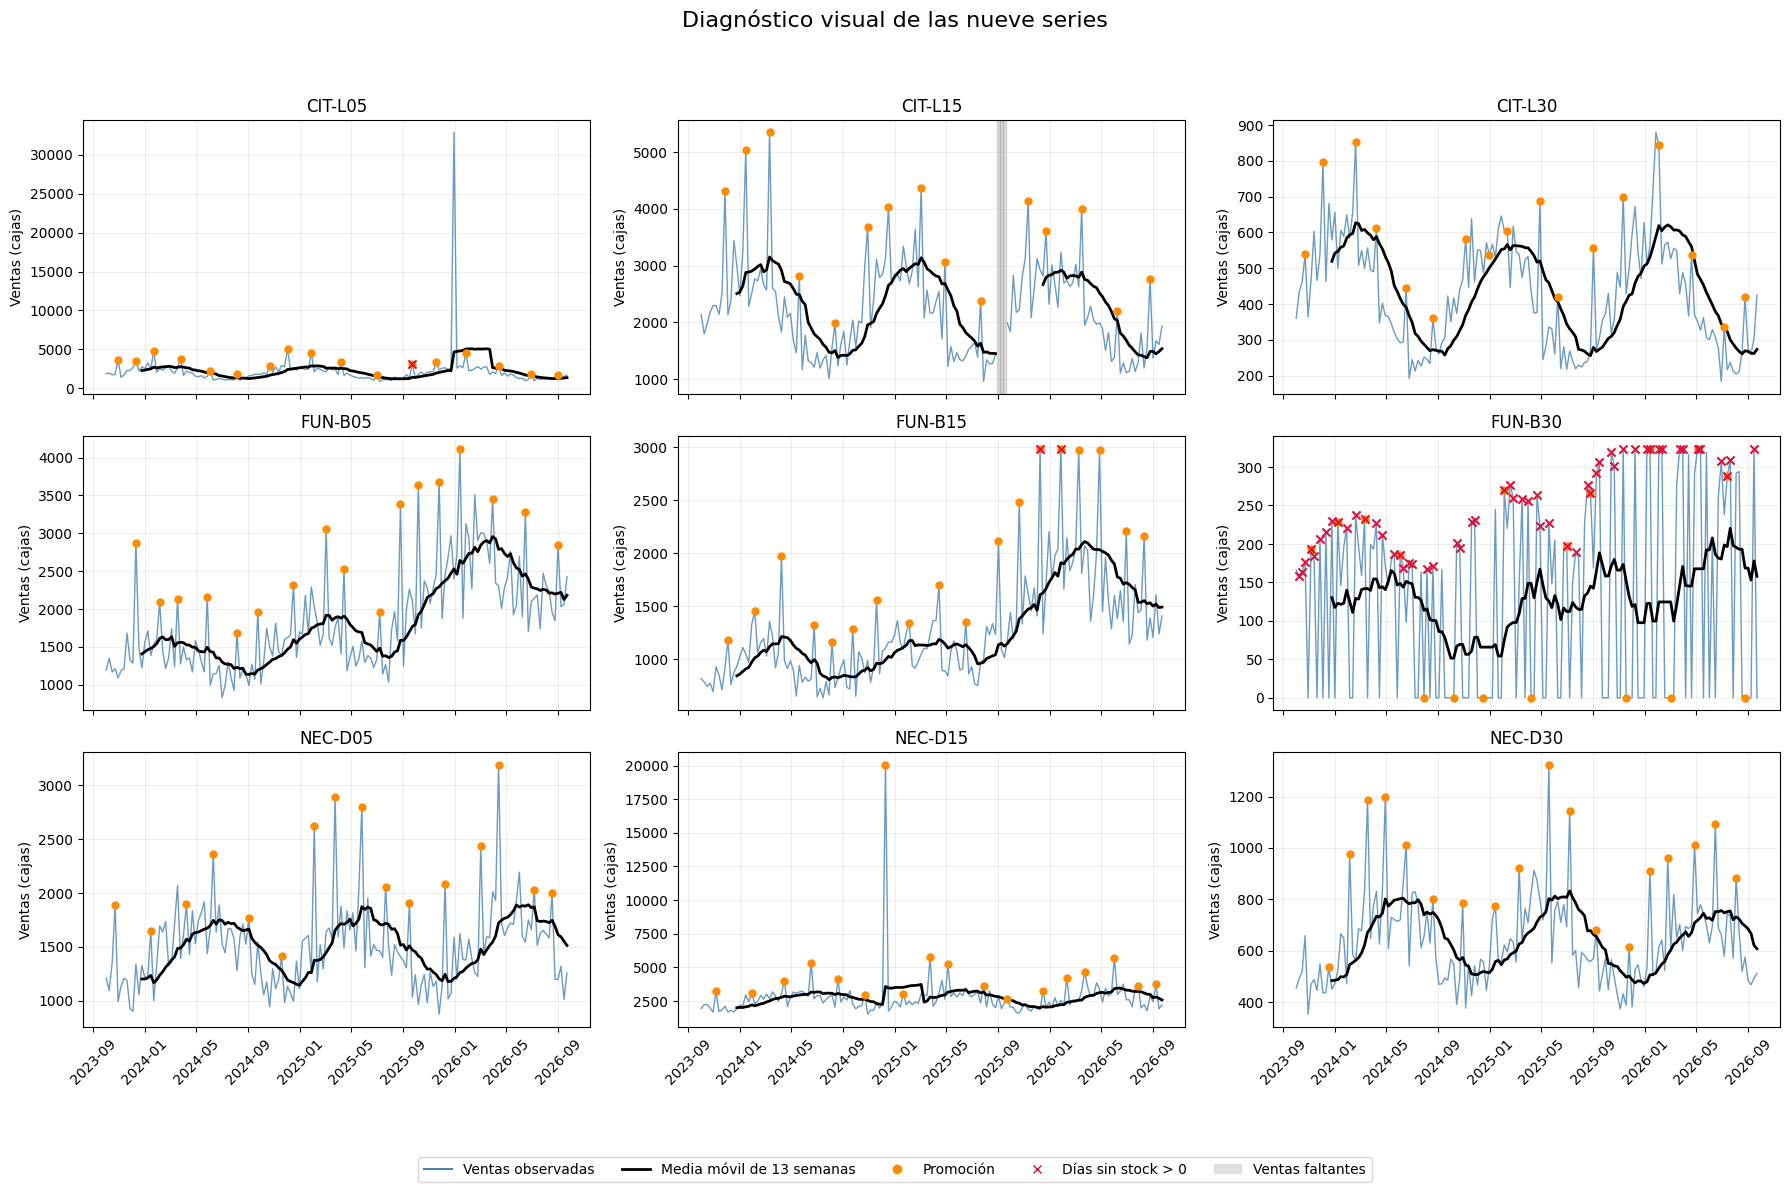

In [6]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

productos = sorted(demanda["sku"].unique())

fig, ejes = plt.subplots(
    3, 3, figsize=(18, 12), sharex=True
)

for eje, sku in zip(ejes.flat, productos):
    serie = demanda.loc[demanda["sku"] == sku].sort_values(
        "fecha_lunes"
    ).copy()

    # Ventana que usa la semana actual y las 12 anteriores.
    # Exigimos las 13 ventas para no suavizar a través de faltantes.
    media_movil = serie["ventas_cajas"].rolling(
        window=13, min_periods=13
    ).mean()

    eje.plot(
        serie["fecha_lunes"], serie["ventas_cajas"],
        color="steelblue", linewidth=1, alpha=0.8
    )

    eje.plot(
        serie["fecha_lunes"], media_movil,
        color="black", linewidth=2
    )

    promociones = serie["promocion"].eq(1)
    eje.scatter(
        serie.loc[promociones, "fecha_lunes"],
        serie.loc[promociones, "ventas_cajas"],
        color="darkorange", s=25, zorder=3
    )

    sin_stock = serie["dias_sin_stock"].gt(0)
    eje.scatter(
        serie.loc[sin_stock, "fecha_lunes"],
        serie.loc[sin_stock, "ventas_cajas"],
        color="crimson", marker="x", s=35, zorder=4
    )

    fechas_faltantes = serie.loc[
        serie["ventas_faltantes_original"], "fecha_lunes"
    ]

    for fecha in fechas_faltantes:
        eje.axvspan(
            fecha - pd.Timedelta(days=3),
            fecha + pd.Timedelta(days=4),
            color="gray", alpha=0.25
        )

    eje.set_title(sku)
    eje.set_ylabel("Ventas (cajas)")
    eje.grid(alpha=0.2)
    eje.tick_params(axis="x", rotation=45)

leyenda = [
    Line2D([0], [0], color="steelblue", label="Ventas observadas"),
    Line2D([0], [0], color="black", linewidth=2,
           label="Media móvil de 13 semanas"),
    Line2D([0], [0], marker="o", color="darkorange",
           linestyle="None", label="Promoción"),
    Line2D([0], [0], marker="x", color="crimson",
           linestyle="None", label="Días sin stock > 0"),
    Patch(facecolor="gray", alpha=0.25, label="Ventas faltantes")
]

fig.suptitle("Diagnóstico visual de las nueve series", fontsize=16)
fig.legend(handles=leyenda, loc="lower center", ncol=5)
fig.tight_layout(rect=[0, 0.07, 1, 0.95])

plt.show()

In [7]:
carpeta_salidas = Path("salidas")
carpeta_salidas.mkdir(exist_ok=True)
ruta_figura = carpeta_salidas / "diagnostico_nueve_series.png"
fig.savefig(ruta_figura, dpi=200, bbox_inches="tight")
print(f"Figura guardada en: {ruta_figura.resolve()}")


Figura guardada en: /content/salidas/diagnostico_nueve_series.png


### 1.4. Revisión de picos candidatos a valores atípicos

La inspección visual mostró picos aislados de gran magnitud en CIT-L05
y NEC-D15. Se localiza la venta máxima de cada serie y se compara con
las semanas cercanas, considerando promociones, precios y días sin stock.

La magnitud del pico constituye una señal para investigar; no demuestra
por sí sola un error de registro.

In [8]:
columnas = [
    "sku", "semana", "fecha_lunes", "ventas_cajas",
    "dias_sin_stock", "promocion",
    "precio_lista_clp", "precio_efectivo_clp"
]

resumen_picos = []

for sku in ["CIT-L05", "NEC-D15"]:
    serie = demanda.loc[demanda["sku"] == sku].sort_values(
        "semana"
    )

    pico = serie.loc[serie["ventas_cajas"].idxmax()]

    contexto = serie.loc[
        serie["semana"].between(
            pico["semana"] - 4,
            pico["semana"] + 4
        )
    ]

    # Referencia exploratoria: mediana de las semanas cercanas,
    # excluyendo el propio pico y los valores faltantes.
    vecinos = contexto.loc[
        contexto["semana"] != pico["semana"], "ventas_cajas"
    ].dropna()

    mediana_local = vecinos.median()

    razon = (
        pico["ventas_cajas"] / mediana_local
        if pd.notna(mediana_local) and mediana_local > 0
        else float("nan")
    )

    resumen_picos.append({
        "sku": sku,
        "semana_pico": pico["semana"],
        "fecha": pico["fecha_lunes"],
        "ventas_pico": pico["ventas_cajas"],
        "mediana_semanas_cercanas": mediana_local,
        "veces_la_mediana": razon,
        "promocion": pico["promocion"],
        "dias_sin_stock": pico["dias_sin_stock"]
    })

    print(f"\nCONTEXTO DEL PICO DE {sku}")
    display(contexto[columnas])

print("\nRESUMEN DE LOS PICOS")
display(pd.DataFrame(resumen_picos).round(2))


CONTEXTO DEL PICO DE CIT-L05


,sku,semana,fecha_lunes,ventas_cajas,dias_sin_stock,promocion,precio_lista_clp,precio_efectivo_clp
581,CIT-L05,114,2025-12-01,2579.0,0.0,0,5320,5320
582,CIT-L05,115,2025-12-08,2609.0,0.0,0,5320,5320
583,CIT-L05,116,2025-12-15,2435.0,0.0,0,5320,5320
584,CIT-L05,117,2025-12-22,2555.0,0.0,0,5320,5320
585,CIT-L05,118,2025-12-29,32916.0,0.0,0,5320,5320
586,CIT-L05,119,2026-01-05,2584.0,0.0,0,5320,5320
587,CIT-L05,120,2026-01-12,2866.0,0.0,0,5320,5320
588,CIT-L05,121,2026-01-19,2661.0,0.0,0,5320,5320
589,CIT-L05,122,2026-01-26,4470.0,0.0,1,5320,4392



CONTEXTO DEL PICO DE NEC-D15


,sku,semana,fecha_lunes,ventas_cajas,dias_sin_stock,promocion,precio_lista_clp,precio_efectivo_clp
214,NEC-D15,59,2024-11-11,1807.0,0.0,0,9930,9930
215,NEC-D15,60,2024-11-18,2370.0,0.0,0,9930,9930
216,NEC-D15,61,2024-11-25,1966.0,0.0,0,9930,9930
217,NEC-D15,62,2024-12-02,2368.0,0.0,0,9930,9930
218,NEC-D15,63,2024-12-09,20052.0,0.0,1,9930,8170
219,NEC-D15,64,2024-12-16,1752.0,0.0,0,9930,9930
220,NEC-D15,65,2024-12-23,2046.0,0.0,0,9930,9930
221,NEC-D15,66,2024-12-30,2485.0,0.0,0,9930,9930
222,NEC-D15,67,2025-01-06,2361.0,0.0,0,9930,9930



RESUMEN DE LOS PICOS


,sku,semana_pico,fecha,ventas_pico,mediana_semanas_cercanas,veces_la_mediana,promocion,dias_sin_stock
0,CIT-L05,118,2025-12-29,32916.0,2596.5,12.68,0,0.0
1,NEC-D15,63,2024-12-09,20052.0,2203.5,9.10,1,0.0


In [9]:
for sku in ["CIT-L05", "NEC-D15"]:
    serie = demanda.loc[demanda["sku"] == sku].copy()

    print(f"\n{sku}: LAS 10 MAYORES VENTAS")
    display(
        serie.nlargest(10, "ventas_cajas")[columnas]
    )

    print(f"{sku}: RESUMEN SEGÚN PROMOCIÓN")

    resumen_promociones = serie.groupby("promocion").agg(
        semanas_con_ventas=("ventas_cajas", "count"),
        mediana_ventas=("ventas_cajas", "median"),
        maxima_venta=("ventas_cajas", "max")
    )

    display(resumen_promociones.round(2))

    print(f"{sku}: MISMA ÉPOCA EN OTROS AÑOS")

    semana_pico = serie.loc[
        serie["ventas_cajas"].idxmax(), "semana"
    ]

    comparables = serie.loc[
        serie["semana"].between(semana_pico - 52 - 2,
                                semana_pico - 52 + 2)
        | serie["semana"].between(semana_pico + 52 - 2,
                                  semana_pico + 52 + 2)
    ]

    display(comparables[columnas].sort_values("semana"))


CIT-L05: LAS 10 MAYORES VENTAS


,sku,semana,fecha_lunes,ventas_cajas,dias_sin_stock,promocion,precio_lista_clp,precio_efectivo_clp
585,CIT-L05,118,2025-12-29,32916.0,0.0,0,5320,5320
529,CIT-L05,62,2024-12-02,5097.0,0.0,1,5320,4006
484,CIT-L05,17,2024-01-22,4738.0,0.0,1,5320,4263
537,CIT-L05,70,2025-01-27,4533.0,0.0,1,5320,4254
589,CIT-L05,122,2026-01-26,4470.0,0.0,1,5320,4392
493,CIT-L05,26,2024-03-25,3809.0,0.0,1,5320,4010
472,CIT-L05,5,2023-10-30,3572.0,0.0,1,5320,3877
478,CIT-L05,11,2023-12-11,3443.0,0.0,1,5320,4115
547,CIT-L05,80,2025-04-07,3403.0,0.0,1,5320,4130
579,CIT-L05,112,2025-11-17,3321.0,0.0,1,5320,4046


CIT-L05: RESUMEN SEGÚN PROMOCIÓN


,semanas_con_ventas,mediana_ventas,maxima_venta
promocion,,,
0,139,1761.0,32916.0
1,17,3321.0,5097.0


CIT-L05: MISMA ÉPOCA EN OTROS AÑOS


...

,sku,semana,fecha_lunes,ventas_cajas,dias_sin_stock,promocion,precio_lista_clp,precio_efectivo_clp
218,NEC-D15,63,2024-12-09,20052.0,0.0,1,9930,8170
233,NEC-D15,78,2025-03-24,5750.0,0.0,1,9930,7936
295,NEC-D15,140,2026-06-01,5693.0,0.0,1,9930,7859
193,NEC-D15,38,2024-06-17,5295.0,0.0,1,9930,7047
239,NEC-D15,84,2025-05-05,5233.0,0.0,1,9930,8277
285,NEC-D15,130,2026-03-23,4677.0,0.0,1,9930,8127
279,NEC-D15,124,2026-02-09,4218.0,0.0,1,9930,7675
202,NEC-D15,47,2024-08-19,4110.0,0.0,1,9930,7173
237,NEC-D15,82,2025-04-21,4032.0,0.0,0,9930,9930
184,NEC-D15,29,2024-04-15,4016.0,0.0,1,9930,7646


NEC-D15: RESUMEN SEGÚN PROMOCIÓN


,semanas_con_ventas,mediana_ventas,maxima_venta
promocion,,,
0,138,2437.5,4032.0
1,18,3876.0,20052.0


NEC-D15: MISMA ÉPOCA EN OTROS AÑOS


,sku,semana,fecha_lunes,ventas_cajas,dias_sin_stock,promocion,precio_lista_clp,precio_efectivo_clp
164,NEC-D15,9,2023-11-27,2109.0,0.0,0,9930,9930
165,NEC-D15,10,2023-12-04,1685.0,0.0,0,9930,9930
166,NEC-D15,11,2023-12-11,1804.0,0.0,0,9930,9930
167,NEC-D15,12,2023-12-18,1693.0,0.0,0,9930,9930
168,NEC-D15,13,2023-12-25,1931.0,0.0,0,9930,9930
268,NEC-D15,113,2025-11-24,2111.0,0.0,0,9930,9930
269,NEC-D15,114,2025-12-01,1960.0,0.0,0,9930,9930
270,NEC-D15,115,2025-12-08,1844.0,0.0,0,9930,9930
271,NEC-D15,116,2025-12-15,3259.0,0.0,1,9930,8431
272,NEC-D15,117,2025-12-22,2031.0,0.0,0,9930,9930


### Resultado de la revisión de los dos picos

Detección: inspección visual, comparación con la mediana de las ocho
semanas cercanas, revisión de las mayores ventas y contraste con
promociones y períodos equivalentes de otros años.

CIT-L05: en la semana 118 se registran 32.916 cajas, equivalentes a
12,68 veces la mediana local. No hay promoción, cambio de precio
respecto de las semanas cercanas ni días sin stock registrados.
El pico supera ampliamente las restantes ventas y los valores
observados en la misma época del año anterior.

NEC-D15: en la semana 63 se registran 20.052 cajas, equivalentes a
9,10 veces la mediana local. Hay promoción, pero la venta también
supera ampliamente las otras semanas promocionales.

Interpretación: ambos registros son candidatos a valores atípicos.
Podrían corresponder a errores de registro o eventos comerciales
extraordinarios; su causa no puede confirmarse con los datos disponibles.

Tratamiento adoptado en esta etapa: conservar las ventas originales
y marcar ambos registros para seguimiento. No se eliminan, imputan
ni convierten de unidades sin evidencia adicional. Antes de modelar
se evaluará la sensibilidad de los resultados a su tratamiento.

In [10]:
demanda["pico_candidato_revision"] = (
    ((demanda["sku"] == "CIT-L05") & (demanda["semana"] == 118))
    | ((demanda["sku"] == "NEC-D15") & (demanda["semana"] == 63))
)

display(
    demanda.loc[
        demanda["pico_candidato_revision"],
        columnas + ["pico_candidato_revision"]
    ]
)

,sku,semana,fecha_lunes,ventas_cajas,dias_sin_stock,promocion,precio_lista_clp,precio_efectivo_clp,pico_candidato_revision
218,NEC-D15,63,2024-12-09,20052.0,0.0,1,9930,8170,True
585,CIT-L05,118,2025-12-29,32916.0,0.0,0,5320,5320,True


### 1.5. Detección exploratoria de valores inusuales en las nueve series

Cada venta se compara con la mediana de las 13 semanas anteriores.
La dispersión se mide mediante la desviación absoluta mediana (MAD).

Se marca como candidato un registro cuya distancia respecto de la
mediana supere 4,5 veces la MAD escalada por 1,4826. Este umbral es
un criterio exploratorio, no una prueba de error.

Se requieren al menos ocho observaciones válidas en la ventana.
Si la MAD es cero, no se calcula el indicador. Las promociones,
la estacionalidad, los cambios de nivel y los quiebres de stock
pueden generar alertas que requieren interpretación.

In [11]:


def calcular_mad(valores):
    valores = np.asarray(valores)
    valores = valores[np.isfinite(valores)]

    if len(valores) == 0:
        return np.nan

    mediana = np.median(valores)
    return np.median(np.abs(valores - mediana))

resultados = []

for sku, grupo in demanda.groupby("sku"):
    grupo = grupo.sort_values("fecha_lunes").copy()

    # shift(1) excluye la venta actual de su propia referencia.
    anteriores = grupo["ventas_cajas"].shift(1)
    ventana = anteriores.rolling(window=13, min_periods=8)

    grupo["mediana_previa"] = ventana.median()
    grupo["mad_previa"] = ventana.apply(calcular_mad, raw=True)

    escala = (1.4826 * grupo["mad_previa"]).replace(0, np.nan)

    grupo["puntaje_robusto"] = (
        grupo["ventas_cajas"] - grupo["mediana_previa"]
    ) / escala

    grupo["evaluable_filtro"] = grupo["puntaje_robusto"].notna()
    grupo["alerta_filtro"] = grupo["puntaje_robusto"].abs().gt(4.5)

    resultados.append(grupo)

revision_atipicos = pd.concat(resultados, ignore_index=True)

print("RESUMEN POR PRODUCTO")
display(
    revision_atipicos.groupby("sku").agg(
        registros=("semana", "size"),
        registros_evaluables=("evaluable_filtro", "sum"),
        alertas=("alerta_filtro", "sum")
    )
)

print("REGISTROS MARCADOS PARA REVISIÓN")
display(
    revision_atipicos.loc[
        revision_atipicos["alerta_filtro"],
        columnas + [
            "mediana_previa", "mad_previa", "puntaje_robusto"
        ]
    ].sort_values(["sku", "semana"]).round(2)
)

RESUMEN POR PRODUCTO


,registros,registros_evaluables,alertas
sku,,,
CIT-L05,156,148,11
CIT-L15,156,145,9
CIT-L30,156,148,2
FUN-B05,156,148,8
FUN-B15,156,148,3
FUN-B30,156,100,11
NEC-D05,156,148,7
NEC-D15,156,148,8
NEC-D30,156,148,6


REGISTROS MARCADOS PARA REVISIÓN


,sku,semana,fecha_lunes,ventas_cajas,dias_sin_stock,promocion,precio_lista_clp,precio_efectivo_clp,mediana_previa,mad_previa,puntaje_robusto
16,CIT-L05,17,2024-01-22,4738.0,0.0,1,5320,4263,2507.0,280.0,5.37
55,CIT-L05,56,2024-10-21,2890.0,0.0,1,5320,3987,1618.0,190.0,4.52
61,CIT-L05,62,2024-12-02,5097.0,0.0,1,5320,4006,1981.0,225.0,9.34
69,CIT-L05,70,2025-01-27,4533.0,0.0,1,5320,4254,2526.0,203.0,6.67
78,CIT-L05,79,2025-03-31,1746.0,0.0,0,5320,5320,2451.0,99.0,-4.80
...,...,...,...,...,...,...,...,...,...,...,...
1323,NEC-D30,76,2025-03-10,923.0,0.0,1,13240,9715,567.0,28.0,8.58
1367,NEC-D30,120,2026-01-12,911.0,0.0,1,13240,10279,485.0,54.0,5.32
1373,NEC-D30,126,2026-02-23,961.0,0.0,1,13240,10656,526.0,41.0,7.16
1382,NEC-D30,135,2026-04-27,1013.0,0.0,1,13240,9849,649.0,48.0,5.11


In [12]:
alertas = revision_atipicos.loc[
    revision_atipicos["alerta_filtro"]
].copy()

alertas["direccion"] = np.where(
    alertas["puntaje_robusto"] > 0, "Alta", "Baja"
)

alertas["contexto"] = np.select(
    [
        alertas["dias_sin_stock"].isna(),
        alertas["promocion"].eq(1)
        & alertas["dias_sin_stock"].gt(0),
        alertas["dias_sin_stock"].gt(0),
        alertas["promocion"].eq(1)
    ],
    [
        "Stock desconocido",
        "Promoción y días sin stock",
        "Días sin stock",
        "Promoción"
    ],
    default="Sin promoción ni días sin stock"
)

print("RESUMEN DE ALERTAS POR CONTEXTO")
display(
    alertas.groupby(["contexto", "direccion"])
    .size()
    .rename("cantidad")
    .reset_index()
)

print("ALERTAS SIN PROMOCIÓN NI DÍAS SIN STOCK")
seleccion = alertas.loc[
    alertas["contexto"] == "Sin promoción ni días sin stock"
].sort_values(["sku", "semana"])

with pd.option_context("display.max_rows", None):
    display(
        seleccion[
            columnas + ["mediana_previa", "puntaje_robusto", "direccion"]
        ].round(2)
    )

print("RESULTADO DEL FILTRO PARA LOS DOS PICOS YA INVESTIGADOS")
display(
    revision_atipicos.loc[
        revision_atipicos["pico_candidato_revision"],
        ["sku", "semana", "puntaje_robusto", "alerta_filtro"]
    ].round(2)
)

RESUMEN DE ALERTAS POR CONTEXTO


,contexto,direccion,cantidad
0,Promoción,Alta,44
1,Promoción,Baja,1
2,Promoción y días sin stock,Alta,2
3,Sin promoción ni días sin stock,Alta,5
4,Sin promoción ni días sin stock,Baja,13


ALERTAS SIN PROMOCIÓN NI DÍAS SIN STOCK


,sku,semana,fecha_lunes,ventas_cajas,dias_sin_stock,promocion,precio_lista_clp,precio_efectivo_clp,mediana_previa,puntaje_robusto,direccion
78,CIT-L05,79,2025-03-31,1746.0,0.0,0,5320,5320,2451.0,-4.80,Baja
117,CIT-L05,118,2025-12-29,32916.0,0.0,0,5320,5320,2126.0,55.68,Alta
129,CIT-L05,130,2026-03-23,1760.0,0.0,0,5320,5320,2661.0,-5.06,Baja
167,CIT-L15,12,2023-12-18,3442.0,0.0,0,7980,7980,2178.0,7.10,Alta
261,CIT-L15,106,2025-10-06,2829.0,0.0,0,7980,7980,1407.5,5.06,Alta
363,CIT-L30,52,2024-09-23,423.0,0.0,0,10640,10640,246.0,6.28,Alta
565,FUN-B05,98,2025-08-11,1965.0,0.0,0,9920,9920,1332.0,4.85,Alta
789,FUN-B30,10,2023-12-04,0.0,0.0,0,19840,19840,166.0,-6.22,Baja
814,FUN-B30,35,2024-05-27,0.0,0.0,0,19840,19840,187.0,-5.05,Baja
820,FUN-B30,41,2024-07-08,0.0,0.0,0,19840,19840,174.0,-9.03,Baja


RESULTADO DEL FILTRO PARA LOS DOS PICOS YA INVESTIGADOS


,sku,semana,puntaje_robusto,alerta_filtro
117,CIT-L05,118,55.68,True
1154,NEC-D15,63,53.45,True


### 1.6. Diagnóstico de ventas cero y disponibilidad de stock

Se cuenta la frecuencia de ventas cero por SKU y se distingue si
coinciden con días sin stock, disponibilidad completa registrada
o información de stock faltante.

Los ceros no se reemplazan automáticamente. Su recurrencia puede
ser compatible con intermitencia, mientras que los días sin stock
pueden limitar las ventas observadas. Esta revisión no reconstruye
la demanda.

In [13]:
resumen_ceros = []

for sku, grupo in demanda.groupby("sku"):
    ventas = grupo["ventas_cajas"]
    stock = grupo["dias_sin_stock"]

    ceros = ventas.eq(0)
    observadas = ventas.notna()

    resumen_ceros.append({
        "sku": sku,
        "semanas_con_ventas_observadas": observadas.sum(),
        "semanas_ventas_cero": ceros.sum(),
        "porcentaje_ceros":
            100 * ceros.sum() / observadas.sum()
            if observadas.sum() > 0 else np.nan,
        "ceros_sin_quiebre_registrado":
            (ceros & stock.eq(0)).sum(),
        "ceros_con_dias_sin_stock":
            (ceros & stock.gt(0)).sum(),
        "ceros_con_stock_desconocido":
            (ceros & stock.isna()).sum(),
        "semanas_con_dias_sin_stock":
            stock.gt(0).sum(),
        "semanas_stock_desconocido":
            stock.isna().sum()
    })

display(
    pd.DataFrame(resumen_ceros).set_index("sku").round(2)
)

,semanas_con_ventas_observadas,semanas_ventas_cero,porcentaje_ceros,ceros_sin_quiebre_registrado,ceros_con_dias_sin_stock,ceros_con_stock_desconocido,semanas_con_dias_sin_stock,semanas_stock_desconocido
sku,,,,,,,,
CIT-L05,156,0,0.00,0,0,0,1,0
CIT-L15,153,0,0.00,0,0,0,0,3
CIT-L30,156,0,0.00,0,0,0,0,0
FUN-B05,156,0,0.00,0,0,0,0,0
FUN-B15,156,0,0.00,0,0,0,2,0
FUN-B30,156,69,44.23,69,0,0,55,0
NEC-D05,156,0,0.00,0,0,0,0,0
NEC-D15,156,0,0.00,0,0,0,0,0
NEC-D30,156,0,0.00,0,0,0,0,0


In [14]:
resumen_intermitencia = []

for sku, grupo in demanda.groupby("sku"):
    ventas = grupo["ventas_cajas"].dropna()
    positivas = ventas[ventas > 0]

    adi = (
        len(ventas) / len(positivas)
        if len(positivas) > 0 else np.nan
    )

    cv2 = (
        (positivas.std(ddof=1) / positivas.mean()) ** 2
        if len(positivas) >= 2 else np.nan
    )

    resumen_intermitencia.append({
        "sku": sku,
        "semanas_observadas": len(ventas),
        "semanas_ventas_positivas": len(positivas),
        "ADI": adi,
        "CV2_ventas_positivas": cv2
    })

display(
    pd.DataFrame(resumen_intermitencia).set_index("sku").round(3)
)

,semanas_observadas,semanas_ventas_positivas,ADI,CV2_ventas_positivas
sku,,,,
CIT-L05,156,156,1.000,1.387
CIT-L15,153,153,1.000,0.135
CIT-L30,156,156,1.000,0.126
FUN-B05,156,156,1.000,0.129
FUN-B15,156,156,1.000,0.148
FUN-B30,156,87,1.793,0.066
NEC-D05,156,156,1.000,0.065
NEC-D15,156,156,1.000,0.324
NEC-D30,156,156,1.000,0.074


### Resultado del diagnóstico de intermitencia

FUN-B30 presenta 69 semanas con ventas cero de un total de 156
(44,23 %), con ADI = 1,793 y CV² de las ventas positivas = 0,066.
Los ceros no coinciden con días sin stock registrados, por lo que
el patrón es compatible con intermitencia de ventas.

Tratamiento: se conservan los ceros como observaciones válidas.
No se sustituyen por promedios ni se consideran valores faltantes.
Las 55 semanas con días sin stock se analizarán por separado en
el punto 2. La variabilidad de las ventas positivas puede estar
limitada por esas restricciones de disponibilidad.

Los demás SKU presentan ventas positivas en todas las semanas
observadas. Los tres faltantes de CIT-L15 no se cuentan como ceros.

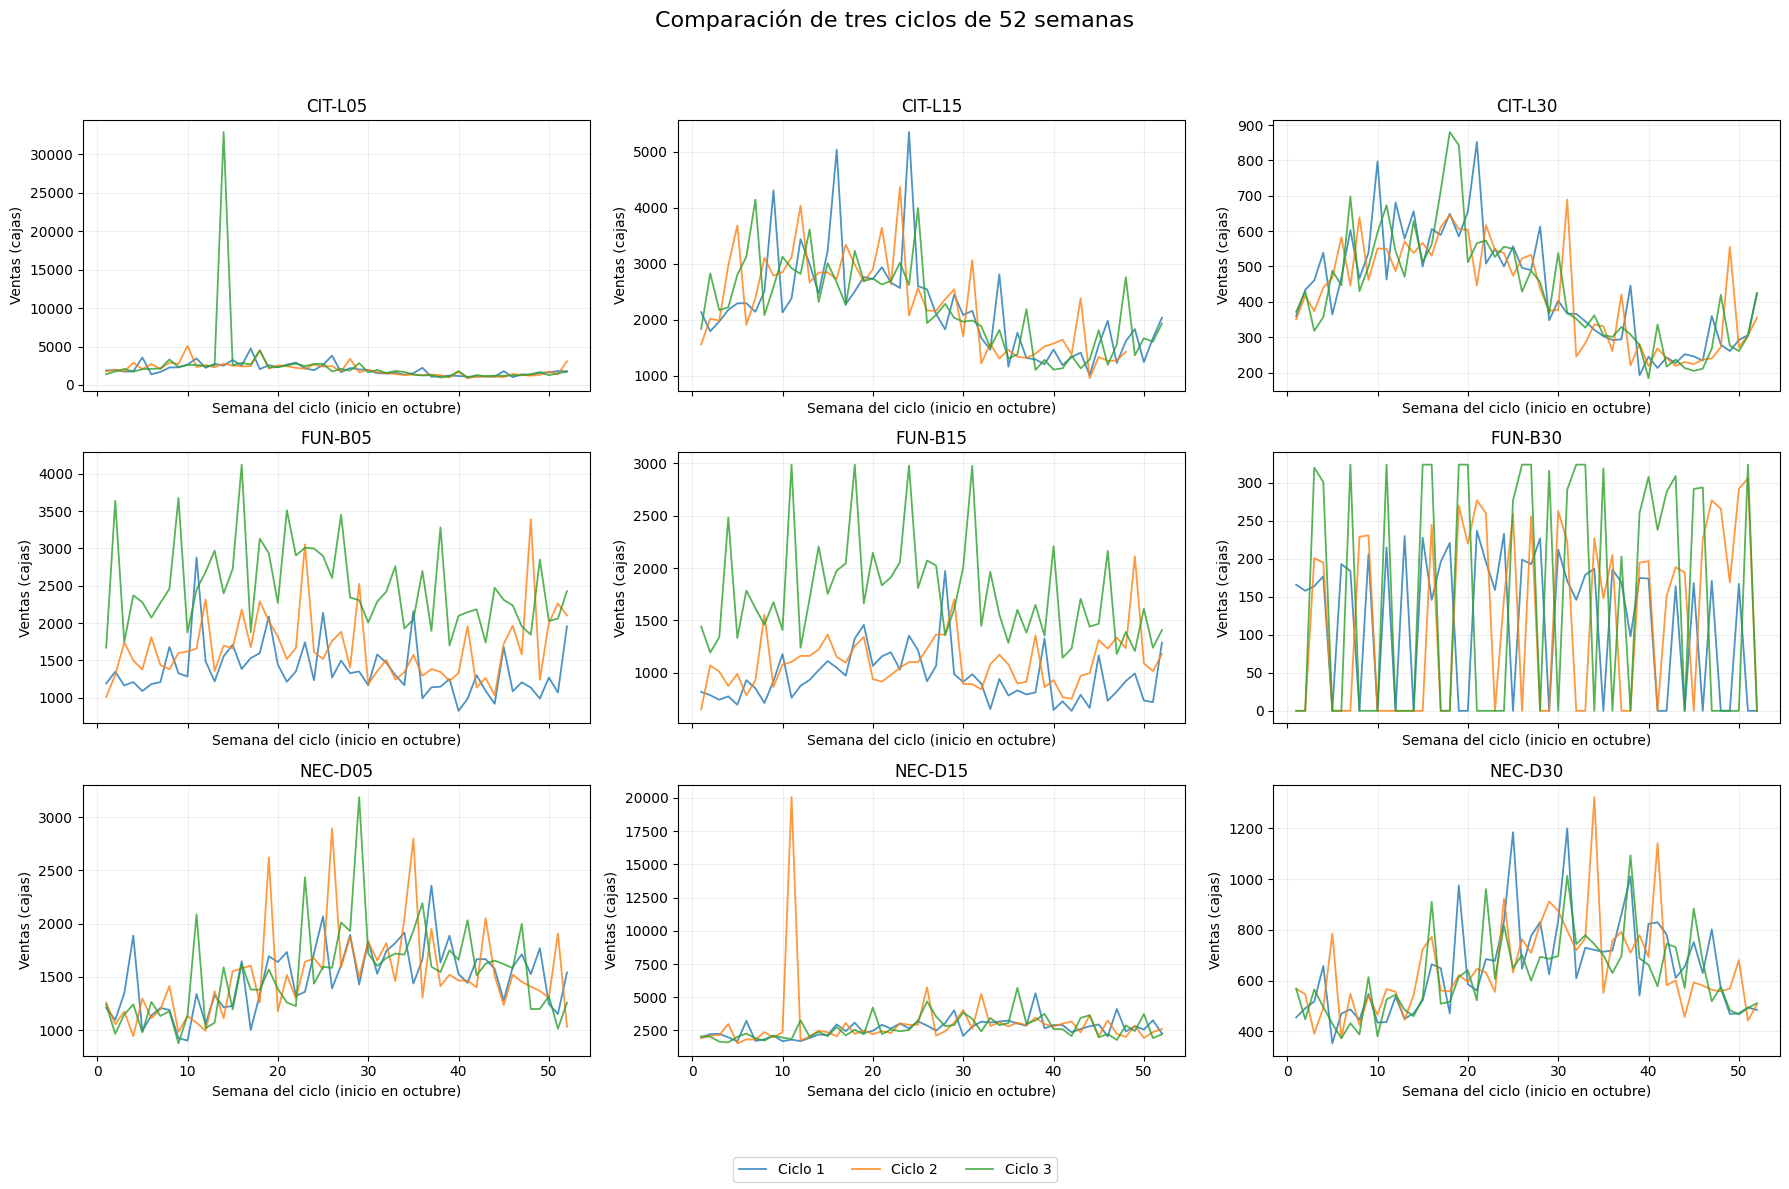

In [15]:
fig_estacional, ejes = plt.subplots(
    3, 3, figsize=(18, 12), sharex=True
)

for eje, sku in zip(ejes.flat, sorted(demanda["sku"].unique())):
    serie = demanda.loc[demanda["sku"] == sku].copy()

    # Tres bloques consecutivos de 52 semanas.
    serie["ciclo"] = ((serie["semana"] - 1) // 52) + 1
    serie["semana_del_ciclo"] = ((serie["semana"] - 1) % 52) + 1

    for ciclo, grupo in serie.groupby("ciclo"):
        grupo = grupo.sort_values("semana_del_ciclo")

        eje.plot(
            grupo["semana_del_ciclo"],
            grupo["ventas_cajas"],
            linewidth=1.3,
            alpha=0.8,
            label=f"Ciclo {int(ciclo)}"
        )

    eje.set_title(sku)
    eje.set_xlabel("Semana del ciclo (inicio en octubre)")
    eje.set_ylabel("Ventas (cajas)")
    eje.grid(alpha=0.2)

handles, labels = ejes.flat[0].get_legend_handles_labels()
fig_estacional.legend(
    handles, labels, loc="lower center", ncol=3
)

fig_estacional.suptitle(
    "Comparación de tres ciclos de 52 semanas", fontsize=16
)
fig_estacional.tight_layout(rect=[0, 0.06, 1, 0.95])
plt.show()

In [16]:
resumen_estacional = []

for sku, grupo in demanda.groupby("sku"):
    grupo = grupo.copy()

    grupo["ciclo"] = ((grupo["semana"] - 1) // 52) + 1
    grupo["semana_del_ciclo"] = ((grupo["semana"] - 1) % 52) + 1

    tabla = grupo.pivot(
        index="semana_del_ciclo",
        columns="ciclo",
        values="ventas_cajas"
    )

    for ciclo_a, ciclo_b in [(1, 2), (2, 3), (1, 3)]:
        pares = tabla[[ciclo_a, ciclo_b]].dropna()

        correlacion = (
            pares[ciclo_a].corr(pares[ciclo_b], method="spearman")
            if len(pares) >= 3
            and pares[ciclo_a].nunique() > 1
            and pares[ciclo_b].nunique() > 1
            else np.nan
        )

        resumen_estacional.append({
            "sku": sku,
            "comparacion": f"Ciclo {ciclo_a} vs {ciclo_b}",
            "semanas_comparables": len(pares),
            "correlacion_spearman": correlacion
        })

resultado_estacional = pd.DataFrame(resumen_estacional)

display(
    resultado_estacional.pivot(
        index="sku",
        columns="comparacion",
        values="correlacion_spearman"
    ).round(3)
)

print("NÚMERO DE SEMANAS COMPARABLES")
display(
    resultado_estacional.pivot(
        index="sku",
        columns="comparacion",
        values="semanas_comparables"
    )
)

comparacion,Ciclo 1 vs 2,Ciclo 1 vs 3,Ciclo 2 vs 3
sku,,,
CIT-L05,0.687,0.736,0.777
CIT-L15,0.681,0.699,0.655
CIT-L30,0.718,0.860,0.781
FUN-B05,0.355,0.361,0.132
FUN-B15,0.321,0.252,0.034
FUN-B30,-0.047,-0.072,0.045
NEC-D05,0.483,0.551,0.485
NEC-D15,0.298,0.382,0.274
NEC-D30,0.562,0.743,0.635


NÚMERO DE SEMANAS COMPARABLES


comparacion,Ciclo 1 vs 2,Ciclo 1 vs 3,Ciclo 2 vs 3
sku,,,
CIT-L05,52,52,52
CIT-L15,49,52,49
CIT-L30,52,52,52
FUN-B05,52,52,52
FUN-B15,52,52,52
FUN-B30,52,52,52
NEC-D05,52,52,52
NEC-D15,52,52,52
NEC-D30,52,52,52


### 1.7. Comparación del nivel de ventas entre ciclos

Se comparan semanas separadas por 52 períodos, con igual indicador
de promoción y sin días de quiebre registrados en ambas semanas.
Se excluyen de esta comparación los dos picos previamente investigados,
sin modificar sus valores originales.

Se calcula la mediana de las razones entre ventas de ambos ciclos.
Este análisis describe cambios de nivel; no identifica por sí solo
un quiebre estructural ni demuestra su causa.

In [17]:
resumen_nivel = []

for sku, grupo in demanda.groupby("sku"):
    grupo = grupo.sort_values("semana").set_index("semana")

    for ciclo_anterior, ciclo_actual in [(1, 2), (2, 3)]:
        razones = []

        inicio = (ciclo_actual - 1) * 52 + 1
        fin = ciclo_actual * 52

        for semana in range(inicio, fin + 1):
            actual = grupo.loc[semana]
            anterior = grupo.loc[semana - 52]

            comparables = (
                pd.notna(actual["ventas_cajas"])
                and pd.notna(anterior["ventas_cajas"])
                and anterior["ventas_cajas"] > 0
                and actual["dias_sin_stock"] == 0
                and anterior["dias_sin_stock"] == 0
                and actual["promocion"] == anterior["promocion"]
                and not actual["pico_candidato_revision"]
                and not anterior["pico_candidato_revision"]
            )

            if comparables:
                razones.append(
                    actual["ventas_cajas"] / anterior["ventas_cajas"]
                )

        razon_mediana = np.median(razones) if razones else np.nan

        resumen_nivel.append({
            "sku": sku,
            "comparacion": f"Ciclo {ciclo_actual} / {ciclo_anterior}",
            "pares_utilizados": len(razones),
            "razon_mediana": razon_mediana,
            "cambio_mediano_porcentaje": 100 * (razon_mediana - 1)
        })

display(pd.DataFrame(resumen_nivel).round(3))

,sku,comparacion,pares_utilizados,razon_mediana,cambio_mediano_porcentaje
0,CIT-L05,Ciclo 2 / 1,40,0.996,-0.363
1,CIT-L05,Ciclo 3 / 2,44,1.038,3.813
2,CIT-L15,Ciclo 2 / 1,39,1.037,3.740
3,CIT-L15,Ciclo 3 / 2,39,0.975,-2.469
4,CIT-L30,Ciclo 2 / 1,40,0.989,-1.102
5,CIT-L30,Ciclo 3 / 2,41,1.033,3.346
6,FUN-B05,Ciclo 2 / 1,41,1.214,21.404
7,FUN-B05,Ciclo 3 / 2,41,1.479,47.898
8,FUN-B15,Ciclo 2 / 1,43,1.181,18.053
9,FUN-B15,Ciclo 3 / 2,40,1.541,54.079


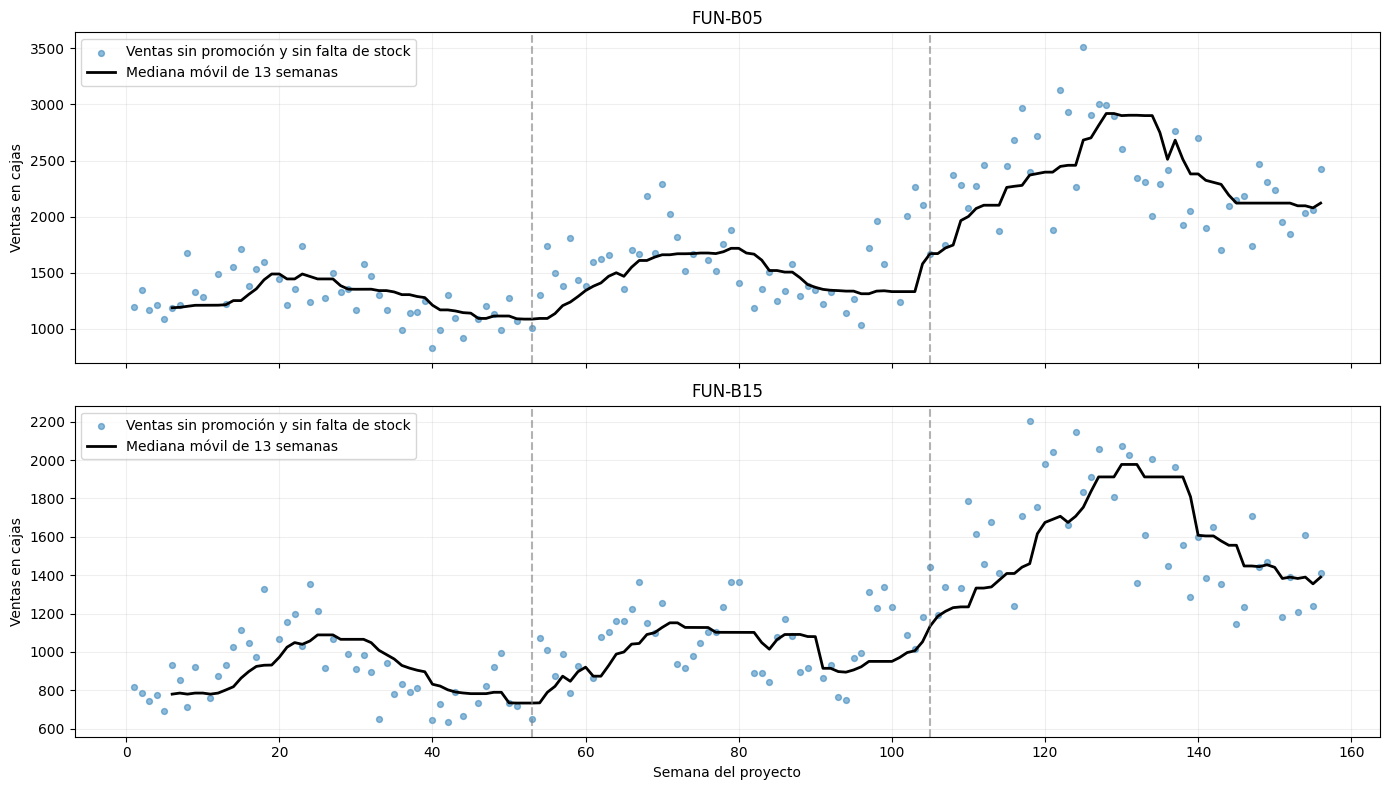

In [18]:
import matplotlib.pyplot as plt

fig_nivel, ejes = plt.subplots(
    2, 1, figsize=(14, 8), sharex=True
)

for ax, sku in zip(ejes, ["FUN-B05", "FUN-B15"]):
    serie = (
        demanda.loc[demanda["sku"] == sku]
        .sort_values("semana")
        .copy()
    )

    # Para esta comparación utilizamos semanas sin promoción
    # y sin días registrados de falta de stock.
    ventas_comparables = serie["ventas_cajas"].where(
        (serie["promocion"] == 0)
        & (serie["dias_sin_stock"] == 0)
        & (~serie["pico_candidato_revision"])
    )

    # Mediana de las últimas 13 semanas.
    nivel_local = ventas_comparables.rolling(
        window=13, min_periods=6
    ).median()

    ax.scatter(
        serie["semana"],
        ventas_comparables,
        s=18, alpha=0.5,
        label="Ventas sin promoción y sin falta de stock"
    )

    ax.plot(
        serie["semana"],
        nivel_local,
        color="black", linewidth=2,
        label="Mediana móvil de 13 semanas"
    )

    for limite in [53, 105]:
        ax.axvline(
            limite, color="gray",
            linestyle="--", alpha=0.6
        )

    ax.set_title(sku)
    ax.set_ylabel("Ventas en cajas")
    ax.grid(alpha=0.2)
    ax.legend()

ejes[-1].set_xlabel("Semana del proyecto")
plt.tight_layout()
plt.show()

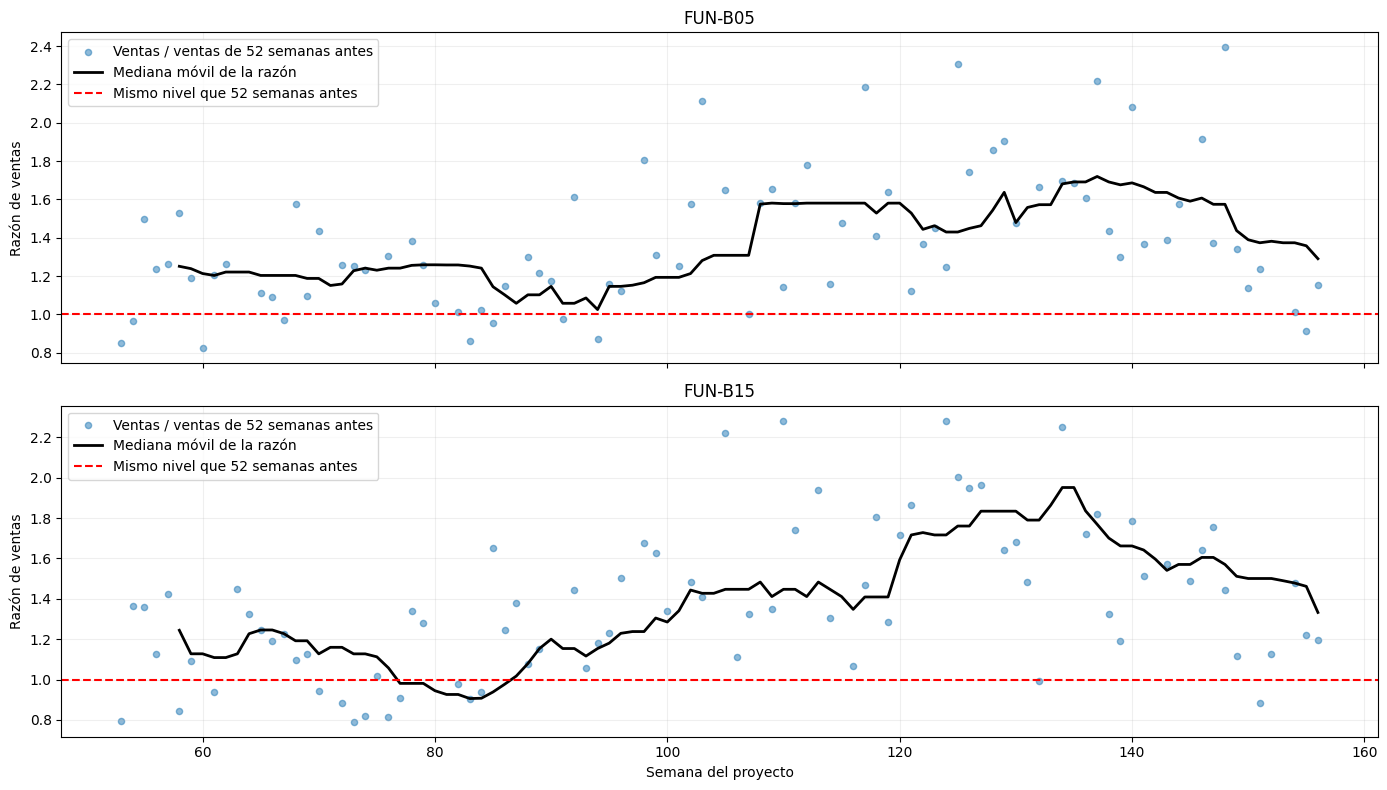

In [19]:
fig_comparacion, ejes = plt.subplots(
    2, 1, figsize=(14, 8), sharex=True
)

for ax, sku in zip(ejes, ["FUN-B05", "FUN-B15"]):
    serie = (
        demanda.loc[demanda["sku"] == sku]
        .sort_values("semana")
        .set_index("semana")
    )

    ventas = serie["ventas_cajas"]

    semana_valida = (
        ventas.notna()
        & (serie["promocion"] == 0)
        & (serie["dias_sin_stock"] == 0)
        & (~serie["pico_candidato_revision"])
    )

    pares_validos = (
        semana_valida
        & semana_valida.shift(52, fill_value=False)
        & (ventas.shift(52) > 0)
    )

    razon = (ventas / ventas.shift(52)).where(pares_validos)

    razon_suavizada = razon.rolling(
        window=13, min_periods=6
    ).median()

    ax.scatter(
        serie.index, razon,
        s=20, alpha=0.5,
        label="Ventas / ventas de 52 semanas antes"
    )

    ax.plot(
        serie.index, razon_suavizada,
        color="black", linewidth=2,
        label="Mediana móvil de la razón"
    )

    ax.axhline(
        1, color="red", linestyle="--",
        label="Mismo nivel que 52 semanas antes"
    )

    ax.set_title(sku)
    ax.set_ylabel("Razón de ventas")
    ax.grid(alpha=0.2)
    ax.legend()

ejes[-1].set_xlabel("Semana del proyecto")
plt.tight_layout()
plt.show()

## Cambios de nivel en FUN-B05 y FUN-B15
Detección: se revisaron los gráficos de ventas, las medianas móviles de 13 semanas y las razones entre las ventas de cada semana y las de 52 semanas antes. Para estas últimas comparaciones se utilizaron pares de semanas sin promoción, sin días registrados de falta de stock y con ventas disponibles.
Hallazgo: ambas series presentan un aumento sostenido del nivel de ventas, especialmente durante el tercer ciclo. En los pares comparables, el aumento mediano respecto del segundo ciclo fue de 47,9 % para FUN-B05 y de 54,1 % para FUN-B15. Los resultados son compatibles con un cambio de nivel, aunque no permiten establecer una fecha exacta de quiebre.
Posible causa: crecimiento de la demanda, ampliación de la distribución o incorporación de clientes. Estas son hipótesis; los datos revisados no permiten confirmar una causa.
Tratamiento: se conservaron las observaciones sin reemplazarlas ni eliminarlas, porque el aumento sostenido no constituye por sí solo un error de registro. En la etapa de modelación se evaluará cómo representar este cambio y su efecto sobre los pronósticos.

In [20]:
base_promociones = demanda.loc[
    demanda["ventas_cajas"].notna()
    & (demanda["dias_sin_stock"] == 0)
    & (~demanda["pico_candidato_revision"])
].copy()

resumen_promociones = []

for sku, grupo in base_promociones.groupby("sku"):
    sin_promo = grupo.loc[grupo["promocion"] == 0]
    con_promo = grupo.loc[grupo["promocion"] == 1]

    mediana_sin = sin_promo["ventas_cajas"].median()
    mediana_con = con_promo["ventas_cajas"].median()

    razon = (
        mediana_con / mediana_sin
        if pd.notna(mediana_sin) and mediana_sin > 0
        else np.nan
    )

    precios_validos = con_promo.loc[
        (con_promo["precio_lista_clp"] > 0)
        & con_promo["precio_efectivo_clp"].notna()
    ]

    descuento = (
        100 * (
            1
            - precios_validos["precio_efectivo_clp"]
            / precios_validos["precio_lista_clp"]
        )
    ).median()

    resumen_promociones.append({
        "sku": sku,
        "semanas_sin_promo": len(sin_promo),
        "semanas_con_promo": len(con_promo),
        "mediana_sin_promo": mediana_sin,
        "mediana_con_promo": mediana_con,
        "razon_con_vs_sin": razon,
        "descuento_mediano_promo_pct": descuento
    })

tabla_promociones = pd.DataFrame(resumen_promociones)

display(tabla_promociones.round(2))

,sku,semanas_sin_promo,semanas_con_promo,mediana_sin_promo,mediana_con_promo,razon_con_vs_sin,descuento_mediano_promo_pct
0,CIT-L05,138,16,1760.5,3362.0,1.91,23.97
1,CIT-L15,138,15,2080.0,3684.0,1.77,19.41
2,CIT-L30,139,17,417.0,556.0,1.33,24.30
3,FUN-B05,139,17,1599.0,2850.0,1.78,23.18
4,FUN-B15,138,16,1099.5,1629.5,1.48,22.76
5,FUN-B30,94,7,0.0,0.0,NaN,23.63
6,NEC-D05,140,16,1432.0,2042.0,1.43,25.32
7,NEC-D15,138,17,2437.5,3736.0,1.53,22.60
8,NEC-D30,138,18,579.5,942.0,1.63,22.69


##Promociones y precios
Detección: se compararon las medianas de ventas de semanas con y sin promoción para cada SKU. Se excluyeron de esta comparación los registros con ventas faltantes, días de falta de stock y los dos picos candidatos previamente identificados. También se calculó el descuento porcentual entre el precio de lista y el precio efectivo.

Hallazgo: en ocho series, las ventas medianas durante promociones fueron mayores que en semanas sin promoción, con diferencias aproximadas entre 33 % y 91 %. Los descuentos medianos promocionales estuvieron entre 19,4 % y 25,3 %. Esta asociación no constituye una estimación causal, porque también pueden influir la estacionalidad y los cambios de nivel.
Caso FUN-B30: las medianas fueron cero en ambos grupos, por lo que no se pudo calcular la razón. La intermitencia y la exclusión de semanas con falta de stock limitan esta comparación.

Tratamiento: se conservaron las ventas promocionales y las variables de promoción y precio. Una venta elevada coincidente con una promoción no se consideró automáticamente un error; los casos extremos se revisaron por separado.

### Bitácora de anomalías y decisiones

| Caso | Cómo se detectó | Hallazgo y posible causa | Tratamiento realizado |
|---|---|---|---|
| Faltantes en CIT-L15, semanas 101, 102 y 103 | Recuento de valores nulos y revisión de las semanas cercanas. | Faltan ventas y días sin stock en tres semanas consecutivas. Posible falla de registro o extracción; causa no confirmada. | Se conservaron las filas y los valores faltantes, con indicadores que permiten identificarlos. No se reemplazaron por cero ni se supuso disponibilidad de stock. La imputación para modelar queda pendiente y deberá utilizar únicamente información disponible en cada entrenamiento. |
| Pico en CIT-L05, semana 118 | Gráfico, comparación con semanas cercanas, otras temporadas y filtro robusto de mediana y MAD. | Venta de 32.916 cajas, aproximadamente 12,68 veces la mediana de las ocho semanas vecinas. No registra promoción ni días sin stock. Posible error de registro o pedido extraordinario; causa no confirmada. | Se conservó el valor original y se marcó como pico candidato a revisión. Se excluyó únicamente de las comparaciones descriptivas de nivel y promociones. No se aplicó una corrección definitiva. |
| Pico en NEC-D15, semana 63 | Gráfico, comparación con semanas cercanas, otras promociones y filtro robusto de mediana y MAD. | Venta de 20.052 cajas, aproximadamente 9,10 veces la mediana de las ocho semanas vecinas. Coincide con una promoción, pero también supera ampliamente otras ventas promocionales. Posible evento extraordinario o error de registro; causa no confirmada. | Se conservó el valor original y se marcó como pico candidato a revisión. Se excluyó únicamente de las comparaciones descriptivas de nivel y promociones. No se aplicó una corrección definitiva. |
| Otras alertas del filtro robusto en las nueve series | Desviación respecto de la mediana de las 13 semanas anteriores, escalada mediante MAD; umbral absoluto de 4,5. | El filtro produjo 65 alertas en total, incluidos los dos picos anteriores. De ellas, 47 coinciden con promociones y 18 no registran promoción ni días sin stock. Las alertas pueden reflejar promociones, estacionalidad, cambios de nivel o intermitencia; no equivalen automáticamente a errores. | Se conservaron las observaciones y el registro de alertas con su contexto. No se reemplazaron ni eliminaron datos de forma automática. |
| Ceros e intermitencia en FUN-B30 | Recuento de ventas iguales a cero, revisión de días sin stock y cálculo de ADI y CV². | Se observaron 69 semanas con ventas cero de 156, equivalentes al 44,23 %. Todas registran cero días sin stock. El ADI observado fue aproximadamente 1,79. Patrón compatible con ventas intermitentes; la causa comercial no está confirmada. | Se conservaron los ceros como ventas observadas y se distinguieron de los datos faltantes. No se interpolaron ni se sustituyeron por ventas positivas. |
| Posible cambio de nivel en FUN-B05 y FUN-B15 | Gráficos, medianas móviles y comparación con ventas de 52 semanas antes, utilizando pares comparables. | Aumento sostenido, especialmente en el tercer ciclo. El cambio mediano entre los ciclos 2 y 3 fue de +47,9 % y +54,1 %, respectivamente. Posible crecimiento comercial; no se confirmó una causa ni una fecha exacta de quiebre. | Se conservaron las ventas, porque un aumento sostenido no constituye por sí solo un error. Se documentó el cambio para considerarlo posteriormente en la modelación. |
| Ventas elevadas durante promociones | Comparación de medianas con y sin promoción y cálculo de descuentos. | En ocho series, las medianas promocionales son mayores. La promoción es una explicación posible de parte del aumento, pero la comparación no demuestra causalidad. En FUN-B30, ambas medianas son cero y la razón no se puede calcular. | Se conservaron las ventas y las variables de promoción y precio. Las observaciones extremas se revisaron por separado. |
| Semanas con falta de stock | Identificación de registros con dias_sin_stock mayor que cero. | Se detectaron 55 semanas en FUN-B30, dos en FUN-B15 y una en CIT-L05. Las ventas de estas semanas pueden estar limitadas por falta de disponibilidad y no representar toda la demanda. | Se identificaron y conservaron los registros. Se excluyeron de algunas comparaciones descriptivas. La reconstrucción de demanda corresponde al punto 2 y todavía no se ha realizado. |

Los archivos originales permanecen sin modificaciones. Conservar una observación, marcarla o excluirla de una comparación descriptiva son decisiones distintas de reemplazar su valor para entrenar un modelo. Los tratamientos pendientes se documentan explícitamente.

### Resumen del diagnóstico de las nueve series

| Serie | Tendencia y cambios de nivel | Estacionalidad | Faltantes | Valores atípicos y promociones | Intermitencia y disponibilidad |
|---|---|---|---|---|---|
| CIT-L05 | Nivel relativamente estable entre ciclos, sin aumento sostenido importante en la comparación realizada. | Patrón anual visible y repetido, con mayores ventas en verano. | Sin faltantes. | Pico candidato en semana 118: 32.916 cajas. Ventas medianas mayores durante promociones. | Sin semanas con ventas cero. Una semana con falta de stock. |
| CIT-L15 | Cambios pequeños de nivel entre ciclos comparables. | Patrón anual visible y repetido, con mayores ventas en verano. | Ventas y días sin stock faltantes en semanas 101–103. | Alertas del filtro robusto que requieren interpretación contextual. Ventas medianas mayores durante promociones. | Sin ceros entre las ventas disponibles. Disponibilidad desconocida en las tres semanas faltantes. |
| CIT-L30 | Nivel relativamente estable entre ciclos. | Patrón anual visible y repetido, con mayores ventas en verano. | Sin faltantes. | Alertas puntuales del filtro robusto. Ventas medianas mayores durante promociones. | Sin ventas cero ni días registrados de falta de stock. |
| FUN-B05 | Aumento sostenido del nivel, especialmente en el tercer ciclo; posible cambio de nivel sin fecha exacta confirmada. | Oscilaciones dentro de los ciclos, con menor repetición que las series CIT. El cambio de nivel dificulta la comparación. | Sin faltantes. | Alertas que pueden coincidir con promociones y aumentos de nivel. Ventas medianas mayores durante promociones. | Sin ventas cero ni días registrados de falta de stock. |
| FUN-B15 | Aumento sostenido del nivel, especialmente en el tercer ciclo; posible cambio de nivel sin fecha exacta confirmada. | Oscilaciones dentro de los ciclos, con poca concordancia entre sus posiciones semanales. | Sin faltantes. | Alertas del filtro robusto. Ventas medianas mayores durante promociones. | Sin ventas cero. Dos semanas con falta de stock. |
| FUN-B30 | No se establece una tendencia clara mediante las comparaciones realizadas. | Sin patrón anual claro en los gráficos y comparaciones entre ciclos. | Sin faltantes. | Varias alertas corresponden a ceros. La razón de medianas promocionales no es calculable porque ambas medianas son cero. | Ventas intermitentes: 69 semanas con cero, equivalentes al 44,23 %. Además, 55 semanas con falta de stock. |
| NEC-D05 | Cambios pequeños de nivel entre ciclos comparables. | Patrón anual visible, con mayores ventas aproximadamente en otoño e invierno. | Sin faltantes. | Alertas puntuales del filtro robusto. Ventas medianas mayores durante promociones. | Sin ventas cero ni días registrados de falta de stock. |
| NEC-D15 | Cambios pequeños de nivel entre ciclos comparables. | Patrón anual sugerido por los gráficos, con menor concordancia entre ciclos que NEC-D05 y NEC-D30. | Sin faltantes. | Pico candidato en semana 63: 20.052 cajas, coincidente con promoción. Ventas medianas mayores durante promociones. | Sin ventas cero ni días registrados de falta de stock. |
| NEC-D30 | Cambios pequeños de nivel entre ciclos comparables. | Patrón anual visible y repetido, con mayores ventas aproximadamente en otoño e invierno. | Sin faltantes. | Alertas del filtro robusto. Ventas medianas mayores durante promociones. | Sin ventas cero ni días registrados de falta de stock. |

### Alcance y decisiones del diagnóstico

El diagnóstico se realizó sobre las ventas observadas. En las semanas con falta de stock, estas pueden ser inferiores a la demanda real.

La estacionalidad y los cambios de nivel se evaluaron mediante gráficos y comparaciones descriptivas. No se confirmó una causa comercial para los cambios ni una fecha exacta de quiebre. Una alerta estadística no se consideró automáticamente un error.

Se conservaron los datos originales, los ceros observados y las ventas promocionales. Se identificaron los faltantes, los picos candidatos y las semanas con falta de stock. La imputación de faltantes y la decisión definitiva sobre los dos picos permanecen pendientes antes de entrenar los modelos.

La reconstrucción de demanda por falta de stock se abordará en el punto 2. Cualquier transformación para evaluar pronósticos deberá utilizar únicamente la información disponible dentro de cada periodo de entrenamiento.

## 2. Tratamiento de censura por falta de stock

### 2.1. Identificación de semanas censuradas

Se identifican como potencialmente censuradas las semanas con días registrados de falta de stock. En ellas, las ventas observadas pueden ser inferiores a la demanda real.

Los registros sin información de disponibilidad se mantienen separados: no se supone que tuvieron stock ni que estuvieron censurados.

In [21]:
# Creamos una copia para trabajar el punto 2.
demanda_censura = demanda.copy()

demanda_censura["estado_stock"] = np.select(
    [
        demanda_censura["dias_sin_stock"].isna(),
        demanda_censura["dias_sin_stock"] > 0
    ],
    [
        "Disponibilidad desconocida",
        "Potencialmente censurada"
    ],
    default="Sin falta de stock registrada"
)

resumen_censura = (
    demanda_censura
    .groupby(["sku", "estado_stock"])
    .size()
    .unstack(fill_value=0)
    .reindex(
        columns=[
            "Sin falta de stock registrada",
            "Potencialmente censurada",
            "Disponibilidad desconocida"
        ],
        fill_value=0
    )
)

display(resumen_censura)

semanas_censuradas = demanda_censura.loc[
    demanda_censura["dias_sin_stock"] > 0,
    [
        "sku",
        "semana",
        "fecha_lunes",
        "ventas_cajas",
        "dias_sin_stock",
        "promocion"
    ]
].sort_values(["sku", "semana"])

print(
    "Total de semanas potencialmente censuradas:",
    len(semanas_censuradas)
)

display(semanas_censuradas.head(15))

display(
    semanas_censuradas
    .groupby(["sku", "dias_sin_stock"])
    .size()
    .rename("numero_semanas")
    .reset_index()
)

estado_stock,Sin falta de stock registrada,Potencialmente censurada,Disponibilidad desconocida
sku,,,
CIT-L05,155,1,0
CIT-L15,153,0,3
CIT-L30,156,0,0
FUN-B05,156,0,0
FUN-B15,154,2,0
FUN-B30,101,55,0
NEC-D05,156,0,0
NEC-D15,156,0,0
NEC-D30,156,0,0


Total de semanas potencialmente censuradas: 58


,sku,semana,fecha_lunes,ventas_cajas,dias_sin_stock,promocion
571,CIT-L05,104,2025-09-22,3078.0,1.0,1
1206,FUN-B15,115,2025-12-08,2988.0,1.0,1
1213,FUN-B15,122,2026-01-26,2988.0,1.0,1
1249,FUN-B30,2,2023-10-09,158.0,2.0,0
1250,FUN-B30,3,2023-10-16,164.0,1.0,0
1251,FUN-B30,4,2023-10-23,177.0,1.0,0
1253,FUN-B30,6,2023-11-06,193.0,4.0,1
1254,FUN-B30,7,2023-11-13,184.0,1.0,0
1256,FUN-B30,9,2023-11-27,206.0,4.0,0
1258,FUN-B30,11,2023-12-11,215.0,3.0,0


,sku,dias_sin_stock,numero_semanas
0,CIT-L05,1.0,1
1,FUN-B15,1.0,2
2,FUN-B30,1.0,10
3,FUN-B30,2.0,21
4,FUN-B30,3.0,12
5,FUN-B30,4.0,9
6,FUN-B30,5.0,3


### 2.2. Reconstrucción proporcional por disponibilidad

Se calcula una estimación inicial de demanda multiplicando las ventas observadas por 7 / (7 − días sin stock).

El método supone siete días de posible venta por semana y una demanda diaria aproximadamente constante dentro de cada semana. No permite conocer con certeza las ventas perdidas ni representar diferencias entre días.

Las ventas originales se conservan. Los registros con disponibilidad desconocida permanecen sin reconstruir. Los ceros sin falta de stock registrada se mantienen como ceros.

In [22]:
def reconstruir_por_disponibilidad(datos):
    resultado = datos.copy()

    dias = resultado["dias_sin_stock"]
    ventas = resultado["ventas_cajas"]

    sin_censura = dias.eq(0) & ventas.notna()
    censura_parcial = dias.gt(0) & dias.lt(7) & ventas.notna()

    resultado["dias_disponibles"] = 7 - dias

    resultado["factor_disponibilidad"] = np.nan
    resultado.loc[sin_censura, "factor_disponibilidad"] = 1.0
    resultado.loc[
        censura_parcial, "factor_disponibilidad"
    ] = 7 / resultado.loc[censura_parcial, "dias_disponibles"]

    resultado["demanda_estimada_disponibilidad"] = np.nan

    resultado.loc[
        sin_censura, "demanda_estimada_disponibilidad"
    ] = ventas.loc[sin_censura]

    resultado.loc[
        censura_parcial, "demanda_estimada_disponibilidad"
    ] = (
        ventas.loc[censura_parcial]
        * resultado.loc[censura_parcial, "factor_disponibilidad"]
    )

    resultado["cajas_adicionales_estimadas"] = (
        resultado["demanda_estimada_disponibilidad"] - ventas
    )

    resultado["tratamiento_censura"] = np.select(
        [
            ventas.isna(),
            dias.isna(),
            dias.eq(7),
            censura_parcial,
            sin_censura
        ],
        [
            "Ventas faltantes: pendiente",
            "Disponibilidad desconocida: pendiente",
            "Sin disponibilidad: requiere otro método",
            "Ajuste proporcional por disponibilidad",
            "Ventas conservadas sin ajuste"
        ],
        default="Registro a revisar"
    )

    return resultado


demanda_censura = reconstruir_por_disponibilidad(demanda_censura)

columnas_revision = [
    "sku",
    "semana",
    "ventas_cajas",
    "dias_sin_stock",
    "dias_disponibles",
    "factor_disponibilidad",
    "demanda_estimada_disponibilidad",
    "cajas_adicionales_estimadas"
]

ajustes_censura = demanda_censura.loc[
    demanda_censura["dias_sin_stock"] > 0,
    columnas_revision
].sort_values(["sku", "semana"])

display(ajustes_censura.head(15).round(2))

resumen_ajustes = (
    ajustes_censura.groupby("sku")
    .agg(
        semanas_ajustadas=("semana", "size"),
        ventas_observadas=("ventas_cajas", "sum"),
        demanda_estimada=("demanda_estimada_disponibilidad", "sum"),
        cajas_adicionales=("cajas_adicionales_estimadas", "sum"),
        factor_maximo=("factor_disponibilidad", "max")
    )
)

display(resumen_ajustes.round(2))

,sku,semana,ventas_cajas,dias_sin_stock,dias_disponibles,factor_disponibilidad,demanda_estimada_disponibilidad,cajas_adicionales_estimadas
571,CIT-L05,104,3078.0,1.0,6.0,1.17,3591.00,513.00
1206,FUN-B15,115,2988.0,1.0,6.0,1.17,3486.00,498.00
1213,FUN-B15,122,2988.0,1.0,6.0,1.17,3486.00,498.00
1249,FUN-B30,2,158.0,2.0,5.0,1.40,221.20,63.20
1250,FUN-B30,3,164.0,1.0,6.0,1.17,191.33,27.33
1251,FUN-B30,4,177.0,1.0,6.0,1.17,206.50,29.50
1253,FUN-B30,6,193.0,4.0,3.0,2.33,450.33,257.33
1254,FUN-B30,7,184.0,1.0,6.0,1.17,214.67,30.67
1256,FUN-B30,9,206.0,4.0,3.0,2.33,480.67,274.67
1258,FUN-B30,11,215.0,3.0,4.0,1.75,376.25,161.25


,semanas_ajustadas,ventas_observadas,demanda_estimada,cajas_adicionales,factor_maximo
sku,,,,,
CIT-L05,1,3078.0,3591.0,513.0,1.17
FUN-B15,2,5976.0,6972.0,996.0,1.17
FUN-B30,55,13623.0,23491.3,9868.3,3.50


,resultado
Semanas censuradas con estimación,58
Estimaciones inferiores a ventas observadas,0
Semanas sin censura modificadas,0
Ceros sin censura modificados,0
Estimaciones infinitas,0
Registros sin estimación,3


Diez casos con mayor factor de ajuste:


,sku,semana,ventas_cajas,dias_sin_stock,dias_disponibles,factor_disponibilidad,demanda_estimada_disponibilidad,cajas_adicionales_estimadas
1367,FUN-B30,120,324.0,5.0,2.0,3.50,1134.00,810.00
1377,FUN-B30,130,324.0,5.0,2.0,3.50,1134.00,810.00
1339,FUN-B30,92,197.0,5.0,2.0,3.50,689.50,492.50
1378,FUN-B30,131,324.0,4.0,3.0,2.33,756.00,432.00
1383,FUN-B30,136,324.0,4.0,3.0,2.33,756.00,432.00
1320,FUN-B30,73,277.0,4.0,3.0,2.33,646.33,369.33
1318,FUN-B30,71,270.0,4.0,3.0,2.33,630.00,360.00
1326,FUN-B30,79,256.0,4.0,3.0,2.33,597.33,341.33
1256,FUN-B30,9,206.0,4.0,3.0,2.33,480.67,274.67
1253,FUN-B30,6,193.0,4.0,3.0,2.33,450.33,257.33


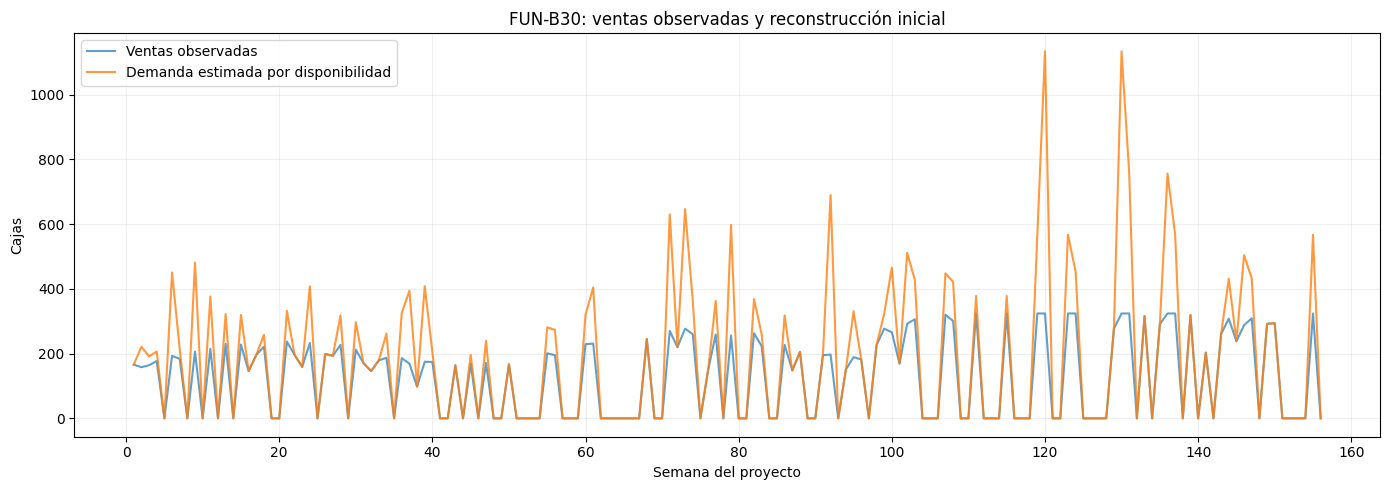

In [23]:
ventas = demanda_censura["ventas_cajas"]
estimacion = demanda_censura["demanda_estimada_disponibilidad"]
dias = demanda_censura["dias_sin_stock"]

sin_censura = dias.eq(0) & ventas.notna()
con_censura = dias.gt(0) & dias.lt(7) & ventas.notna()

ceros_sin_censura = sin_censura & ventas.eq(0)

comprobaciones = pd.Series({
    "Semanas censuradas con estimación":
        int((con_censura & estimacion.notna()).sum()),

    "Estimaciones inferiores a ventas observadas":
        int((con_censura & (estimacion < ventas)).sum()),

    "Semanas sin censura modificadas":
        int((
            sin_censura
            & ~np.isclose(estimacion, ventas, equal_nan=True)
        ).sum()),

    "Ceros sin censura modificados":
        int((
            ceros_sin_censura
            & ~estimacion.eq(0)
        ).sum()),

    "Estimaciones infinitas":
        int(np.isinf(estimacion).sum()),

    "Registros sin estimación":
        int(estimacion.isna().sum())
})

display(comprobaciones.to_frame("resultado"))

print("Diez casos con mayor factor de ajuste:")

display(
    ajustes_censura
    .sort_values(
        ["factor_disponibilidad", "cajas_adicionales_estimadas"],
        ascending=False
    )
    .head(10)
    .round(2)
)

serie = (
    demanda_censura.loc[demanda_censura["sku"] == "FUN-B30"]
    .sort_values("semana")
)

fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(
    serie["semana"],
    serie["ventas_cajas"],
    label="Ventas observadas",
    alpha=0.7
)

ax.plot(
    serie["semana"],
    serie["demanda_estimada_disponibilidad"],
    label="Demanda estimada por disponibilidad",
    alpha=0.8
)

ax.set_title("FUN-B30: ventas observadas y reconstrucción inicial")
ax.set_xlabel("Semana del proyecto")
ax.set_ylabel("Cajas")
ax.grid(alpha=0.2)
ax.legend()

plt.tight_layout()
plt.show()

In [24]:
comparacion_sensibilidad = []

for sku, grupo in demanda_censura.groupby("sku"):
    censuradas = grupo.loc[
        grupo["dias_sin_stock"].gt(0)
        & grupo["dias_sin_stock"].lt(7)
        & grupo["ventas_cajas"].notna()
    ].copy()

    if censuradas.empty:
        continue

    ventas = censuradas["ventas_cajas"]
    factor = censuradas["factor_disponibilidad"]

    escenarios = {
        "Sin ajuste": ventas,
        "Factor limitado a 2": ventas * factor.clip(upper=2),
        "Proporcional completo": ventas * factor
    }

    for nombre, valores in escenarios.items():
        comparacion_sensibilidad.append({
            "sku": sku,
            "escenario": nombre,
            "semanas": len(censuradas),
            "total_cajas": valores.sum(),
            "cajas_adicionales": (valores - ventas).sum(),
            "maximo_semanal": valores.max()
        })

tabla_sensibilidad = pd.DataFrame(comparacion_sensibilidad)

display(tabla_sensibilidad.round(2))

,sku,escenario,semanas,total_cajas,cajas_adicionales,maximo_semanal
0,CIT-L05,Sin ajuste,1,3078.00,0.00,3078.0
1,CIT-L05,Factor limitado a 2,1,3591.00,513.00,3591.0
2,CIT-L05,Proporcional completo,1,3591.00,513.00,3591.0
3,FUN-B15,Sin ajuste,2,5976.00,0.00,2988.0
4,FUN-B15,Factor limitado a 2,2,6972.00,996.00,3486.0
5,FUN-B15,Proporcional completo,2,6972.00,996.00,3486.0
6,FUN-B30,Sin ajuste,55,13623.00,0.00,324.0
7,FUN-B30,Factor limitado a 2,55,21492.47,7869.47,648.0
8,FUN-B30,Proporcional completo,55,23491.30,9868.30,1134.0


In [25]:
def preparar_censura_entrenamiento(datos, semana_corte):
    entrenamiento = datos.loc[
        datos["semana"] <= semana_corte
    ].copy()

    resultado = reconstruir_por_disponibilidad(entrenamiento)

    ventas = resultado["ventas_cajas"]
    dias = resultado["dias_sin_stock"]

    datos_validos = (
        ventas.notna()
        & dias.ge(0)
        & dias.lt(7)
    )

    resultado["objetivo_sin_ajuste"] = ventas.where(datos_validos)

    resultado["objetivo_proporcional"] = (
        resultado["demanda_estimada_disponibilidad"]
    )

    resultado["objetivo_factor_maximo_2"] = (
        ventas
        * resultado["factor_disponibilidad"].clip(upper=2)
    )

    return resultado


# Ejemplo para comprobar el corte.
# Todavía no estamos entrenando modelos.
ejemplo_entrenamiento = preparar_censura_entrenamiento(
    demanda, semana_corte=104
)

print(
    "Última semana incluida:",
    ejemplo_entrenamiento["semana"].max()
)

print(
    "Registros posteriores al corte:",
    (ejemplo_entrenamiento["semana"] > 104).sum()
)

display(
    ejemplo_entrenamiento.loc[
        ejemplo_entrenamiento["dias_sin_stock"] > 0,
        [
            "sku",
            "semana",
            "ventas_cajas",
            "dias_sin_stock",
            "objetivo_sin_ajuste",
            "objetivo_factor_maximo_2",
            "objetivo_proporcional"
        ]
    ].head(10).round(2)
)

Última semana incluida: 104
Registros posteriores al corte: 0


,sku,semana,ventas_cajas,dias_sin_stock,objetivo_sin_ajuste,objetivo_factor_maximo_2,objetivo_proporcional
571,CIT-L05,104,3078.0,1.0,3078.0,3591.00,3591.00
1249,FUN-B30,2,158.0,2.0,158.0,221.20,221.20
1250,FUN-B30,3,164.0,1.0,164.0,191.33,191.33
1251,FUN-B30,4,177.0,1.0,177.0,206.50,206.50
1253,FUN-B30,6,193.0,4.0,193.0,386.00,450.33
1254,FUN-B30,7,184.0,1.0,184.0,214.67,214.67
1256,FUN-B30,9,206.0,4.0,206.0,412.00,480.67
1258,FUN-B30,11,215.0,3.0,215.0,376.25,376.25
1260,FUN-B30,13,230.0,2.0,230.0,322.00,322.00
1262,FUN-B30,15,228.0,2.0,228.0,319.20,319.20


### 2.3. Resultados, sensibilidad y aplicación en entrenamiento

Se identificaron 58 semanas potencialmente censuradas: una en CIT-L05, dos en FUN-B15 y 55 en FUN-B30. Todas registran entre uno y cinco días sin stock.

Se implementó una reconstrucción proporcional por disponibilidad, suponiendo siete días de posible venta y una demanda diaria aproximadamente constante. Las ventas originales y los ceros sin falta de stock registrada se conservaron.

En FUN-B30, la reconstrucción proporcional elevó el total de las semanas censuradas de 13.623 a 23.491,30 cajas. El escenario con factor máximo de 2 produjo 21.492,47 cajas. Sus máximos semanales fueron 1.134 y 648 cajas, respectivamente. El límite de 2 es un escenario de sensibilidad y no un parámetro validado.

La demanda real no está disponible para comprobar directamente la precisión de estas reconstrucciones. Los resultados representan estimaciones bajo supuestos, no ventas perdidas confirmadas.

Para evaluar pronósticos, primero se seleccionará cada periodo de entrenamiento y después se aplicará la reconstrucción. Los escenarios se compararán utilizando las mismas ventanas y un criterio de evaluación común. No se elegirá un escenario comparando errores calculados contra objetivos diferentes como si fueran equivalentes.

Las ventas de semanas de evaluación sin falta de stock registrada permiten una comparación observable. En semanas censuradas, cualquier evaluación contra demanda reconstruida deberá identificarse como evaluación contra una estimación.

Los tres registros de CIT-L15 con ventas y disponibilidad faltantes permanecen pendientes de un tratamiento separado. Tampoco se han resuelto todavía las correcciones definitivas de los dos picos candidatos del punto 1.

## 3. Partición temporal y modelos

Se comparan modelos mediante validación por origen deslizante. Los candidatos incluyen ingenuo simple, ingenuo estacional, deriva, suavizamiento exponencial simple (SES), Holt, suavizamiento con estacionalidad aditiva sin tendencia y SARIMA estacional.

El modelo denominado “HW aditivo” en las tablas está configurado con trend=None: incorpora estacionalidad aditiva, pero no tendencia. Holt incorpora tendencia sin estacionalidad.

También se evalúa un SARIMAX con promoción y descuento porcentual como regresores. El precio de lista es constante dentro de cada SKU; el descuento representa la variación del precio efectivo respecto de ese precio de lista.

Como no se dispone de un calendario promocional confirmado al origen, los regresores futuros se generan mediante un escenario hipotético basado exclusivamente en el entrenamiento. Sus resultados se interpretan como una evaluación exploratoria de ese escenario, no como evidencia concluyente del aporte de un calendario comercial conocido.

En cada ventana se separan primero entrenamiento y evaluación. Después se reconstruye la demanda del entrenamiento y se imputan sus faltantes con la mediana de hasta 13 valores anteriores disponibles. Los dos picos candidatos se conservan en esta comparación inicial; su sensibilidad se revisará por separado.

Se comprueba la convergencia de SARIMA y SARIMAX antes de utilizar sus pronósticos.

In [26]:

import warnings

from statsmodels.tsa.holtwinters import (
    SimpleExpSmoothing, Holt, ExponentialSmoothing
)
from statsmodels.tsa.statespace.sarimax import SARIMAX

warnings.filterwarnings("default")

H = 13
M = 52
N_VENTANAS = 8
PASO = 5
MIN_ENTRENAMIENTO = 2 * M
OBJETIVO = "demanda_estimada_disponibilidad"


def imputar_solo_entrenamiento(y, ventana=13):
    """Imputa NaN sin usar valores posteriores ni del bloque de prueba."""
    y = pd.Series(y, dtype=float).reset_index(drop=True).copy()
    for i in y.index[y.isna()]:
        historia = y.iloc[max(0, i - ventana):i].dropna()
        if not historia.empty:
            y.iloc[i] = historia.median()
        else:
            raise ValueError("No hay historia previa para imputar el primer faltante.")
    if not np.isfinite(y.to_numpy()).all():
        raise ValueError("Persisten faltantes o infinitos tras imputar el entrenamiento.")
    return y.to_numpy(dtype=float)


def pronosticar_candidatos(y_train, h=H, periodo=M):
    """Ajusta candidatos predefinidos usando exclusivamente y_train."""
    y_train = np.asarray(y_train, dtype=float)
    if len(y_train) < 2:
        raise ValueError("Entrenamiento insuficiente.")

    pred = {
        "Ingenuo simple": np.repeat(y_train[-1], h),
        "Deriva": y_train[-1] + np.arange(1, h + 1) *
                   (y_train[-1] - y_train[0]) / (len(y_train) - 1),
    }
    if len(y_train) >= periodo:
        pred["Ingenuo estacional"] = np.resize(y_train[-periodo:], h)

    pred["SES"] = SimpleExpSmoothing(
        y_train, initialization_method="estimated"
    ).fit(optimized=True).forecast(h)
    pred["Holt"] = Holt(
        y_train, initialization_method="estimated"
    ).fit(optimized=True).forecast(h)

    if len(y_train) >= 2 * periodo:
        pred["HW aditivo"] = ExponentialSmoothing(
            y_train, trend=None, seasonal="add", seasonal_periods=periodo,
            initialization_method="estimated"
        ).fit(optimized=True).forecast(h)

        modelo_sarima = SARIMAX(
            y_train,
            order=(1, 0, 0),
            seasonal_order=(0, 1, 0, periodo),
            trend="c",
            enforce_stationarity=False,
            enforce_invertibility=False
        )

        ajuste_sarima = modelo_sarima.fit(
            disp=False, maxiter=200
        )

        if not ajuste_sarima.mle_retvals.get("converged", False):
            raise RuntimeError(
                "SARIMA no convergió. Revisar el ajuste "
                "antes de utilizar sus pronósticos."
            )

        pred["SARIMA(1,0,0)(0,1,0,52)"] = (
            ajuste_sarima.forecast(h)
        )

    # La demanda no puede ser negativa. El recorte se aplica igual a todos los folds.
    return {nombre: np.maximum(0.0, np.asarray(valores, dtype=float))
            for nombre, valores in pred.items()}


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Se evaluará el uso de SARIMAX con regresores externos como promoción, precio de lista no cambia por que es cte en los períodos y precio efectivo es afectado por las promociones, para eso evaluaremos cada cuanto historícamente hubo promociones y de cuanto fue.

In [27]:

# Resumen de variabilidad comercial por SKU
diagnostico_comercial = (
    demanda.groupby("sku")
    .agg(
        Semanas=("fecha_lunes", "count"),
        Precios_lista_distintos=("precio_lista_clp", "nunique"),
        Precios_efectivos_distintos=("precio_efectivo_clp", "nunique"),
        Semanas_promocion=("promocion", "sum"),
        Valores_promocion_distintos=("promocion", "nunique"),
    )
    .reset_index()
)

diagnostico_comercial["Porcentaje_promocion"] = (
    100 * diagnostico_comercial["Semanas_promocion"]
    / diagnostico_comercial["Semanas"]
)

display(diagnostico_comercial.round(2))

,sku,Semanas,Precios_lista_distintos,Precios_efectivos_distintos,Semanas_promocion,Valores_promocion_distintos,Porcentaje_promocion
0,CIT-L05,156,1,18,17,2,10.90
1,CIT-L15,156,1,17,16,2,10.26
2,CIT-L30,156,1,18,17,2,10.90
3,FUN-B05,156,1,18,17,2,10.90
4,FUN-B15,156,1,19,18,2,11.54
5,FUN-B30,156,1,18,17,2,10.90
6,NEC-D05,156,1,17,16,2,10.26
7,NEC-D15,156,1,19,18,2,11.54
8,NEC-D30,156,1,19,18,2,11.54


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [28]:

from IPython.display import display

H = 13
rng = np.random.default_rng(123)

# Copia de los datos originales
datos = demanda.copy()

# Asegurar formato numérico
for col in [
    "promocion",
    "precio_lista_clp",
    "precio_efectivo_clp"
]:
    datos[col] = pd.to_numeric(datos[col], errors="coerce")

# Calcular descuento porcentual
datos["descuento_pct"] = (
    100 * (
        1 - datos["precio_efectivo_clp"]
        / datos["precio_lista_clp"]
    )
)

resumen = []
escenarios = []

for sku, grupo in datos.groupby("sku"):
    grupo = grupo.sort_values("fecha_lunes").copy()

    # Últimas 13 semanas como prueba:
    # solo usamos el entrenamiento para crear el escenario
    train = grupo.iloc[:-13].copy()

    promo = train["promocion"].fillna(0)
    frecuencia = (promo == 1).mean()
    n_promos = round(frecuencia * H)

    descuentos = train.loc[
        (promo == 1)
        & train["descuento_pct"].notna()
        & (train["descuento_pct"] > 0),
        "descuento_pct"
    ].to_numpy()

    # Seleccionar semanas futuras promocionales
    posiciones = np.zeros(H, dtype=int)

    if n_promos > 0:
        elegidas = rng.choice(
            H, size=n_promos, replace=False
        )
        posiciones[elegidas] = 1

    # Asignar descuentos históricos a esas semanas
    descuentos_futuros = np.zeros(H)

    if posiciones.sum() > 0 and len(descuentos) > 0:
        descuentos_futuros[posiciones == 1] = rng.choice(
            descuentos,
            size=posiciones.sum(),
            replace=True
        )

    # Fechas posteriores al entrenamiento
    fechas = grupo["fecha_lunes"].iloc[-H:].to_numpy()

    for i in range(H):
        escenarios.append({
            "sku": sku,
            "fecha": fechas[i],
            "promocion_escenario": posiciones[i],
            "descuento_escenario_pct": round(
                descuentos_futuros[i], 2
            )
        })

    resumen.append({
        "sku": sku,
        "semanas_entrenamiento": len(train),
        "promociones_entrenamiento": int((promo == 1).sum()),
        "frecuencia_promociones_pct": round(
            frecuencia * 100, 2
        ),
        "promociones_13_semanas": int(posiciones.sum()),
        "descuento_promedio_historico_pct": round(
            descuentos.mean(), 2
        ) if len(descuentos) else np.nan
    })

tabla_resumen = pd.DataFrame(resumen)
tabla_escenarios = pd.DataFrame(escenarios)

print("RESUMEN POR SKU")
display(tabla_resumen)

print("ESCENARIO PROMOCIONAL PARA LAS PRÓXIMAS 13 SEMANAS")
display(tabla_escenarios)

RESUMEN POR SKU


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,sku,semanas_entrenamiento,promociones_entrenamiento,frecuencia_promociones_pct,promociones_13_semanas,descuento_promedio_historico_pct
0,CIT-L05,143,15,10.49,1,22.26
1,CIT-L15,143,15,10.49,1,20.29
2,CIT-L30,143,15,10.49,1,22.98
3,FUN-B05,143,16,11.19,1,22.94
4,FUN-B15,143,16,11.19,1,21.91
5,FUN-B30,143,15,10.49,1,22.39
6,NEC-D05,143,14,9.79,1,24.97
7,NEC-D15,143,16,11.19,1,21.57
8,NEC-D30,143,17,11.89,2,23.34


ESCENARIO PROMOCIONAL PARA LAS PRÓXIMAS 13 SEMANAS


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,sku,fecha,promocion_escenario,descuento_escenario_pct
0,CIT-L05,2026-06-29,1,23.98
1,CIT-L05,2026-07-06,0,0.00
2,CIT-L05,2026-07-13,0,0.00
3,CIT-L05,2026-07-20,0,0.00
4,CIT-L05,2026-07-27,0,0.00
...,...,...,...,...
112,NEC-D30,2026-08-24,0,0.00
113,NEC-D30,2026-08-31,1,25.61
114,NEC-D30,2026-09-07,1,21.12
115,NEC-D30,2026-09-14,0,0.00


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Se decidió incorporar la variable promocion como regresor externo en el modelo SARIMAX, debido a que se identificó la presencia recurrente de promociones en las nueve series analizadas. Durante los períodos de entrenamiento, la frecuencia promocional se situó entre un 9,79 % y un 11,89 % de las semanas, con descuentos promedio históricos de entre un 20,29 % y un 24,97 % respecto al precio de lista.

Estos resultados sugieren que las promociones constituyen un factor comercial potencialmente relevante para explicar variaciones en la demanda, por lo que se evaluará su aporte predictivo mediante la comparación entre SARIMA y SARIMAX.

Dado que no se dispone de un calendario comercial confirmado para las próximas 13 semanas, se construirá un escenario hipotético a partir de la frecuencia de promociones y los descuentos observados durante cada período de entrenamiento. El escenario resultante se utilizará como variable exógena futura del SARIMAX, y su desempeño se evaluará mediante validación temporal, utilizando las mismas ventanas y métricas que los demás modelos.

In [29]:

def pronosticar_sarimax_promociones(
    train_raw, y_train, h=H, periodo=M, semilla=123
):
    promo = pd.to_numeric(
        train_raw["promocion"], errors="coerce"
    ).fillna(0).to_numpy(dtype=float)

    lista = pd.to_numeric(
        train_raw["precio_lista_clp"], errors="coerce"
    )
    efectivo = pd.to_numeric(
        train_raw["precio_efectivo_clp"], errors="coerce"
    )

    descuento = (100 * (1 - efectivo / lista)).replace(
        [np.inf, -np.inf], np.nan
    )

    descuento_array = descuento.to_numpy(dtype=float)

    mascara = (
        (promo == 1)
        & np.isfinite(descuento_array)
        & (descuento_array > 0)
    )
    descuentos_hist = descuento_array[mascara]

    # Crear escenario promocional futuro usando solo el entrenamiento
    frecuencia = np.mean(promo == 1)
    n_promos = min(
        h, int(np.floor(frecuencia * h + 0.5))
    )

    rng = np.random.default_rng(semilla)
    promo_future = np.zeros(h)

    if n_promos > 0:
        posiciones = rng.choice(
            h, size=n_promos, replace=False
        )
        promo_future[posiciones] = 1

    X_train = pd.DataFrame({"promocion": promo})
    X_future = pd.DataFrame({"promocion": promo_future})

    # Incorporar descuentos si hay descuentos históricos válidos
    if len(descuentos_hist) > 0:
        X_train["descuento_pct"] = descuento.fillna(0).to_numpy()

        descuento_future = np.zeros(h)
        n_futuras = int(promo_future.sum())

        if n_futuras > 0:
            descuento_future[promo_future == 1] = rng.choice(
                descuentos_hist,
                size=n_futuras,
                replace=True
            )

        X_future["descuento_pct"] = descuento_future

    modelo = SARIMAX(
        y_train,
        exog=X_train,
        order=(1, 0, 0),
        seasonal_order=(0, 1, 0, periodo),
        trend="c",
        enforce_stationarity=False,
        enforce_invertibility=False
    )

    ajuste = modelo.fit(disp=False, maxiter=200)
    if not ajuste.mle_retvals.get("converged", False):
        raise RuntimeError(
            "SARIMAX con promociones no convergió. "
            "Revisar el ajuste antes de utilizar sus pronósticos."
        )

    pronostico = ajuste.forecast(
        steps=h,
        exog=X_future
    )

    return (
        np.maximum(0, np.asarray(pronostico, dtype=float)),
        X_future
    )



## 4. Validación por origen deslizante

Se usan ocho orígenes, horizonte `h=13` y paso de cinco semanas. La ventana es expansiva: cada fold usa todo el pasado disponible y vuelve a ajustar los modelos. La evaluación principal excluye semanas con falta de stock o ventas faltantes, porque allí la demanda real no es observable. Se reporta la cobertura para que esa exclusión sea explícita.

In [30]:
ESCENARIOS_CENSURA = [
    "Sin ajuste",
    "Factor limitado a 2",
    "Proporcional completo"
]


def preparar_objetivo_censura(train_raw, escenario):
    train = reconstruir_por_disponibilidad(train_raw)

    ventas = pd.to_numeric(
        train["ventas_cajas"], errors="coerce"
    )

    dias = pd.to_numeric(
        train["dias_sin_stock"], errors="coerce"
    )

    validos = ventas.notna() & dias.ge(0) & dias.lt(7)

    if escenario == "Sin ajuste":
        objetivo = ventas.where(validos)

    elif escenario == "Factor limitado a 2":
        objetivo = (
            ventas
            * train["factor_disponibilidad"].clip(upper=2)
        )

    elif escenario == "Proporcional completo":
        objetivo = train["demanda_estimada_disponibilidad"]

    else:
        raise ValueError(f"Escenario desconocido: {escenario}")

    return imputar_solo_entrenamiento(objetivo)


# Comprobación con un SKU y un corte.
ejemplo = (
    demanda.loc[
        (demanda["sku"] == "FUN-B30")
        & (demanda["semana"] <= 104)
    ]
    .sort_values("semana")
    .copy()
)

revision_escenarios = []

for escenario in ESCENARIOS_CENSURA:
    y = preparar_objetivo_censura(ejemplo, escenario)

    revision_escenarios.append({
        "Escenario": escenario,
        "Semanas_entrenamiento": len(y),
        "Total_cajas_entrenamiento": y.sum(),
        "Valores_no_finitos": int((~np.isfinite(y)).sum())
    })

display(pd.DataFrame(revision_escenarios).round(2))

,Escenario,Semanas_entrenamiento,Total_cajas_entrenamiento,Valores_no_finitos
0,Sin ajuste,104,12602.00,0
1,Factor limitado a 2,104,17254.67,0
2,Proporcional completo,104,18065.50,0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [31]:

registros_rolling = []
errores_rolling = []
origenes_por_sku = []

for sku, datos_sku in demanda.groupby("sku"):
    datos_sku = (
        datos_sku.sort_values("fecha_lunes")
        .reset_index(drop=True)
    )

    posibles_cortes = list(range(
        MIN_ENTRENAMIENTO,
        len(datos_sku) - H + 1,
        PASO
    ))
    cortes = posibles_cortes[-N_VENTANAS:]

    if len(cortes) != N_VENTANAS:
        raise ValueError(f"{sku}: faltan ventanas de evaluación.")

    for ventana, corte in enumerate(cortes, start=1):
        train_raw = datos_sku.iloc[:corte].copy()
        test_raw = datos_sku.iloc[corte:corte + H].copy()

        assert (
            train_raw["fecha_lunes"].max()
            < test_raw["fecha_lunes"].min()
        )

        real = test_raw["ventas_cajas"].to_numpy(dtype=float)
        observable = (
            test_raw["dias_sin_stock"].eq(0).to_numpy()
            & np.isfinite(real)
        )

        # Referencia común para comparar MASE entre escenarios.
        referencia = preparar_objetivo_censura(
            train_raw, "Sin ajuste"
        )
        escala_mase = np.mean(np.abs(np.diff(referencia)))

        if not np.isfinite(escala_mase) or escala_mase <= 0:
            raise ValueError(
                f"{sku}, ventana {ventana}: escala MASE inválida."
            )

        origenes_por_sku.append({
            "SKU": sku,
            "Ventana": ventana,
            "Corte": test_raw["fecha_lunes"].iloc[0],
            "N_entrenamiento": len(train_raw),
            "H": len(test_raw),
            "N_observables": int(observable.sum())
        })

        for escenario in ESCENARIOS_CENSURA:
            print(
                f"{sku} — ventana {ventana}/{N_VENTANAS}"
                f" — {escenario}",
                flush=True
            )

            y_train = preparar_objetivo_censura(
                train_raw, escenario
            )

            try:
                candidatos = pronosticar_candidatos(
                    y_train, H, M
                )

                pred_sarimax, exog_futuro = (
                    pronosticar_sarimax_promociones(
                        train_raw=train_raw,
                        y_train=y_train,
                        h=H,
                        periodo=M,
                        semilla=123 + corte
                    )
                )

                candidatos["SARIMAX con promociones"] = pred_sarimax

            except Exception as exc:
                raise RuntimeError(
                    f"{sku}, ventana {ventana}, {escenario}: {exc}"
                ) from exc

            for i in range(H):
                errores_rolling.append({
                    "SKU": sku,
                    "Ventana": ventana,
                    "Escenario_censura": escenario,
                    "Fecha": test_raw["fecha_lunes"].iloc[i],
                    "Promocion_escenario":
                        exog_futuro["promocion"].iloc[i],
                    "Descuento_escenario_pct":
                        exog_futuro["descuento_pct"].iloc[i]
                        if "descuento_pct" in exog_futuro.columns
                        else 0
                })

            for modelo, pred in candidatos.items():
                pred = np.asarray(pred, dtype=float)

                if len(pred) != H or not np.isfinite(pred).all():
                    raise ValueError(
                        f"{sku}, {modelo}, {escenario}: "
                        "pronósticos inválidos."
                    )

                for i in range(H):
                    registros_rolling.append({
                        "SKU": sku,
                        "Ventana": ventana,
                        "Corte": test_raw["fecha_lunes"].iloc[0],
                        "Fecha": test_raw["fecha_lunes"].iloc[i],
                        "Horizonte": i + 1,
                        "Modelo": modelo,
                        "Escenario_censura": escenario,
                        "Real": real[i],
                        "Pronostico": pred[i],
                        "Observable": bool(observable[i]),
                        "Escala_MASE": escala_mase
                    })

resultados_rolling = pd.DataFrame(registros_rolling)
origenes_rolling = pd.DataFrame(origenes_por_sku)
escenarios_rolling = pd.DataFrame(errores_rolling)

assert origenes_rolling.groupby("SKU")["Ventana"].nunique().eq(
    N_VENTANAS
).all()

assert resultados_rolling.groupby(
    ["SKU", "Ventana", "Escenario_censura", "Modelo"]
).size().eq(H).all()

assert resultados_rolling.groupby(
    ["SKU", "Ventana", "Modelo"]
)["Escenario_censura"].nunique().eq(3).all()

print("\nCantidad de pronósticos por escenario y modelo:")

display(
    resultados_rolling.groupby(
        ["Escenario_censura", "Modelo"]
    ).agg(
        Pronosticos=("Pronostico", "size"),
        SKUs=("SKU", "nunique"),
        Ventanas=("Ventana", "nunique")
    )
)

print(
    f"Validación completada: {N_VENTANAS} ventanas, "
    f"horizonte de {H} semanas y 3 escenarios de censura."
)


CIT-L05 — ventana 1/8 — Sin ajuste


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


CIT-L05 — ventana 1/8 — Factor limitado a 2


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


CIT-L05 — ventana 1/8 — Proporcional completo


...

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag


Cantidad de pronósticos por escenario y modelo:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Pronosticos  SKUs  Ventanas
Escenario_censura     Modelo                                              
Factor limitado a 2   Deriva                           936     9         8
                      HW aditivo                       936     9         8
                      Holt                             936     9         8
                      Ingenuo estacional               936     9         8
                      Ingenuo simple                   936     9         8
                      SARIMA(1,0,0)(0,1,0,52)          936     9         8
                      SARIMAX con promociones          936     9         8
                      SES                              936     9         8
Proporcional completo Deriva                           936     9         8
                      HW aditivo                       936     9         8
                      Holt                             936     9         8
                      Ingenuo estacional               936     9         8
                      Ingenuo simple                   936     9         8
                      SARIMA(1,0,0)(0,1,0,52)          936     9         8
                      SARIMAX con promociones          936     9         8
                      SES                              936     9         8
Sin ajuste            Deriva                           936     9         8
                      HW aditivo                       936     9         8
                      Holt                             936     9         8
                      Ingenuo estacional               936     9         8
                      Ingenuo simple                   936     9         8
                      SARIMA(1,0,0)(0,1,0,52)          936     9         8
                      SARIMAX con promociones          936     9         8
                      SES                              936     9         8

Validación completada: 8 ventanas, horizonte de 13 semanas y 3 escenarios de censura.


In [32]:
# Evaluamos las mismas ventas observables en los tres escenarios.
r = resultados_rolling.loc[
    resultados_rolling["Observable"]
].copy()

r["Error"] = r["Pronostico"] - r["Real"]
r["Error_abs"] = r["Error"].abs()
r["Error_MASE"] = r["Error_abs"] / r["Escala_MASE"]


def resumir_metricas(grupo):
    denominador = grupo["Real"].abs().sum()

    return pd.Series({
        "WAPE_pct": (
            100 * grupo["Error_abs"].sum() / denominador
            if denominador > 0 else np.nan
        ),
        "MASE": grupo["Error_MASE"].mean(),
        "Sesgo_cajas": grupo["Error"].mean(),
        "N_observaciones": len(grupo),
        "N_ventanas_con_datos": grupo["Ventana"].nunique()
    })


claves = ["SKU", "Escenario_censura", "Modelo"]

metricas_horizonte = (
    r.groupby(claves + ["Horizonte"])
    .apply(resumir_metricas, include_groups=False)
    .reset_index()
    .sort_values(claves + ["Horizonte"])
)

resumen_modelos = (
    r.groupby(claves)
    .apply(resumir_metricas, include_groups=False)
    .reset_index()
    .sort_values(
        ["SKU", "Escenario_censura", "WAPE_pct", "Modelo"]
    )
)

cobertura_horizonte = (
    resultados_rolling
    .groupby(claves + ["Horizonte"])
    .agg(
        N_ventanas_programadas=("Ventana", "nunique"),
        N_observables=("Observable", "sum")
    )
    .reset_index()
)

# Verificamos igual cantidad de datos evaluados por escenario.
assert (
    resumen_modelos.groupby(["SKU", "Modelo"])
    ["N_observaciones"].nunique().eq(1).all()
)

assert (
    cobertura_horizonte.groupby(["SKU", "Modelo", "Horizonte"])
    ["N_observables"].nunique().eq(1).all()
)

print("Métricas calculadas por SKU, escenario, modelo y horizonte.")

# Mostramos primero FUN-B30, el caso más sensible a la censura.
print("\nComparación de escenarios para FUN-B30:")

display(
    resumen_modelos.loc[
        resumen_modelos["SKU"] == "FUN-B30"
    ].round(3)
)

Métricas calculadas por SKU, escenario, modelo y horizonte.

Comparación de escenarios para FUN-B30:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,SKU,Escenario_censura,Modelo,WAPE_pct,MASE,Sesgo_cajas,N_observaciones,N_ventanas_con_datos
123,FUN-B30,Factor limitado a 2,Ingenuo estacional,210.108,1.233,71.244,70.0,8.0
127,FUN-B30,Factor limitado a 2,SES,214.606,1.274,98.461,70.0,8.0
125,FUN-B30,Factor limitado a 2,"SARIMA(1,0,0)(0,1,0,52)",226.178,1.329,93.398,70.0,8.0
126,FUN-B30,Factor limitado a 2,SARIMAX con promociones,230.928,1.360,100.242,70.0,8.0
122,FUN-B30,Factor limitado a 2,Holt,239.051,1.421,139.761,70.0,8.0
124,FUN-B30,Factor limitado a 2,Ingenuo simple,250.110,1.459,134.477,70.0,8.0
121,FUN-B30,Factor limitado a 2,HW aditivo,258.102,1.526,119.022,70.0,8.0
120,FUN-B30,Factor limitado a 2,Deriva,258.874,1.510,141.092,70.0,8.0
131,FUN-B30,Proporcional completo,Ingenuo estacional,215.775,1.266,75.201,70.0,8.0
135,FUN-B30,Proporcional completo,SES,221.543,1.315,115.491,70.0,8.0


La evaluación mediante validación de origen móvil, utilizando ocho ventanas temporales y un horizonte de pronóstico de 13 semanas, evidencia que el desempeño de los modelos depende del SKU analizado. El método Holt-Winters aditivo obtuvo el menor WAPE en cinco de los nueve productos, lo que sugiere que la incorporación de tendencia y estacionalidad puede resultar adecuada para varias de las series estudiadas. No obstante, para CIT-L05 destacó el método ingenuo estacional, para CIT-L15 el modelo SARIMAX con promociones y para NEC-D15 el suavizamiento exponencial simple.

El análisis del sesgo complementa esta comparación, ya que permite identificar tendencias de sobreestimación o subestimación que no se observan directamente en el WAPE. Algunos modelos presentan errores relativos competitivos, pero mantienen sesgos negativos, como Holt-Winters aditivo para FUN-B05 y NEC-D05. En cambio, SARIMAX con promociones para CIT-L15 presenta un sesgo promedio cercano a cero, aunque esto no demuestra por sí solo que sea superior en todos los aspectos.

El SKU FUN-B30 constituye el principal desafío de pronóstico, con WAPE superiores al 200% para todos los modelos evaluados. Este resultado debe analizarse considerando la intermitencia de la serie y los períodos sin disponibilidad de producto, que dificultan la observación de la demanda real. Por tanto, no sería adecuado seleccionar su modelo únicamente por el menor WAPE sin realizar un análisis adicional.

En conclusión, se propone seleccionar los modelos por SKU, considerando conjuntamente WAPE, MASE, sesgo y desempeño por horizonte. El MAPE puede incorporarse como métrica complementaria cuando los valores reales sean positivos y suficientemente distintos de cero. Finalmente, la elección debe considerar la estabilidad del desempeño entre ventanas y la disponibilidad de información futura, especialmente para los modelos que incorporan promociones como variables externas.

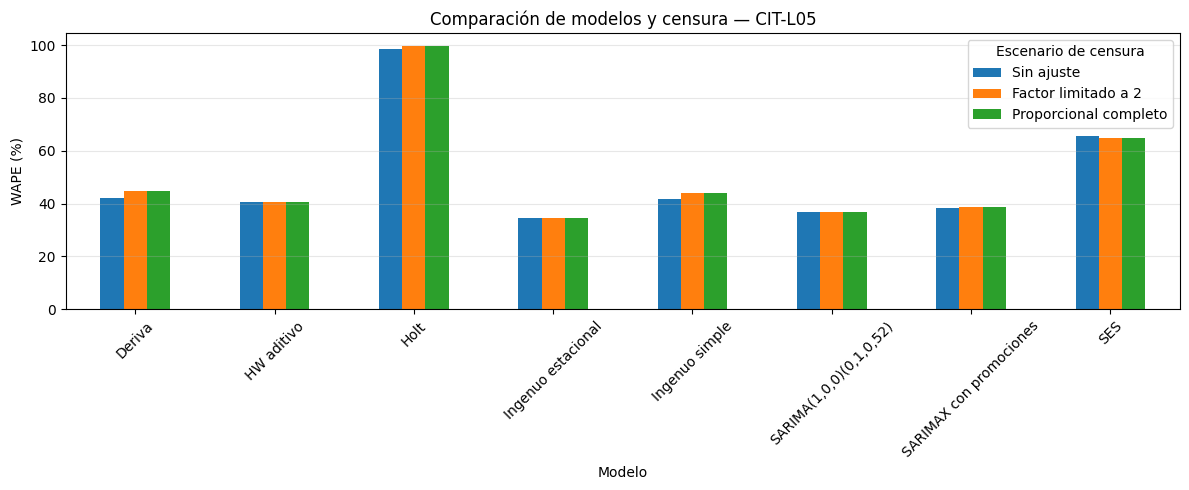

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


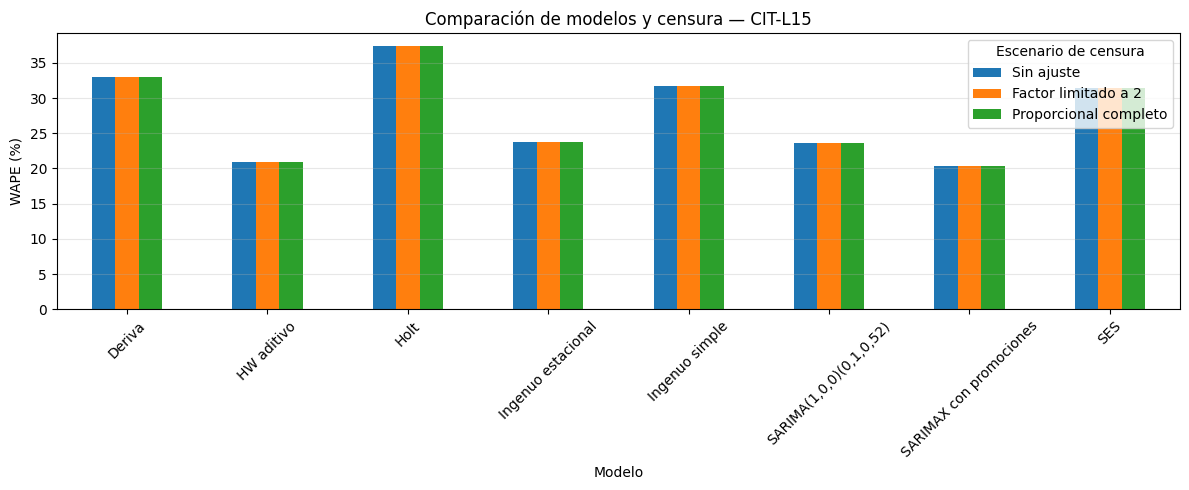

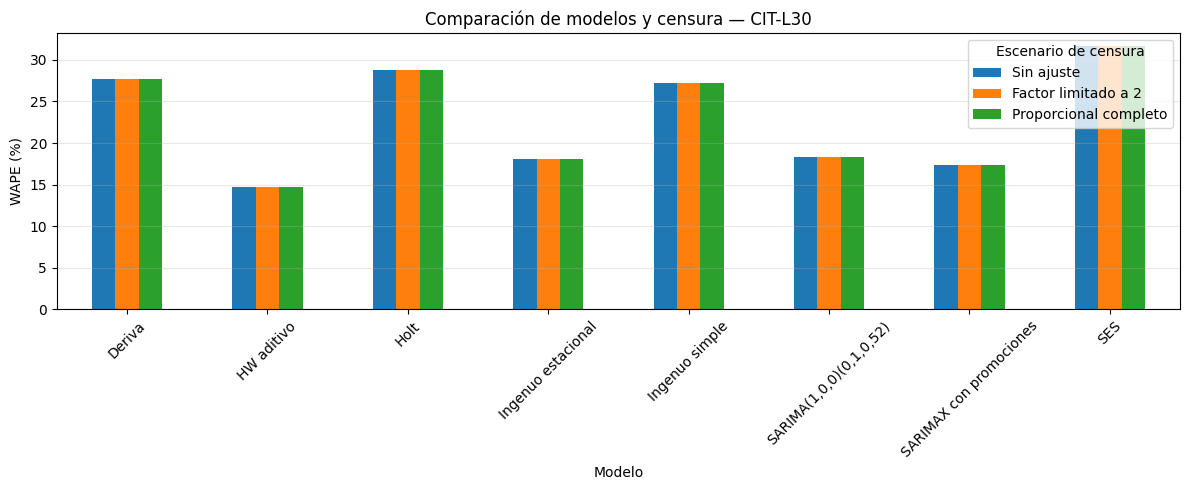

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


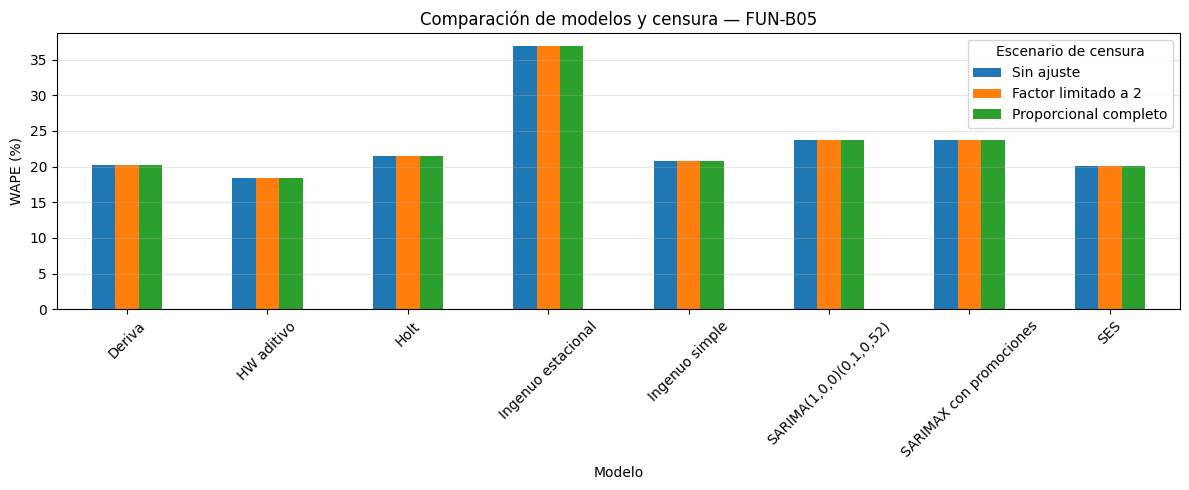

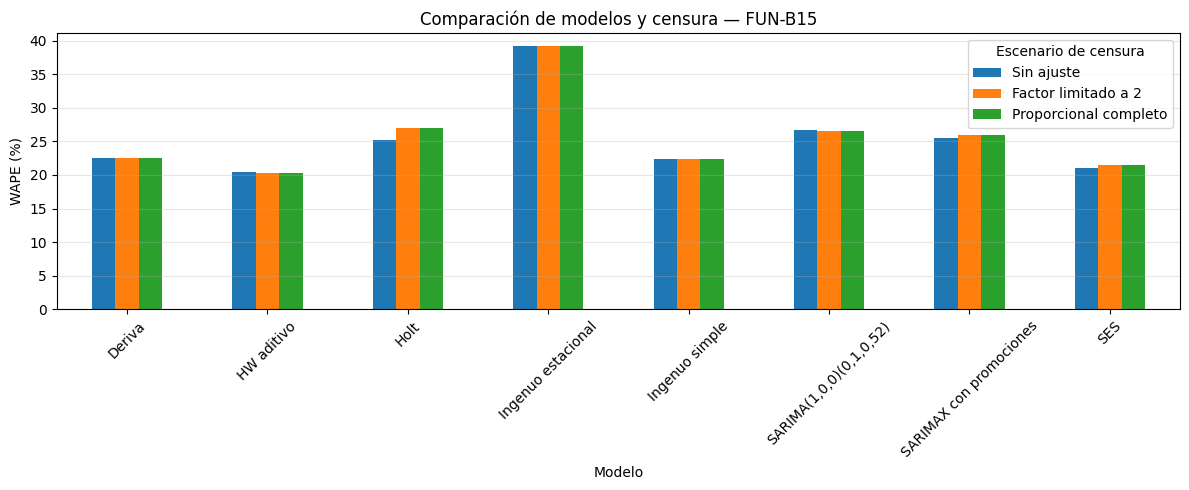

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


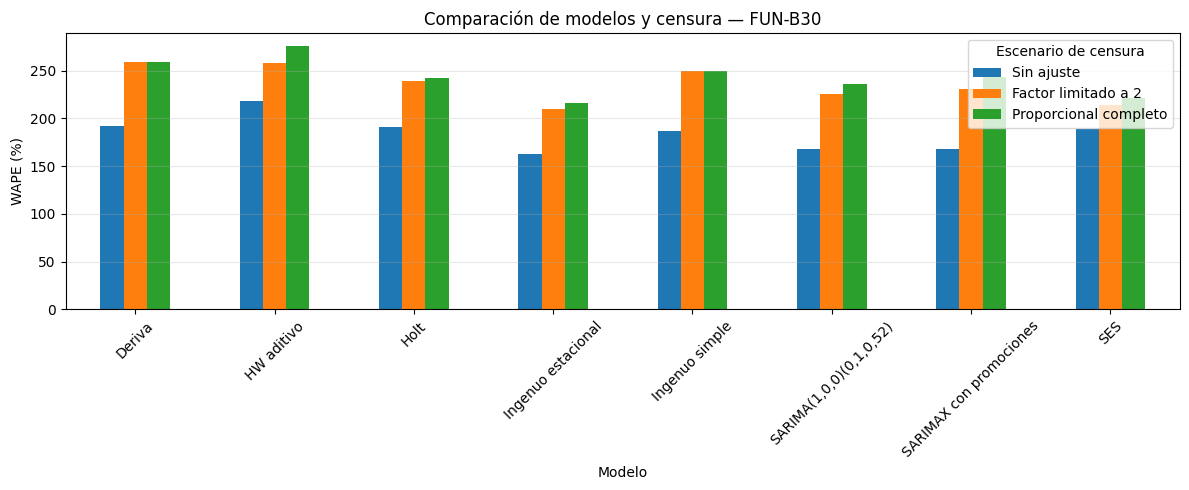

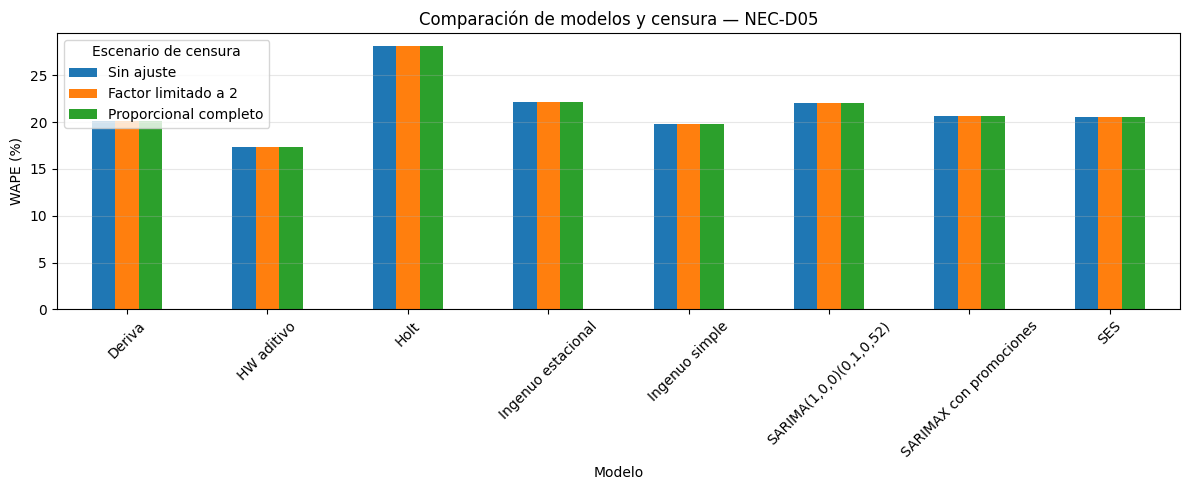

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


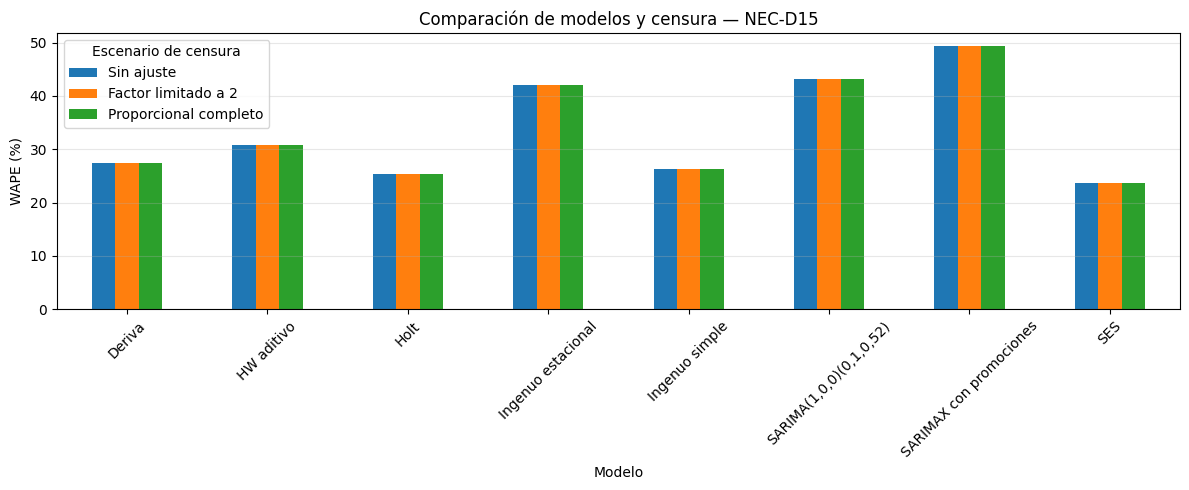

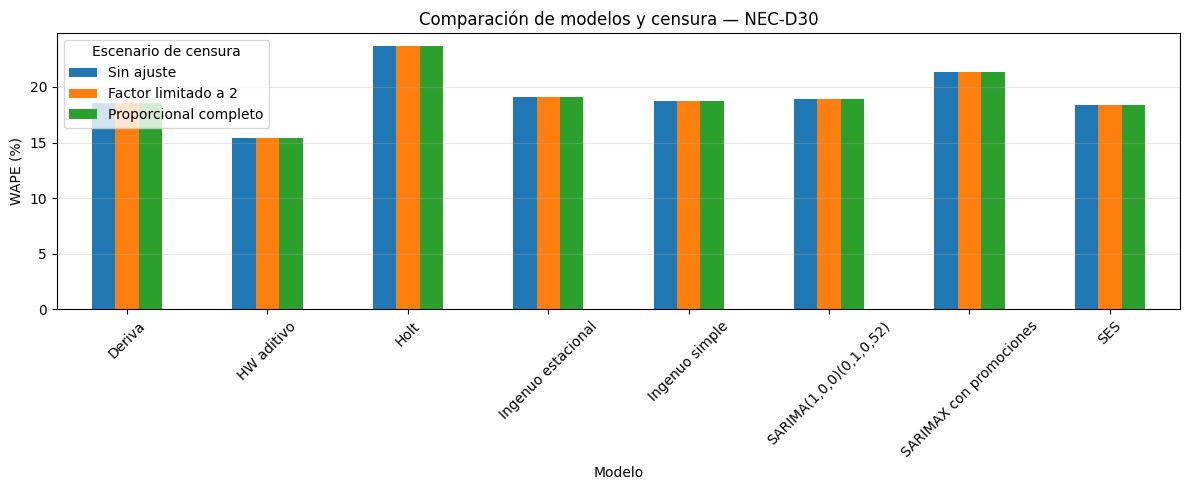

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [33]:

for sku in sorted(resumen_modelos["SKU"].unique()):
    datos = resumen_modelos.loc[
        resumen_modelos["SKU"] == sku
    ]

    tabla = datos.pivot(
        index="Modelo",
        columns="Escenario_censura",
        values="WAPE_pct"
    ).reindex(columns=ESCENARIOS_CENSURA)

    ax = tabla.plot.bar(figsize=(12, 5))

    ax.set_title(f"Comparación de modelos y censura — {sku}")
    ax.set_xlabel("Modelo")
    ax.set_ylabel("WAPE (%)")
    ax.tick_params(axis="x", rotation=45)
    ax.grid(axis="y", alpha=0.3)
    ax.legend(title="Escenario de censura")

    plt.tight_layout()
    plt.show()

In [34]:
cobertura = (
    cobertura_horizonte
    .groupby(
        ["SKU", "Escenario_censura", "Modelo"],
        as_index=False
    )
    .agg(
        Ventanas_programadas=("N_ventanas_programadas", "max"),
        Observaciones_validas=("N_observables", "sum")
    )
)

display(
    cobertura.loc[
        cobertura["SKU"] == "FUN-B30"
    ].sort_values(["Escenario_censura", "Modelo"])
)

,SKU,Escenario_censura,Modelo,Ventanas_programadas,Observaciones_validas
120,FUN-B30,Factor limitado a 2,Deriva,8,70
121,FUN-B30,Factor limitado a 2,HW aditivo,8,70
122,FUN-B30,Factor limitado a 2,Holt,8,70
123,FUN-B30,Factor limitado a 2,Ingenuo estacional,8,70
124,FUN-B30,Factor limitado a 2,Ingenuo simple,8,70
125,FUN-B30,Factor limitado a 2,"SARIMA(1,0,0)(0,1,0,52)",8,70
126,FUN-B30,Factor limitado a 2,SARIMAX con promociones,8,70
127,FUN-B30,Factor limitado a 2,SES,8,70
128,FUN-B30,Proporcional completo,Deriva,8,70
129,FUN-B30,Proporcional completo,HW aditivo,8,70


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


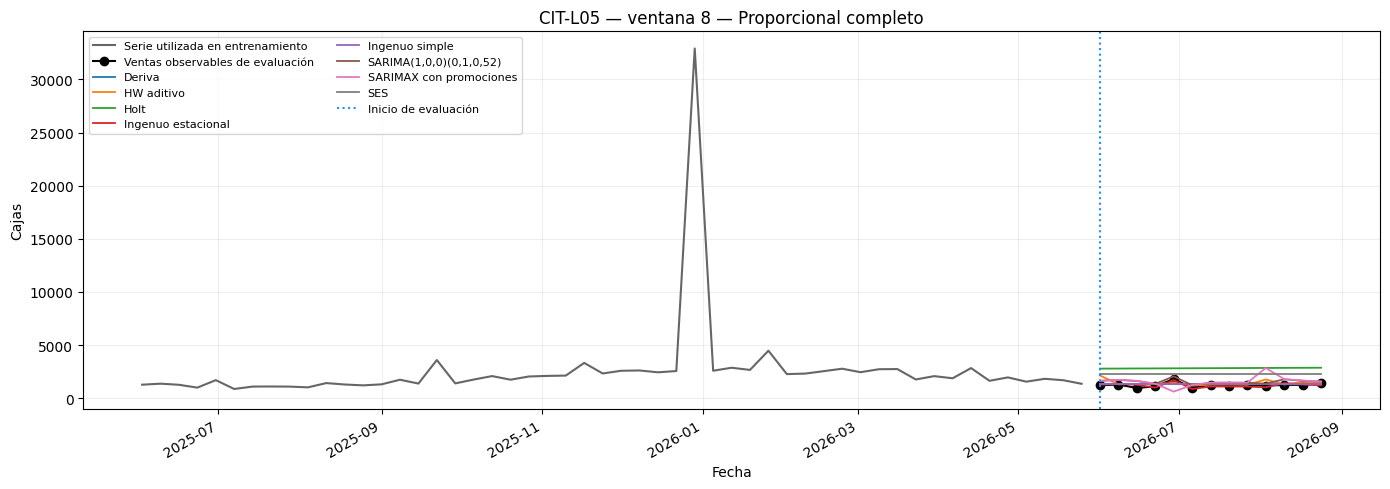

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


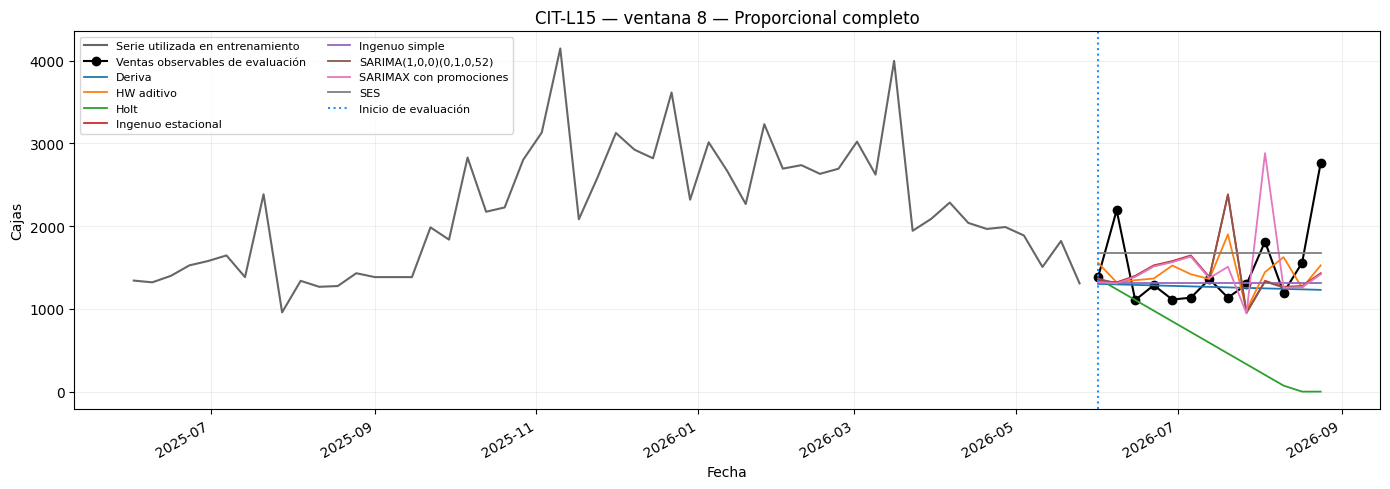

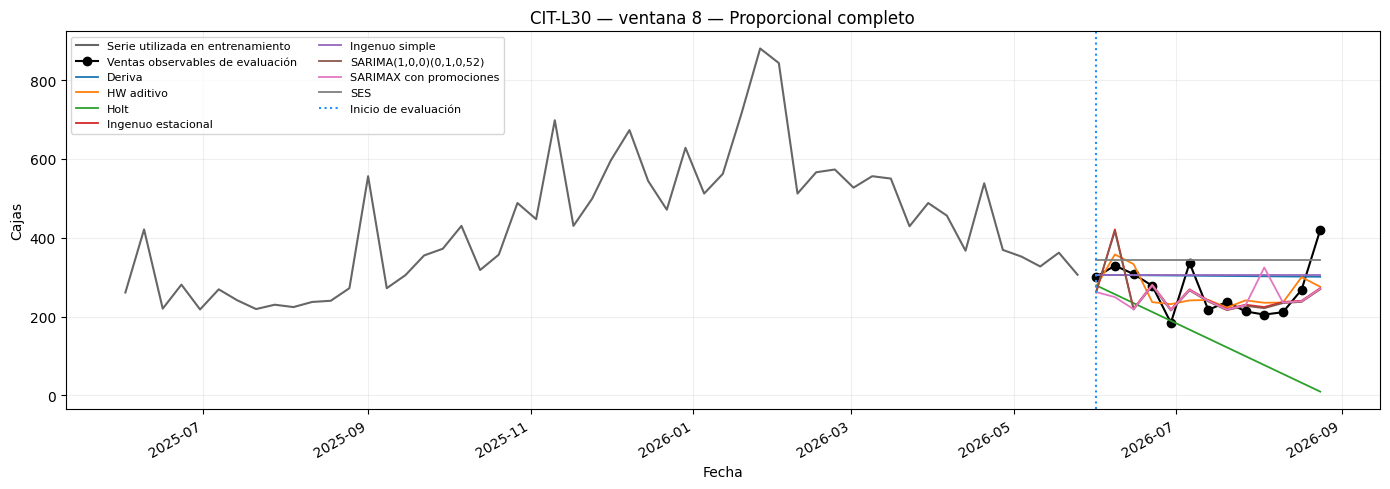

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


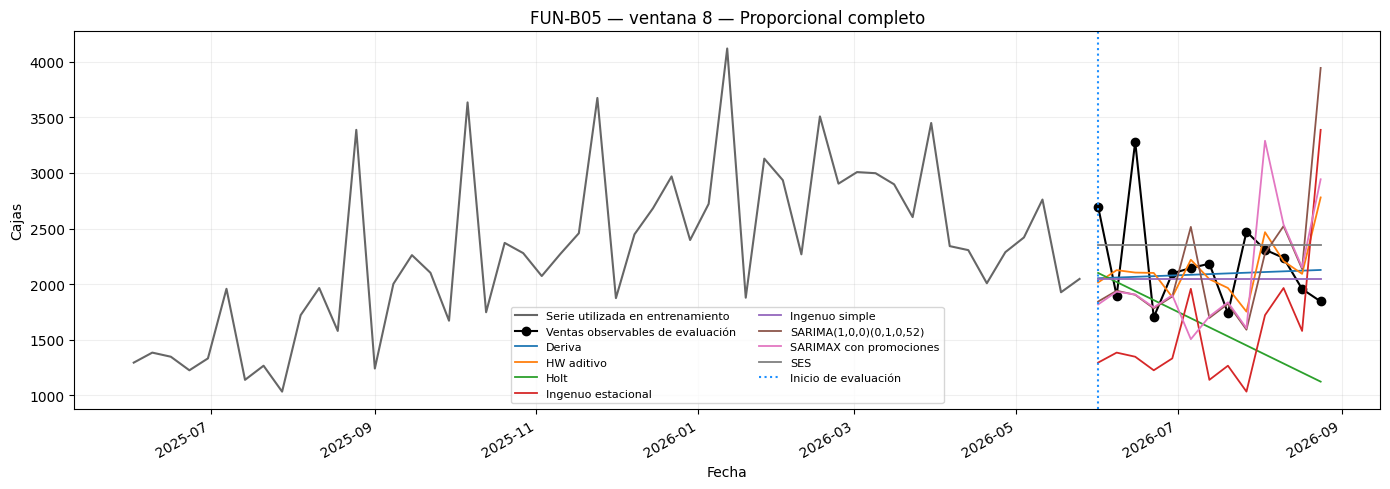

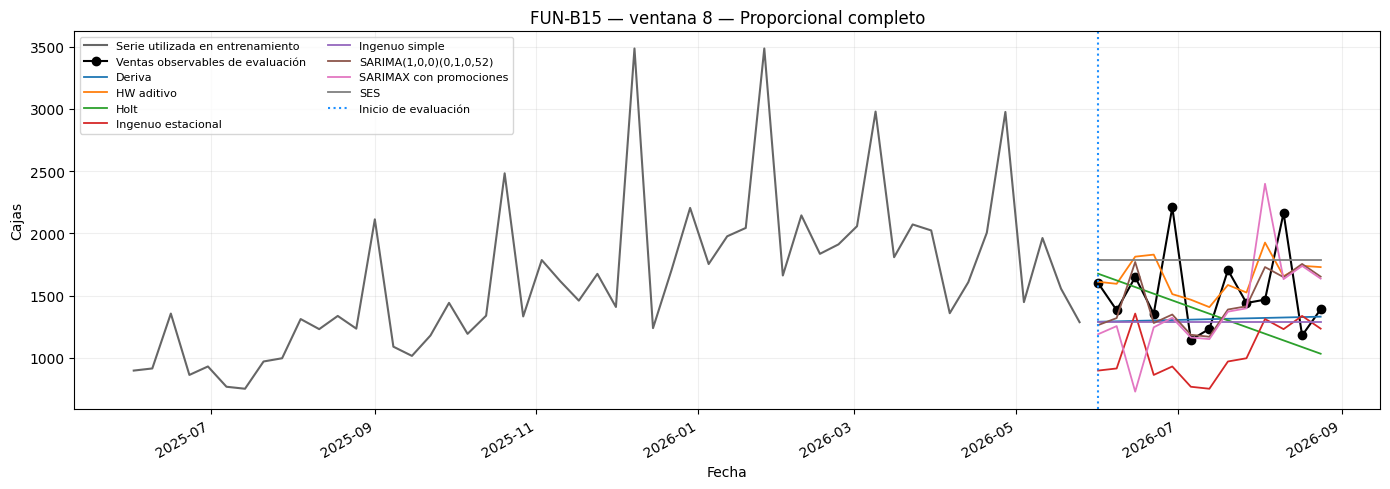

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


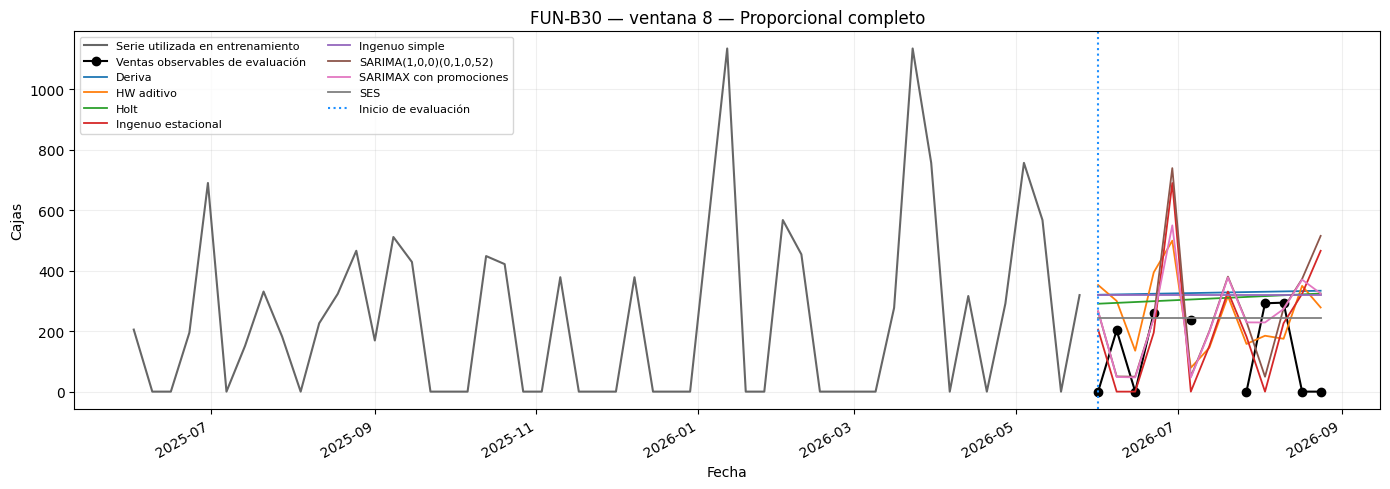

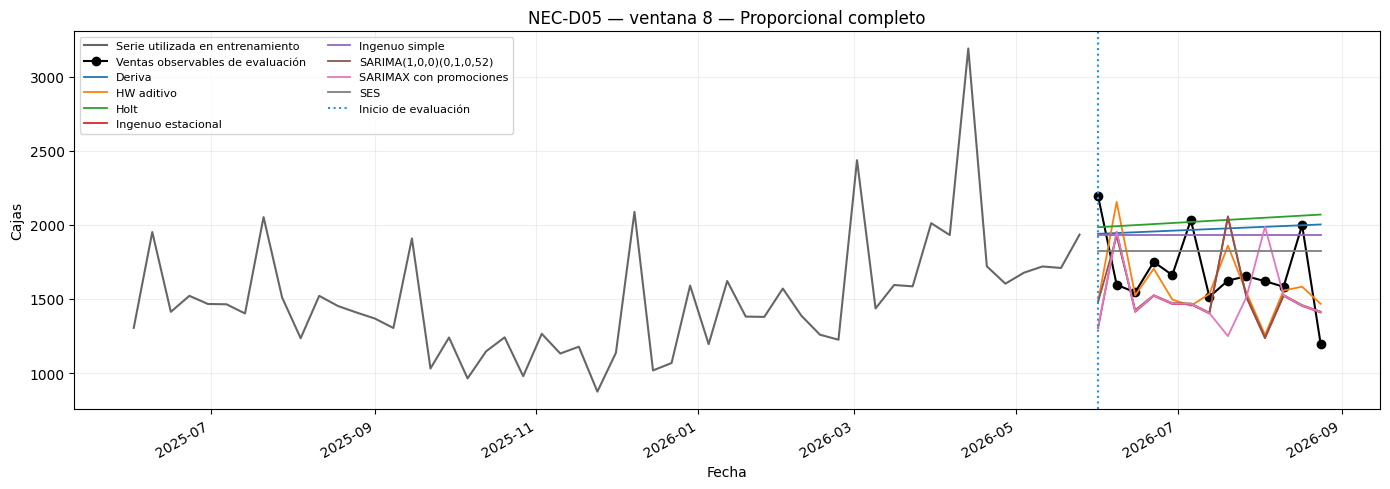

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


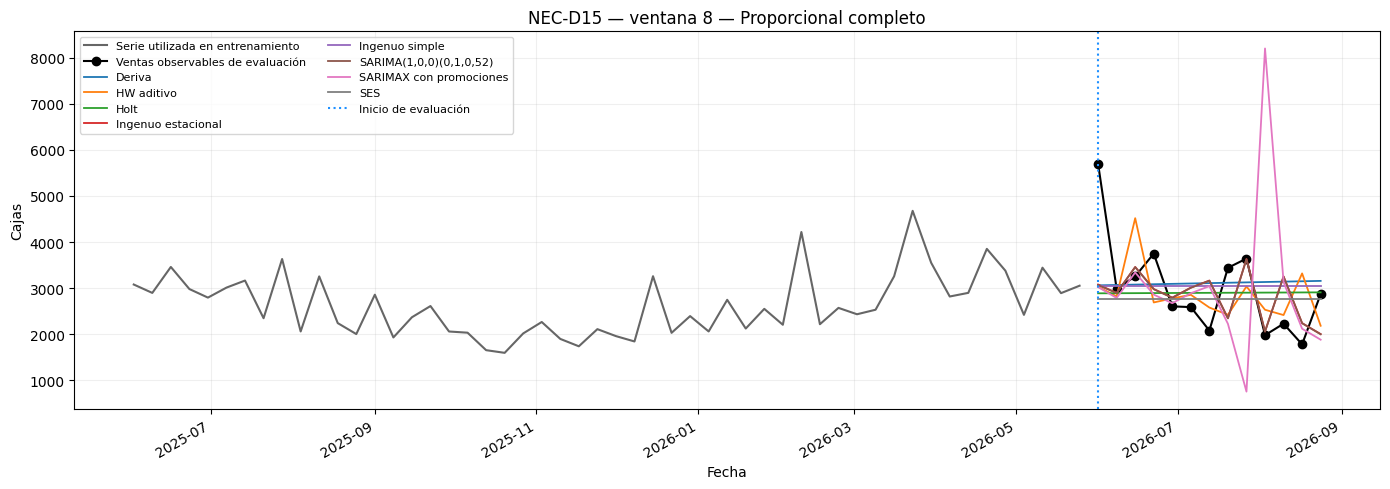

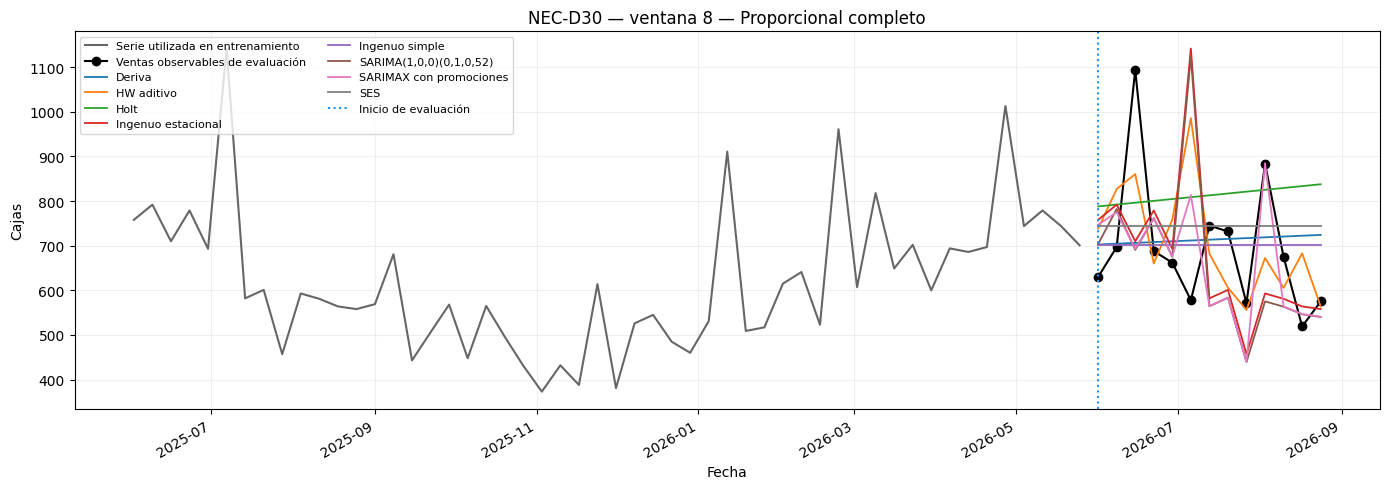

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [35]:

VENTANA_ELEGIDA = 8

# Escenario mostrado; todavía no es una selección definitiva.
ESCENARIO_GRAFICO = "Proporcional completo"

for sku in sorted(resultados_rolling["SKU"].unique()):
    pred = resultados_rolling.loc[
        (resultados_rolling["SKU"] == sku)
        & (resultados_rolling["Ventana"] == VENTANA_ELEGIDA)
        & (
            resultados_rolling["Escenario_censura"]
            == ESCENARIO_GRAFICO
        )
    ].copy()

    if pred.empty:
        continue

    pred["Fecha"] = pd.to_datetime(pred["Fecha"])
    fecha_corte = pred["Fecha"].min()

    train_raw = (
        demanda.loc[
            (demanda["sku"] == sku)
            & (demanda["fecha_lunes"] < fecha_corte)
        ]
        .sort_values("fecha_lunes")
        .copy()
    )

    # Historia preparada con el mismo escenario de los pronósticos.
    y_hist = preparar_objetivo_censura(
        train_raw, ESCENARIO_GRAFICO
    )

    historia = pd.DataFrame({
        "Fecha": train_raw["fecha_lunes"].to_numpy(),
        "Objetivo": y_hist
    }).tail(52)

    reales = (
        pred[["Fecha", "Real", "Observable"]]
        .drop_duplicates("Fecha")
        .sort_values("Fecha")
    )

    # NaN interrumpe la línea donde no hay demanda observable.
    reales["Real_visible"] = reales["Real"].where(
        reales["Observable"]
    )

    fig, ax = plt.subplots(figsize=(14, 5))

    ax.plot(
        historia["Fecha"], historia["Objetivo"],
        color="0.4",
        label="Serie utilizada en entrenamiento"
    )

    ax.plot(
        reales["Fecha"], reales["Real_visible"],
        color="black", marker="o",
        label="Ventas observables de evaluación"
    )

    for modelo, grupo in pred.groupby("Modelo"):
        grupo = grupo.sort_values("Fecha")

        ax.plot(
            grupo["Fecha"], grupo["Pronostico"],
            linewidth=1.3,
            label=modelo
        )

    ax.axvline(
        fecha_corte, color="dodgerblue",
        linestyle=":", label="Inicio de evaluación"
    )

    ax.set_title(
        f"{sku} — ventana {VENTANA_ELEGIDA}"
        f" — {ESCENARIO_GRAFICO}"
    )
    ax.set_xlabel("Fecha")
    ax.set_ylabel("Cajas")
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8, ncol=2)

    fig.autofmt_xdate()
    plt.tight_layout()
    plt.show()

In [36]:
import numpy as np
import pandas as pd

r = resultados_rolling.loc[
    resultados_rolling["Observable"]
].copy()

r["Error"] = r["Pronostico"] - r["Real"]
r["Error_abs"] = r["Error"].abs()

r["Error_MASE"] = (
    r["Error_abs"] / r["Escala_MASE"]
)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [37]:
# Las métricas ya se calcularon separando los escenarios.
# Aquí únicamente mostramos el detalle por horizonte.
display(
    metricas_horizonte.loc[
        (metricas_horizonte["SKU"] == "FUN-B30")
        & (metricas_horizonte["Modelo"] == "Ingenuo estacional")
    ].sort_values(
        ["Escenario_censura", "Horizonte"]
    ).round(3)
)

,SKU,Escenario_censura,Modelo,Horizonte,WAPE_pct,MASE,Sesgo_cajas,N_observaciones,N_ventanas_con_datos
1599,FUN-B30,Factor limitado a 2,Ingenuo estacional,1,271.420,1.314,145.633,5.0,5.0
1600,FUN-B30,Factor limitado a 2,Ingenuo estacional,2,279.310,0.940,32.200,5.0,5.0
1601,FUN-B30,Factor limitado a 2,Ingenuo estacional,3,NaN,0.468,53.433,6.0,6.0
1602,FUN-B30,Factor limitado a 2,Ingenuo estacional,4,217.196,1.763,81.508,6.0,6.0
1603,FUN-B30,Factor limitado a 2,Ingenuo estacional,5,104.832,1.045,56.560,5.0,5.0
1604,FUN-B30,Factor limitado a 2,Ingenuo estacional,6,194.297,1.708,98.033,5.0,5.0
1605,FUN-B30,Factor limitado a 2,Ingenuo estacional,7,279.310,1.186,40.250,4.0,4.0
1606,FUN-B30,Factor limitado a 2,Ingenuo estacional,8,NaN,0.471,53.433,6.0,6.0
1607,FUN-B30,Factor limitado a 2,Ingenuo estacional,9,248.793,1.736,95.864,7.0,7.0
1608,FUN-B30,Factor limitado a 2,Ingenuo estacional,10,103.243,1.523,-1.840,5.0,5.0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Además de evaluar la magnitud de los errores mediante WAPE y MASE, se analiza el sesgo de los modelos para identificar posibles tendencias de sobreestimación o subestimación de la demanda. Para ello, se calcula el error promedio con signo para cada horizonte de pronóstico, desde la semana 1 hasta la semana 13, considerando las ocho ventanas de validación temporal.
El siguiente gráfico presenta la evolución del sesgo para los nueve SKU y permite comparar el comportamiento de los distintos modelos a medida que aumenta el horizonte de pronóstico. Los valores positivos indican sobreestimación, mientras que los negativos reflejan subestimación. Una mayor cercanía a cero representa un menor sesgo promedio, aunque no implica necesariamente una mayor precisión del modelo.

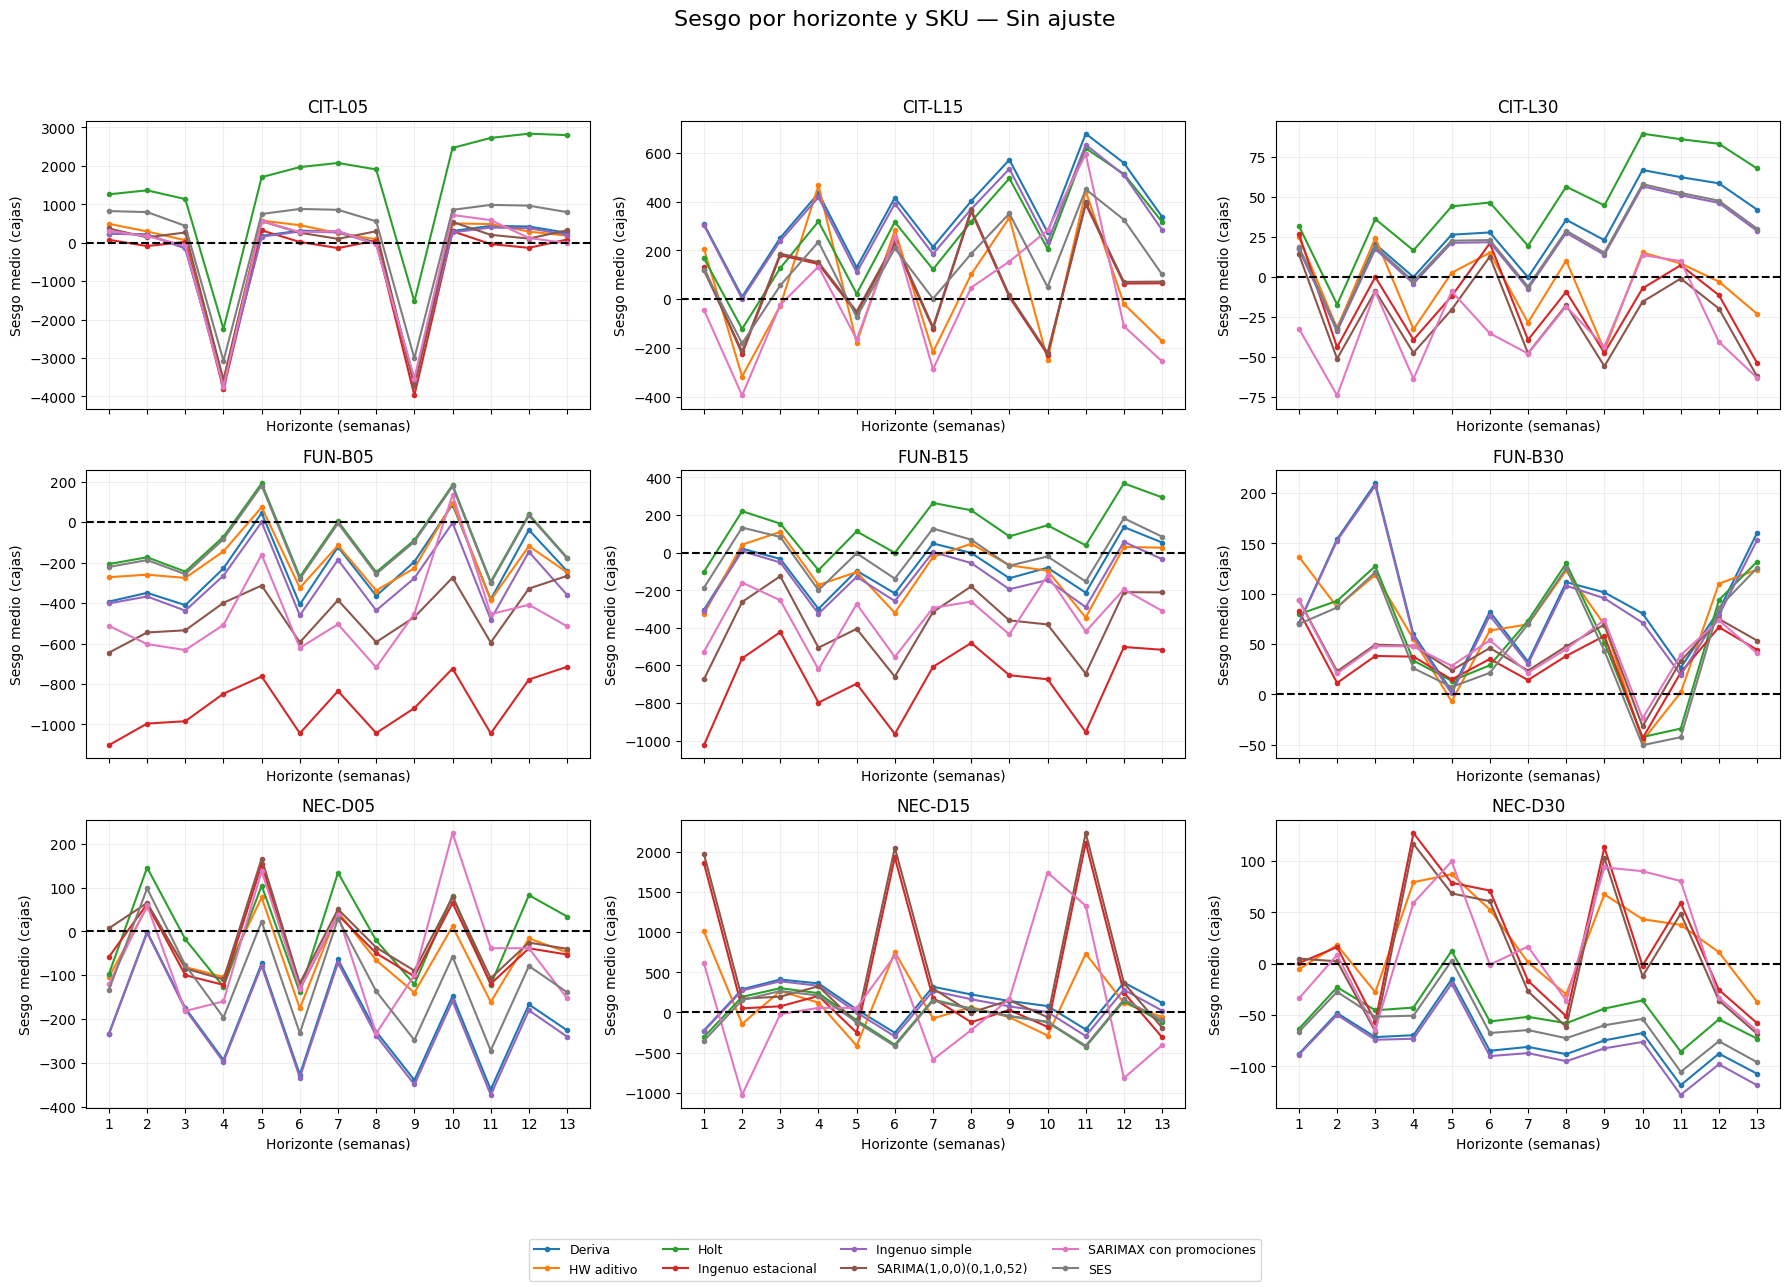

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


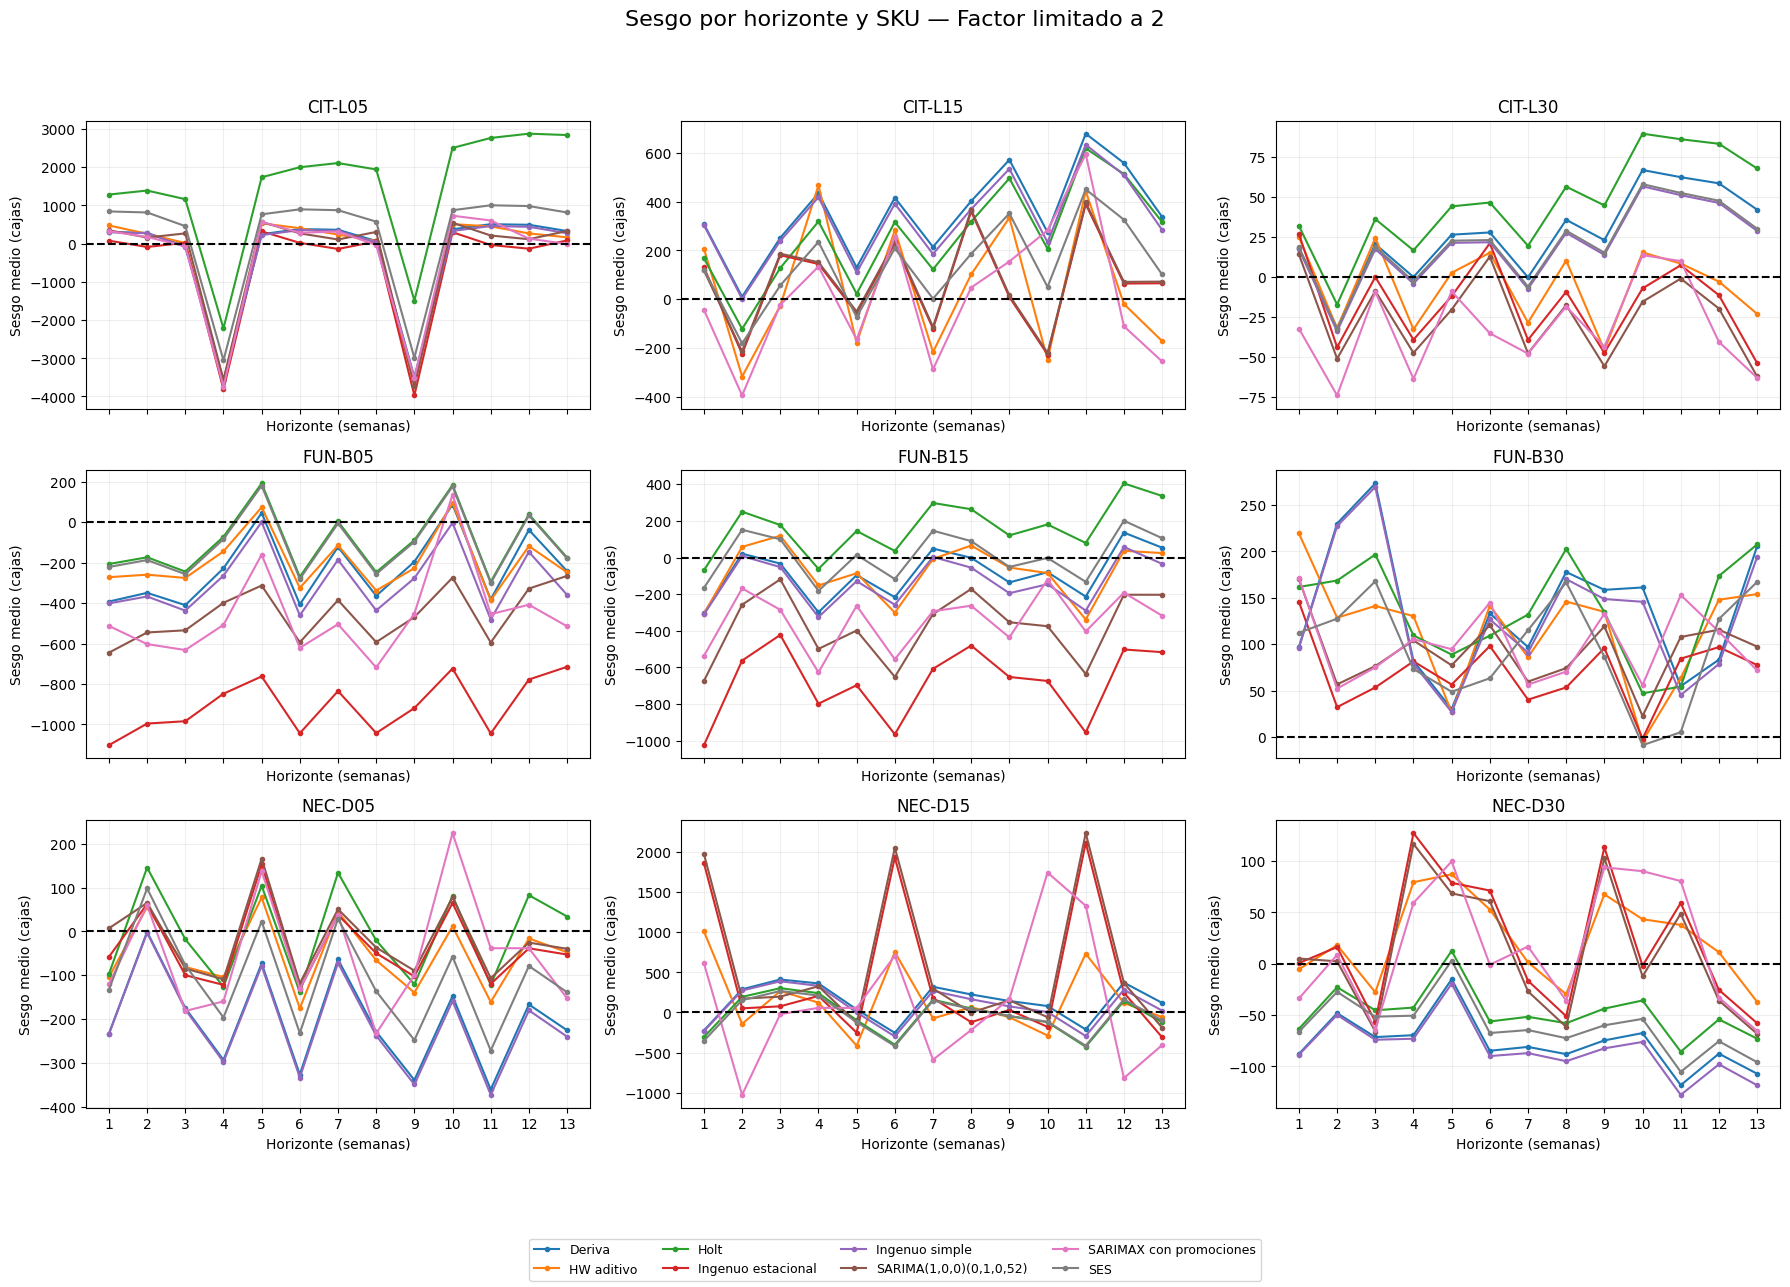

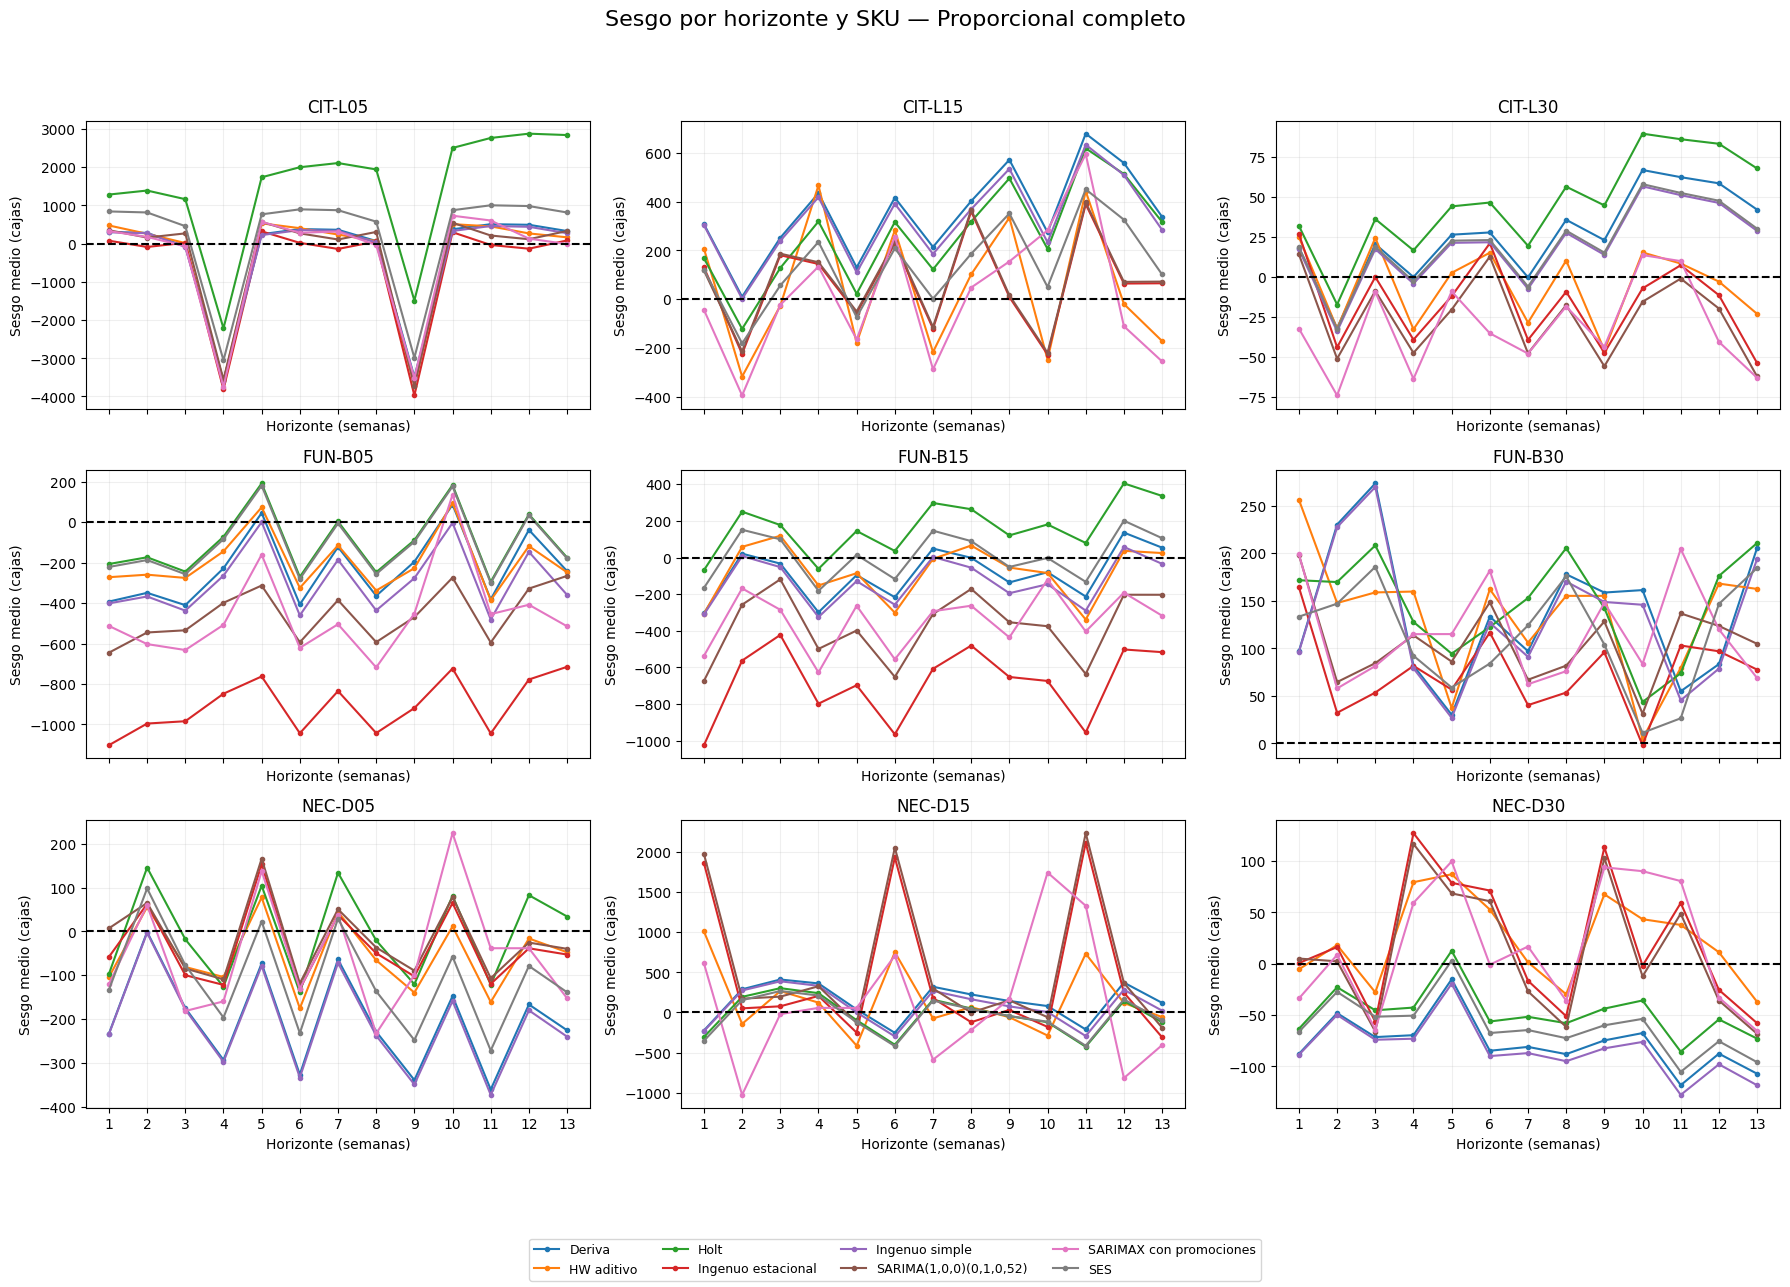

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [38]:


# Mostramos cada escenario por separado.
for escenario in ESCENARIOS_CENSURA:
    fig, axes = plt.subplots(
        3, 3, figsize=(18, 13), sharex=True
    )

    skus = sorted(metricas_horizonte["SKU"].unique())

    for ax, sku in zip(axes.flat, skus):
        datos = metricas_horizonte.loc[
            (metricas_horizonte["SKU"] == sku)
            & (
                metricas_horizonte["Escenario_censura"]
                == escenario
            )
        ]

        for modelo, grupo in datos.groupby("Modelo"):
            grupo = grupo.sort_values("Horizonte")

            ax.plot(
                grupo["Horizonte"],
                grupo["Sesgo_cajas"],
                marker="o",
                markersize=3,
                label=modelo
            )

        ax.axhline(0, color="black", linestyle="--")
        ax.set_title(sku)
        ax.set_xlabel("Horizonte (semanas)")
        ax.set_ylabel("Sesgo medio (cajas)")
        ax.set_xticks(range(1, H + 1))
        ax.grid(alpha=0.2)

    handles, labels = axes.flat[0].get_legend_handles_labels()

    fig.legend(
        handles, labels,
        loc="lower center", ncol=4, fontsize=9
    )

    fig.suptitle(
        f"Sesgo por horizonte y SKU — {escenario}",
        fontsize=16
    )

    fig.tight_layout(rect=[0, 0.09, 1, 0.95])
    plt.show()

In [39]:
def revisar_picos_entrenamiento(train_raw):
    resultado = (
        train_raw.sort_values("semana")
        .reset_index(drop=True)
        .copy()
    )

    cambios = []

    for i in range(len(resultado)):
        fila = resultado.iloc[i]
        venta = fila["ventas_cajas"]

        if pd.isna(venta) or fila["dias_sin_stock"] != 0:
            continue

        anteriores = resultado.iloc[max(0, i - 26):i]

        # Preferimos antecedentes con la misma condición promocional.
        comparables = anteriores.loc[
            anteriores["ventas_cajas"].notna()
            & anteriores["dias_sin_stock"].eq(0)
            & anteriores["promocion"].eq(fila["promocion"])
        ]

        if len(comparables) < 5:
            comparables = anteriores.loc[
                anteriores["ventas_cajas"].notna()
                & anteriores["dias_sin_stock"].eq(0)
            ]

        if len(comparables) < 8:
            continue

        valores = comparables["ventas_cajas"].to_numpy()
        mediana = np.median(valores)
        mad = np.median(np.abs(valores - mediana))
        escala = 1.4826 * mad

        if mediana <= 0 or escala <= 0:
            continue

        puntaje = (venta - mediana) / escala
        razon = venta / mediana

        # Regla exploratoria para picos positivos muy extremos.
        if puntaje > 8 and razon > 5:
            cambios.append({
                "sku": fila["sku"],
                "semana": fila["semana"],
                "venta_original": venta,
                "referencia_previa": mediana,
                "puntaje_robusto": puntaje,
                "razon": razon
            })

            resultado.loc[i, "ventas_cajas"] = mediana

    return resultado, pd.DataFrame(cambios)


revisiones = []

for sku, grupo in demanda.groupby("sku"):
    _, cambios = revisar_picos_entrenamiento(grupo)

    if not cambios.empty:
        revisiones.append(cambios)

revision_picos_sensibilidad = (
    pd.concat(revisiones, ignore_index=True)
    if revisiones else pd.DataFrame()
)

display(revision_picos_sensibilidad.round(2))

,sku,semana,venta_original,referencia_previa,puntaje_robusto,razon
0,CIT-L05,118,32916.0,1736.0,46.84,18.96
1,NEC-D15,63,20052.0,2493.5,29.76,8.04


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [40]:
registros_picos = []

for sku in ["CIT-L05", "NEC-D15"]:
    datos_sku = (
        demanda.loc[demanda["sku"] == sku]
        .sort_values("fecha_lunes")
        .reset_index(drop=True)
    )

    cortes = list(range(
        MIN_ENTRENAMIENTO,
        len(datos_sku) - H + 1,
        PASO
    ))[-N_VENTANAS:]

    for ventana, corte in enumerate(cortes, start=1):
        train_raw = datos_sku.iloc[:corte].copy()
        test_raw = datos_sku.iloc[corte:corte + H].copy()

        train_sustituido, cambios = (
            revisar_picos_entrenamiento(train_raw)
        )

        real = test_raw["ventas_cajas"].to_numpy(dtype=float)
        observable = (
            test_raw["dias_sin_stock"].eq(0).to_numpy()
            & np.isfinite(real)
        )

        referencia = preparar_objetivo_censura(
            train_raw, "Sin ajuste"
        )
        escala = np.mean(np.abs(np.diff(referencia)))

        if not np.isfinite(escala) or escala <= 0:
            raise ValueError("Escala MASE inválida.")

        # Referencia y evaluación comunes a ambos tratamientos.
        for tratamiento, datos_train in [
            ("Conservar picos", train_raw),
            ("Sustituir picos", train_sustituido)
        ]:
            print(
                f"{sku} — ventana {ventana}/{N_VENTANAS}"
                f" — {tratamiento}",
                flush=True
            )

            y_train = preparar_objetivo_censura(
                datos_train, "Proporcional completo"
            )

            candidatos = pronosticar_candidatos(y_train, H, M)

            # SARIMAX queda fuera de esta sensibilidad:
            # aquí comparamos los modelos sin regresores externos.
            for modelo, pred in candidatos.items():
                pred = np.asarray(pred, dtype=float)

                assert len(pred) == H
                assert np.isfinite(pred).all()

                for i in range(H):
                    registros_picos.append({
                        "SKU": sku,
                        "Ventana": ventana,
                        "Horizonte": i + 1,
                        "Fecha": test_raw["fecha_lunes"].iloc[i],
                        "Modelo": modelo,
                        "Tratamiento_picos": tratamiento,
                        "Real": real[i],
                        "Pronostico": pred[i],
                        "Observable": bool(observable[i]),
                        "Escala_MASE": escala,
                        "Picos_sustituidos_entrenamiento":
                            len(cambios)
                            if tratamiento == "Sustituir picos"
                            else 0
                    })

resultados_picos = pd.DataFrame(registros_picos)

assert resultados_picos.groupby(
    ["SKU", "Ventana", "Tratamiento_picos", "Modelo"]
).size().eq(H).all()

r_picos = resultados_picos.loc[
    resultados_picos["Observable"]
].copy()

r_picos["Error"] = r_picos["Pronostico"] - r_picos["Real"]
r_picos["Error_abs"] = r_picos["Error"].abs()
r_picos["Error_MASE"] = (
    r_picos["Error_abs"] / r_picos["Escala_MASE"]
)

resumen_picos_modelos = (
    r_picos.groupby(
        ["SKU", "Tratamiento_picos", "Modelo"]
    )
    .apply(resumir_metricas, include_groups=False)
    .reset_index()
)

comparacion_picos = resumen_picos_modelos.pivot(
    index=["SKU", "Modelo"],
    columns="Tratamiento_picos",
    values=["WAPE_pct", "MASE", "Sesgo_cajas"]
)

display(comparacion_picos.round(3))

print("Sensibilidad a picos completada.")

CIT-L05 — ventana 1/8 — Conservar picos


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


CIT-L05 — ventana 1/8 — Sustituir picos
CIT-L05 — ventana 2/8 — Conservar picos


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


CIT-L05 — ventana 2/8 — Sustituir picos


...

NEC-D15 — ventana 8/8 — Sustituir picos


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

WAPE_pct                  \
Tratamiento_picos               Conservar picos Sustituir picos   
SKU     Modelo                                                    
CIT-L05 Deriva                           44.718          44.718   
        HW aditivo                       40.590          35.359   
        Holt                             99.649          45.144   
        Ingenuo estacional               34.428          34.428   
        Ingenuo simple                   43.991          43.991   
        SARIMA(1,0,0)(0,1,0,52)          36.998          34.880   
        SES                              65.014          43.901   
NEC-D15 Deriva                           27.446          27.446   
        HW aditivo                       30.727          20.695   
        Holt                             25.367          29.650   
        Ingenuo estacional               41.976          23.904   
        Ingenuo simple                   26.255          26.255   
        SARIMA(1,0,0)(0,1,0,52)          43.194          23.881   
        SES                              23.760          21.806   

                                           MASE                  \
Tratamiento_picos               Conservar picos Sustituir picos   
SKU     Modelo                                                    
CIT-L05 Deriva                            1.932           1.932   
        HW aditivo                        1.685           1.547   
        Holt                              3.326           1.902   
        Ingenuo estacional                1.523           1.523   
        Ingenuo simple                    1.901           1.901   
        SARIMA(1,0,0)(0,1,0,52)           1.600           1.542   
        SES                               2.367           1.817   
NEC-D15 Deriva                            0.844           0.844   
        HW aditivo                        0.936           0.639   
        Holt                              0.771           0.910   
        Ingenuo estacional                1.269           0.735   
        Ingenuo simple                    0.807           0.807   
        SARIMA(1,0,0)(0,1,0,52)           1.305           0.734   
        SES                               0.726           0.670   

                                    Sesgo_cajas                  
Tratamiento_picos               Conservar picos Sustituir picos  
SKU     Modelo                                                   
CIT-L05 Deriva                         -292.170        -292.170  
        HW aditivo                     -303.301        -564.641  
        Holt                           1453.344        -218.625  
        Ingenuo estacional             -562.337        -562.337  
        Ingenuo simple                 -322.808        -322.808  
        SARIMA(1,0,0)(0,1,0,52)        -312.634        -571.751  
        SES                             219.676        -429.194  
NEC-D15 Deriva                          128.234         128.234  
        HW aditivo                      156.098         -82.034  
        Holt                            -32.970        -164.030  
        Ingenuo estacional              448.096         -58.399  
        Ingenuo simple                   76.173          76.173  
        SARIMA(1,0,0)(0,1,0,52)         567.782         -62.395  
        SES                             -44.377        -233.187

Sensibilidad a picos completada.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


### Sensibilidad al tratamiento de picos extremos

Se compararon dos tratamientos: conservar las ventas originales y sustituir, únicamente dentro del entrenamiento, los picos detectados mediante una regla basada en observaciones anteriores.

La regla identificó CIT-L05 en la semana 118 y NEC-D15 en la semana 63. La sustitución utiliza una mediana histórica calculada sin observaciones posteriores al registro. Los umbrales son exploratorios y no demuestran que los registros sean errores.

La comparación mantuvo el ajuste proporcional completo de censura, las mismas ventanas y una referencia MASE común. Las ventas de evaluación permanecieron intactas. SARIMAX con promociones no se incluyó en esta sensibilidad.

En CIT-L05, la sustitución redujo el WAPE de Holt, SES, el modelo estacional aditivo y SARIMA. Sin embargo, el ingenuo estacional mantuvo un WAPE de 34,43 %, inferior al de los restantes candidatos de esta comparación.

En NEC-D15, el modelo estacional aditivo pasó de un WAPE de 30,73 % a 20,10 % al sustituir el pico. También mejoraron SES, SARIMA y el ingenuo estacional, mientras que Holt empeoró.

Los resultados muestran sensibilidad al tratamiento de observaciones extremas. Una mejora predictiva no confirma un error de registro. Las sustituciones se conservan como una alternativa de preparación del entrenamiento y los datos originales permanecen intactos.

Estas métricas se utilizaron para comparar alternativas; no constituyen una evaluación independiente posterior a la selección.

In [41]:
# SARIMAX con calendario hipotético se mantiene como análisis separado.
candidatos_principales = resumen_modelos.loc[
    resumen_modelos["Modelo"] != "SARIMAX con promociones"
].copy()

mejores_por_escenario = (
    candidatos_principales
    .sort_values(
        ["SKU", "Escenario_censura", "WAPE_pct", "MASE", "Modelo"]
    )
    .drop_duplicates(["SKU", "Escenario_censura"])
)

display(
    mejores_por_escenario[
        [
            "SKU",
            "Escenario_censura",
            "Modelo",
            "WAPE_pct",
            "MASE",
            "Sesgo_cajas",
            "N_observaciones"
        ]
    ].round(3)
)

,SKU,Escenario_censura,Modelo,WAPE_pct,MASE,Sesgo_cajas,N_observaciones
3,CIT-L05,Factor limitado a 2,Ingenuo estacional,34.428,1.523,-562.337,104.0
11,CIT-L05,Proporcional completo,Ingenuo estacional,34.428,1.523,-562.337,104.0
19,CIT-L05,Sin ajuste,Ingenuo estacional,34.428,1.523,-562.337,104.0
25,CIT-L15,Factor limitado a 2,HW aditivo,20.924,0.850,49.957,104.0
33,CIT-L15,Proporcional completo,HW aditivo,20.924,0.850,49.957,104.0
41,CIT-L15,Sin ajuste,HW aditivo,20.924,0.850,49.957,104.0
49,CIT-L30,Factor limitado a 2,HW aditivo,14.681,0.773,-4.914,104.0
57,CIT-L30,Proporcional completo,HW aditivo,14.681,0.773,-4.914,104.0
65,CIT-L30,Sin ajuste,HW aditivo,14.681,0.773,-4.914,104.0
73,FUN-B05,Factor limitado a 2,HW aditivo,18.356,1.053,-195.203,104.0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [42]:
# Candidatos de la comparación principal.
base_seleccion = candidatos_principales.copy()
base_seleccion["Tratamiento_picos"] = "Conservar picos"

# Incorporamos la alternativa con picos sustituidos.
# Esa sensibilidad se evaluó con censura proporcional completa.
alternativa_picos = resumen_picos_modelos.loc[
    resumen_picos_modelos["Tratamiento_picos"]
    == "Sustituir picos"
].copy()

alternativa_picos["Escenario_censura"] = (
    "Proporcional completo"
)

columnas_seleccion = [
    "SKU",
    "Modelo",
    "Escenario_censura",
    "Tratamiento_picos",
    "WAPE_pct",
    "MASE",
    "Sesgo_cajas",
    "N_observaciones"
]

candidatos_seleccion = pd.concat(
    [
        base_seleccion[columnas_seleccion],
        alternativa_picos[columnas_seleccion]
    ],
    ignore_index=True
)

# Desempate cuando las métricas coinciden:
# preferimos la reconstrucción proporcional completa
# y conservar los registros originales.
candidatos_seleccion["prioridad_censura"] = (
    candidatos_seleccion["Escenario_censura"].map({
        "Proporcional completo": 0,
        "Factor limitado a 2": 1,
        "Sin ajuste": 2
    })
)

candidatos_seleccion["prioridad_picos"] = (
    candidatos_seleccion["Tratamiento_picos"].map({
        "Conservar picos": 0,
        "Sustituir picos": 1
    })
)

seleccion_provisional = (
    candidatos_seleccion
    .sort_values([
        "SKU",
        "WAPE_pct",
        "MASE",
        "prioridad_censura",
        "prioridad_picos",
        "Modelo"
    ])
    .drop_duplicates("SKU")
    .reset_index(drop=True)
)

display(
    seleccion_provisional[columnas_seleccion].round(3)
)

,SKU,Modelo,Escenario_censura,Tratamiento_picos,WAPE_pct,MASE,Sesgo_cajas,N_observaciones
0,CIT-L05,Ingenuo estacional,Proporcional completo,Conservar picos,34.428,1.523,-562.337,104.0
1,CIT-L15,HW aditivo,Proporcional completo,Conservar picos,20.924,0.850,49.957,104.0
2,CIT-L30,HW aditivo,Proporcional completo,Conservar picos,14.681,0.773,-4.914,104.0
3,FUN-B05,HW aditivo,Proporcional completo,Conservar picos,18.356,1.053,-195.203,104.0
4,FUN-B15,HW aditivo,Proporcional completo,Conservar picos,20.263,1.383,-76.421,98.0
5,FUN-B30,Ingenuo estacional,Sin ajuste,Conservar picos,162.357,0.949,33.686,70.0
6,NEC-D05,HW aditivo,Proporcional completo,Conservar picos,17.367,0.826,-54.386,104.0
7,NEC-D15,HW aditivo,Proporcional completo,Sustituir picos,20.695,0.639,-82.034,104.0
8,NEC-D30,HW aditivo,Proporcional completo,Conservar picos,15.442,0.717,22.880,104.0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [44]:
partes_seleccionadas = []

for _, fila in seleccion_provisional.iterrows():
    if fila["Tratamiento_picos"] == "Sustituir picos":
        seleccion = resultados_picos.loc[
            (resultados_picos["SKU"] == fila["SKU"])
            & (resultados_picos["Modelo"] == fila["Modelo"])
            & (
                resultados_picos["Tratamiento_picos"]
                == "Sustituir picos"
            )
        ].copy()

    else:
        seleccion = resultados_rolling.loc[
            (resultados_rolling["SKU"] == fila["SKU"])
            & (resultados_rolling["Modelo"] == fila["Modelo"])
            & (
                resultados_rolling["Escenario_censura"]
                == fila["Escenario_censura"]
            )
        ].copy()

    seleccion["Escenario_censura"] = fila["Escenario_censura"]
    seleccion["Tratamiento_picos"] = fila["Tratamiento_picos"]

    partes_seleccionadas.append(seleccion)

resultados_seleccionados = pd.concat(
    partes_seleccionadas,
    ignore_index=True
)

assert resultados_seleccionados.groupby(
    ["SKU", "Ventana"]
).size().eq(H).all(), (
    "Alguna combinación de SKU y ventana no tiene "
    "la cantidad esperada de pronósticos."
)

r_seleccion = resultados_seleccionados.loc[
    resultados_seleccionados["Observable"]
].copy()

r_seleccion["Error"] = (
    r_seleccion["Pronostico"] - r_seleccion["Real"]
)

r_seleccion["Error_abs"] = r_seleccion["Error"].abs()

r_seleccion["Error_MASE"] = (
    r_seleccion["Error_abs"] / r_seleccion["Escala_MASE"]
)

# Calculamos las métricas por grupo sin quitar
# la columna Ventana ni depender de groupby.apply.
filas_metricas = []

for (sku, ventana), grupo in r_seleccion.groupby(
    ["SKU", "Ventana"]
):
    denominador = grupo["Real"].abs().sum()

    filas_metricas.append({
        "SKU": sku,
        "Ventana": ventana,
        "WAPE_pct": (
            100 * grupo["Error_abs"].sum() / denominador
            if denominador > 0 else np.nan
        ),
        "MASE": grupo["Error_MASE"].mean(),
        "Sesgo_cajas": grupo["Error"].mean(),
        "N_observaciones": len(grupo),
        "N_ventanas_con_datos": grupo["Ventana"].nunique()
    })

metricas_seleccion_ventana = (
    pd.DataFrame(filas_metricas)
    .sort_values(["SKU", "Ventana"])
    .reset_index(drop=True)
)

print("WAPE por ventana de los candidatos seleccionados:")

display(
    metricas_seleccion_ventana.pivot(
        index="SKU",
        columns="Ventana",
        values="WAPE_pct"
    ).round(2)
)

print("\nResumen de variación entre ventanas:")

estabilidad_seleccion = (
    metricas_seleccion_ventana.groupby("SKU")
    .agg(
        Ventanas_evaluadas=("Ventana", "nunique"),
        WAPE_minimo=("WAPE_pct", "min"),
        WAPE_mediano=("WAPE_pct", "median"),
        WAPE_maximo=("WAPE_pct", "max"),
        Sesgo_minimo=("Sesgo_cajas", "min"),
        Sesgo_maximo=("Sesgo_cajas", "max"),
        Min_observaciones_por_ventana=(
            "N_observaciones", "min"
        )
    )
)

display(estabilidad_seleccion.round(2))

print("\nEvaluación de estabilidad completada.")

WAPE por ventana de los candidatos seleccionados:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Ventana,1,2,3,4,5,6,7,8
SKU,,,,,,,,
CIT-L05,23.14,54.26,50.37,15.09,21.63,25.56,11.54,10.25
CIT-L15,24.17,25.64,15.70,18.84,19.25,16.07,20.42,28.31
CIT-L30,17.23,15.30,14.95,14.09,12.00,13.53,14.44,15.97
FUN-B05,23.91,18.84,17.77,17.71,15.86,18.06,17.01,17.93
FUN-B15,21.59,16.24,19.52,18.81,20.36,24.10,20.33,20.72
FUN-B30,NaN,NaN,NaN,253.79,152.71,128.70,89.78,139.55
NEC-D05,14.79,14.71,20.58,17.59,21.05,19.63,13.22,16.02
NEC-D15,18.47,13.86,19.42,16.78,19.22,22.81,24.72,26.96
NEC-D30,13.44,12.21,14.30,17.35,14.34,14.95,16.96,18.39



Resumen de variación entre ventanas:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Ventanas_evaluadas,WAPE_minimo,WAPE_mediano,WAPE_maximo,Sesgo_minimo,Sesgo_maximo,Min_observaciones_por_ventana
SKU,,,,,,,
CIT-L05,8,10.25,22.38,54.26,-2468.38,320.15,13
CIT-L15,8,15.70,19.83,28.31,-188.30,213.77,13
CIT-L30,8,12.00,14.70,17.23,-31.46,17.19,13
FUN-B05,8,15.86,17.85,23.91,-503.16,40.22,13
FUN-B15,8,16.24,20.34,24.10,-306.64,176.53,11
FUN-B30,8,89.78,139.55,253.79,-39.12,83.38,8
NEC-D05,8,13.22,16.80,21.05,-115.47,41.81,13
NEC-D15,8,13.86,19.32,26.96,-204.46,15.29,13
NEC-D30,8,12.21,14.64,18.39,-7.46,47.04,13



Evaluación de estabilidad completada.


### Conclusiones de la validación temporal

Se compararon los modelos mediante ocho ventanas de origen móvil, con un horizonte de 13 semanas por ventana. Se calcularon WAPE, MASE y sesgo, tanto de forma global como por horizonte. La evaluación utilizó únicamente ventas observables, excluyendo los registros con falta de stock o información insuficiente.

La reconstrucción por censura, la imputación de valores faltantes y el tratamiento de picos se aplicaron dentro del entrenamiento de cada ventana. Las ventas utilizadas para evaluar los pronósticos conservaron sus valores originales.

### Selección provisional de modelos

La selección priorizó el menor WAPE global y utilizó MASE como segundo criterio. Los resultados fueron:

| SKU | Modelo | Tratamiento de censura | Tratamiento de picos | WAPE (%) | MASE |
|---|---|---|---|---:|---:|
| CIT-L05 | Ingenuo estacional | Proporcional completo | Conservar | 34,43 | 1,523 |
| CIT-L15 | HW aditivo | Proporcional completo | Conservar | 20,92 | 0,850 |
| CIT-L30 | HW aditivo | Proporcional completo | Conservar | 14,68 | 0,773 |
| FUN-B05 | HW aditivo | Proporcional completo | Conservar | 18,36 | 1,053 |
| FUN-B15 | HW aditivo | Proporcional completo | Conservar | 20,26 | 1,383 |
| FUN-B30 | Ingenuo estacional | Sin ajuste | Conservar | 162,36 | 0,949 |
| NEC-D05 | HW aditivo | Proporcional completo | Conservar | 17,37 | 0,826 |
| NEC-D15 | HW aditivo | Proporcional completo | Sustituir en entrenamiento | 20,70 | 0,639 |
| NEC-D30 | HW aditivo | Proporcional completo | Conservar | 15,44 | 0,717 |

El modelo denominado “HW aditivo” corresponde a suavizamiento exponencial con estacionalidad aditiva de 52 semanas y sin componente de tendencia.

### Sensibilidad al tratamiento de picos

Se comparó conservar los picos con sustituirlos por una referencia histórica calculada usando únicamente datos anteriores dentro del entrenamiento.

Para NEC-D15, la sustitución del pico redujo el WAPE del modelo HW aditivo de 30,73 % a 20,70 %. Por ello, esta combinación quedó seleccionada provisionalmente.

Para CIT-L05, la sustitución mejoró algunos modelos, pero el ingenuo estacional conservando los datos obtuvo un WAPE de 34,43 %, inferior al de las alternativas evaluadas con sustitución. Por lo tanto, se mantuvo el pico en la combinación seleccionada.

Estas sustituciones constituyen un análisis de sensibilidad: no demuestran que los picos sean errores de registro.

### Estabilidad entre ventanas

CIT-L30 y NEC-D30 mostraron menor variación del WAPE entre ventanas, con rangos de 12,00 % a 17,23 % y de 12,21 % a 18,39 %, respectivamente.

CIT-L05 presentó mayor variación: su WAPE osciló entre 10,25 % y 54,26 %. Esto indica que su desempeño depende más del período evaluado.

FUN-B30 fue el caso más difícil. En las ventanas con WAPE definido, los valores oscilaron entre 89,78 % y 253,79 %. En las primeras tres ventanas, el WAPE quedó indefinido porque la suma de ventas observables fue cero. Estos valores se conservaron como NaN y no se interpretaron como ausencia de error.

Los mínimos, medianas y máximos del resumen de estabilidad consideran únicamente los WAPE definidos.

### Alcance y limitaciones

La combinación seleccionada para FUN-B30 fue la de menor error sobre las ventas observables. Esto no demuestra que el escenario sin ajuste estime mejor la demanda durante los períodos con falta de stock, ya que esa demanda no se observa directamente. La reconstrucción proporcional se mantiene como un escenario alternativo basado en un supuesto explícito de disponibilidad.

SARIMAX con promociones se mantuvo como análisis exploratorio y se excluyó de la selección principal, porque sus promociones futuras fueron simuladas y no corresponden a un calendario confirmado.

La selección y las métricas reportadas proceden de las mismas ventanas de validación. Por ello, representan desempeño de validación y no una evaluación independiente posterior a la selección. Además, las ventanas se superponen, por lo que sus resultados no son independientes.

Los modelos seleccionados son candidatos provisionales para continuar con la comparación jerárquica del punto 5.

## Punto 5. Comparación de métodos de pronóstico jerárquico

Se compararán Bottom-Up, Top-Down y Middle-Out para la jerarquía Planta → Familia → SKU, mediante validación temporal y evaluación de errores en cada nivel.

### Paso 1. Identificación de la jerarquía

In [45]:
print("Columnas del maestro de productos:")
print(maestro_original.columns.tolist())

print("\nMaestro de productos:")
display(maestro_original)

print("\nSKU presentes en los resultados de validación:")
skus_validacion = sorted(resultados_rolling["SKU"].unique())
print(skus_validacion)

print(f"\nCantidad de SKU: {len(skus_validacion)}")

Columnas del maestro de productos:
['sku', 'familia', 'nombre_familia', 'sabor', 'formato_L', 'botellas_por_caja', 'litros_por_caja', 'linea_envasado', 'tasa_envasado_cajas_h', 'costo_variable_caja_clp', 'precio_lista_caja_clp', 'costo_inventario_caja_semana_clp', 'penalidad_atraso_caja_semana_clp']

Maestro de productos:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,sku,familia,nombre_familia,sabor,formato_L,botellas_por_caja,litros_por_caja,linea_envasado,tasa_envasado_cajas_h,costo_variable_caja_clp,precio_lista_caja_clp,costo_inventario_caja_semana_clp,penalidad_atraso_caja_semana_clp
0,NEC-D05,NEC,Nectares con pulpa,Durazno,0.5,12,6.0,L1,180,3840,6620,95,1400
1,NEC-D15,NEC,Nectares con pulpa,Durazno,1.5,6,9.0,L2,210,5760,9930,95,1400
2,NEC-D30,NEC,Nectares con pulpa,Durazno,3.0,4,12.0,L2,130,7680,13240,95,1400
3,CIT-L05,CIT,Citricos gasificados,Limon,0.5,12,6.0,L1,180,2820,5320,95,1400
4,CIT-L15,CIT,Citricos gasificados,Limon,1.5,6,9.0,L2,210,4230,7980,95,1400
5,CIT-L30,CIT,Citricos gasificados,Limon,3.0,4,12.0,L2,130,5640,10640,95,1400
6,FUN-B05,FUN,Funcionales,Berries,0.5,12,6.0,L1,180,4860,9920,95,1400
7,FUN-B15,FUN,Funcionales,Berries,1.5,6,9.0,L2,210,7290,14880,95,1400
8,FUN-B30,FUN,Funcionales,Berries,3.0,4,12.0,L2,130,9720,19840,95,1400



SKU presentes en los resultados de validación:
['CIT-L05', 'CIT-L15', 'CIT-L30', 'FUN-B05', 'FUN-B15', 'FUN-B30', 'NEC-D05', 'NEC-D15', 'NEC-D30']

Cantidad de SKU: 9


In [46]:
import numpy as np
import pandas as pd

# Identificar la familia de cada SKU.
jerarquia = (
    maestro_original[["sku", "familia", "nombre_familia"]]
    .copy()
    .sort_values(["familia", "sku"])
    .reset_index(drop=True)
)

assert jerarquia["sku"].is_unique, "Hay SKU duplicados en el maestro."
assert set(jerarquia["sku"]) == set(skus_validacion), (
    "Los SKU del maestro no coinciden con los de la validación."
)
assert jerarquia["familia"].notna().all(), "Hay SKU sin familia."

jerarquia.insert(0, "planta", "Planta")

print("Jerarquía del proyecto:")
display(jerarquia)

# Matriz de suma:
# cada columna representa un SKU;
# cada fila indica cuáles SKU integran ese nivel.
skus_jerarquia = sorted(jerarquia["sku"].tolist())
familias_jerarquia = sorted(jerarquia["familia"].unique().tolist())

familia_por_sku = jerarquia.set_index("sku")["familia"].to_dict()

nodos_jerarquia = (
    ["Planta"]
    + [f"Familia_{familia}" for familia in familias_jerarquia]
    + skus_jerarquia
)

S_jerarquia = pd.DataFrame(
    0,
    index=nodos_jerarquia,
    columns=skus_jerarquia,
    dtype=int
)

# La planta reúne los nueve SKU.
S_jerarquia.loc["Planta", :] = 1

# Cada familia reúne sus tres SKU.
for sku in skus_jerarquia:
    familia = familia_por_sku[sku]
    S_jerarquia.loc[f"Familia_{familia}", sku] = 1

# Cada SKU mantiene su propio valor.
for sku in skus_jerarquia:
    S_jerarquia.loc[sku, sku] = 1

assert S_jerarquia.shape == (13, 9)
assert (S_jerarquia.loc[
    [f"Familia_{f}" for f in familias_jerarquia]
].sum(axis=0) == 1).all()

print("\nMatriz de suma de la jerarquía:")
display(S_jerarquia)

print("\nValidación completada: 1 planta, 3 familias y 9 SKU.")

Jerarquía del proyecto:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,planta,sku,familia,nombre_familia
0,Planta,CIT-L05,CIT,Citricos gasificados
1,Planta,CIT-L15,CIT,Citricos gasificados
2,Planta,CIT-L30,CIT,Citricos gasificados
3,Planta,FUN-B05,FUN,Funcionales
4,Planta,FUN-B15,FUN,Funcionales
5,Planta,FUN-B30,FUN,Funcionales
6,Planta,NEC-D05,NEC,Nectares con pulpa
7,Planta,NEC-D15,NEC,Nectares con pulpa
8,Planta,NEC-D30,NEC,Nectares con pulpa



Matriz de suma de la jerarquía:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,CIT-L05,CIT-L15,CIT-L30,FUN-B05,FUN-B15,FUN-B30,NEC-D05,NEC-D15,NEC-D30
Planta,1,1,1,1,1,1,1,1,1
Familia_CIT,1,1,1,0,0,0,0,0,0
Familia_FUN,0,0,0,1,1,1,0,0,0
Familia_NEC,0,0,0,0,0,0,1,1,1
CIT-L05,1,0,0,0,0,0,0,0,0
CIT-L15,0,1,0,0,0,0,0,0,0
CIT-L30,0,0,1,0,0,0,0,0,0
FUN-B05,0,0,0,1,0,0,0,0,0
FUN-B15,0,0,0,0,1,0,0,0,0
FUN-B30,0,0,0,0,0,1,0,0,0



Validación completada: 1 planta, 3 familias y 9 SKU.


In [47]:
# Copia de los datos originales para el trabajo jerárquico.
datos_jerarquia = demanda_original.copy()
datos_jerarquia["fecha_lunes"] = pd.to_datetime(
    datos_jerarquia["fecha_lunes"]
)

datos_jerarquia = datos_jerarquia.sort_values(
    ["sku", "fecha_lunes"]
).reset_index(drop=True)

assert not datos_jerarquia.duplicated(
    ["sku", "fecha_lunes"]
).any(), "Hay registros duplicados por SKU y fecha."

assert set(datos_jerarquia["sku"]) == set(skus_jerarquia), (
    "Los SKU de los datos no coinciden con la jerarquía."
)

politicas_jerarquia = seleccion_provisional.set_index("SKU")

assert politicas_jerarquia.index.is_unique
assert set(politicas_jerarquia.index) == set(skus_jerarquia)

# Comprobar que todos los SKU tienen las mismas fechas.
fechas_por_sku = {
    sku: pd.DatetimeIndex(
        datos_jerarquia.loc[
            datos_jerarquia["sku"] == sku, "fecha_lunes"
        ].sort_values()
    )
    for sku in skus_jerarquia
}

fechas_jerarquia = fechas_por_sku[skus_jerarquia[0]]

for sku in skus_jerarquia:
    assert fechas_por_sku[sku].equals(fechas_jerarquia), (
        f"Las fechas de {sku} no coinciden con las demás series."
    )


def preparar_entrenamiento_jerarquico(n_semanas):
    """
    Prepara los SKU usando solamente las primeras n_semanas.
    Luego suma sus valores hacia familias y planta.
    """
    assert 0 < n_semanas <= len(fechas_jerarquia)

    entrenamiento_sku = pd.DataFrame(
        index=fechas_jerarquia[:n_semanas],
        columns=skus_jerarquia,
        dtype=float
    )

    for sku in skus_jerarquia:
        train_raw = (
            datos_jerarquia.loc[datos_jerarquia["sku"] == sku]
            .sort_values("fecha_lunes")
            .iloc[:n_semanas]
            .copy()
        )

        politica = politicas_jerarquia.loc[sku]

        # Revisar picos únicamente dentro de este entrenamiento.
        if "Sustituir" in str(politica["Tratamiento_picos"]):
            train_raw, _ = revisar_picos_entrenamiento(train_raw)

        # Reconstrucción e imputación dentro del entrenamiento.
        y_train = preparar_objetivo_censura(
            train_raw,
            politica["Escenario_censura"]
        )

        entrenamiento_sku[sku] = np.asarray(
            y_train, dtype=float
        )

    assert np.isfinite(entrenamiento_sku.to_numpy()).all()
    assert (entrenamiento_sku.to_numpy() >= 0).all()

    # Sumar los nueve SKU hacia los 13 nodos de la jerarquía.
    entrenamiento_nodos = entrenamiento_sku.dot(S_jerarquia.T)
    entrenamiento_nodos.index.name = "Fecha"

    columnas_familias = [
        f"Familia_{familia}" for familia in familias_jerarquia
    ]

    assert np.allclose(
        entrenamiento_nodos["Planta"],
        entrenamiento_nodos[columnas_familias].sum(axis=1)
    )

    assert np.allclose(
        entrenamiento_nodos["Planta"],
        entrenamiento_sku.sum(axis=1)
    )

    return entrenamiento_sku, entrenamiento_nodos


# Comprobación con las primeras 104 semanas.
train_sku_ejemplo, train_nodos_ejemplo = (
    preparar_entrenamiento_jerarquico(104)
)

print("Primeras cinco semanas de entrenamiento:")
display(train_nodos_ejemplo.head().round(2))

print("\nTamaño de la tabla:", train_nodos_ejemplo.shape)
print("Inicio:", train_nodos_ejemplo.index.min().date())
print("Fin:", train_nodos_ejemplo.index.max().date())

print(
    "\nPreparación completada: 104 semanas y 13 nodos, "
    "con sumas coherentes entre SKU, familias y planta."
)

Primeras cinco semanas de entrenamiento:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Planta,Familia_CIT,Familia_FUN,Familia_NEC,CIT-L05,CIT-L15,CIT-L30,FUN-B05,FUN-B15,FUN-B30,NEC-D05,NEC-D15,NEC-D30
Fecha,,,,,,,,,,,,,
2023-10-02,10158.0,4375.0,2176.0,3607.0,1878.0,2137.0,360.0,1192.0,818.0,166.0,1209.0,1943.0,455.0
2023-10-09,10273.0,4164.0,2293.0,3816.0,1933.0,1797.0,434.0,1349.0,786.0,158.0,1095.0,2230.0,491.0
2023-10-16,10336.0,4164.0,2072.0,4100.0,1731.0,1972.0,461.0,1165.0,743.0,164.0,1345.0,2237.0,518.0
2023-10-23,11167.0,4478.0,2163.0,4526.0,1761.0,2178.0,539.0,1211.0,775.0,177.0,1888.0,1980.0,658.0
2023-10-30,11029.0,6231.0,1786.0,3012.0,3572.0,2295.0,364.0,1091.0,695.0,0.0,991.0,1668.0,353.0



Tamaño de la tabla: (104, 13)
Inicio: 2023-10-02
Fin: 2025-09-22

Preparación completada: 104 semanas y 13 nodos, con sumas coherentes entre SKU, familias y planta.


### Paso 2. Método Bottom-Up

Se pronostica cada SKU con el modelo seleccionado en el punto 4. Los pronósticos se suman para obtener los resultados por familia y planta, garantizando coherencia entre los tres niveles.

In [48]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing


def pronosticar_modelo_jerarquia(y, modelo, h=13, periodo=52):
    y = np.asarray(y, dtype=float)

    assert np.isfinite(y).all(), (
        "El entrenamiento contiene valores no finitos."
    )
    assert len(y) >= periodo, (
        "No hay suficientes semanas para el período estacional."
    )

    if modelo == "Ingenuo estacional":
        pred = np.resize(y[-periodo:], h)

    elif modelo == "HW aditivo":
        ajuste = ExponentialSmoothing(
            y,
            trend=None,
            seasonal="add",
            seasonal_periods=periodo,
            initialization_method="estimated"
        ).fit(optimized=True)

        convergencia = getattr(ajuste, "mle_retvals", None)
        if (
            convergencia is not None
            and convergencia.get("success") is False
        ):
            raise RuntimeError(
                "El modelo HW aditivo no convergió."
            )

        pred = np.asarray(ajuste.forecast(h), dtype=float)

    else:
        raise ValueError(
            f"Modelo no implementado en esta función: {modelo}"
        )

    pred = np.maximum(np.asarray(pred, dtype=float), 0)

    assert len(pred) == h
    assert np.isfinite(pred).all()

    return pred


def pronosticar_bottom_up(train_sku, h=13):
    fechas_pronostico = pd.date_range(
        start=train_sku.index[-1] + pd.Timedelta(weeks=1),
        periods=h,
        freq="7D"
    )

    pred_sku = pd.DataFrame(
        index=fechas_pronostico,
        columns=skus_jerarquia,
        dtype=float
    )

    for sku in skus_jerarquia:
        modelo = politicas_jerarquia.loc[sku, "Modelo"]

        pred_sku[sku] = pronosticar_modelo_jerarquia(
            train_sku[sku].to_numpy(),
            modelo=modelo,
            h=h,
            periodo=52
        )

    # Agregar los pronósticos hacia familias y planta.
    pred_nodos = pred_sku.dot(S_jerarquia.T)
    pred_nodos.index.name = "Fecha"

    columnas_familias = [
        f"Familia_{familia}" for familia in familias_jerarquia
    ]

    assert np.isfinite(pred_nodos.to_numpy()).all()
    assert (pred_nodos.to_numpy() >= 0).all()

    assert np.allclose(
        pred_nodos["Planta"],
        pred_nodos[columnas_familias].sum(axis=1)
    )

    assert np.allclose(
        pred_nodos["Planta"],
        pred_nodos[skus_jerarquia].sum(axis=1)
    )

    return pred_nodos


# Comprobación sobre la primera ventana de entrenamiento.
pred_bottom_up_ejemplo = pronosticar_bottom_up(
    train_sku_ejemplo,
    h=13
)

print("Pronósticos Bottom-Up: primeras cinco semanas")
display(pred_bottom_up_ejemplo.head().round(2))

print("\nModelos utilizados por SKU:")
display(politicas_jerarquia[["Modelo"]])

print("\nTamaño de los pronósticos:", pred_bottom_up_ejemplo.shape)

print(
    "\nBottom-Up completado: 13 semanas y 13 nodos, "
    "con pronósticos coherentes."
)

Pronósticos Bottom-Up: primeras cinco semanas


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Planta,Familia_CIT,Familia_FUN,Familia_NEC,CIT-L05,CIT-L15,CIT-L30,FUN-B05,FUN-B15,FUN-B30,NEC-D05,NEC-D15,NEC-D30
Fecha,,,,,,,,,,,,,
2025-09-29,10339.83,3963.02,2701.32,3675.48,1758.0,1849.52,355.5,1627.27,1074.05,0.0,1233.50,1930.48,511.5
2025-10-06,11186.30,4317.05,3106.74,3762.51,1981.0,1910.55,425.5,1844.88,1261.86,0.0,1074.51,2169.00,519.0
2025-10-13,11429.09,4152.49,3372.13,3904.48,1756.0,1978.99,417.5,1963.80,1207.32,201.0,1259.49,2190.48,454.5
2025-10-20,13633.36,5954.56,3208.25,4470.55,2890.0,2575.06,489.5,1860.20,1153.05,195.0,1415.00,2480.05,575.5
2025-10-27,11677.95,5468.45,2899.96,3309.54,2063.0,2989.45,416.0,1733.82,1166.14,0.0,1144.00,1596.53,569.0



Modelos utilizados por SKU:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Modelo
SKU,
CIT-L05,Ingenuo estacional
CIT-L15,HW aditivo
CIT-L30,HW aditivo
FUN-B05,HW aditivo
FUN-B15,HW aditivo
FUN-B30,Ingenuo estacional
NEC-D05,HW aditivo
NEC-D15,HW aditivo
NEC-D30,HW aditivo



Tamaño de los pronósticos: (13, 13)

Bottom-Up completado: 13 semanas y 13 nodos, con pronósticos coherentes.


### Paso 3. Método Top-Down

Se pronostica el total de la planta mediante suavizamiento exponencial con estacionalidad aditiva de 52 semanas y sin tendencia.

El pronóstico se distribuye entre los SKU utilizando sus proporciones históricas: la suma de cajas de cada SKU dividida por la suma total de cajas en las últimas 52 semanas del entrenamiento. Las familias se obtienen sumando sus SKU.

Las proporciones permanecen constantes durante las 13 semanas pronosticadas y se recalculan en cada ventana usando únicamente el entrenamiento. Esta distribución puede limitar la representación de las distintas estacionalidades de las familias.

In [49]:
def pronosticar_top_down(train_sku, h=13):
    # Participaciones calculadas únicamente con el entrenamiento.
    historia_proporciones = train_sku.tail(52)
    totales_sku = historia_proporciones.sum(axis=0)
    total_planta = float(totales_sku.sum())

    if not np.isfinite(total_planta) or total_planta <= 0:
        raise ValueError(
            "No se pueden calcular proporciones: "
            "el total histórico de la planta no es positivo."
        )

    proporciones_sku = totales_sku / total_planta

    assert np.isfinite(proporciones_sku.to_numpy()).all()
    assert (proporciones_sku >= 0).all()
    assert np.isclose(proporciones_sku.sum(), 1)

    # Serie total de la planta.
    y_planta = train_sku.sum(axis=1).to_numpy()

    pred_planta = pronosticar_modelo_jerarquia(
        y_planta,
        modelo="HW aditivo",
        h=h,
        periodo=52
    )

    fechas_pronostico = pd.date_range(
        start=train_sku.index[-1] + pd.Timedelta(weeks=1),
        periods=h,
        freq="7D"
    )

    # Distribuir el pronóstico de planta entre los nueve SKU.
    pred_sku = pd.DataFrame(
        np.outer(
            pred_planta,
            proporciones_sku.reindex(skus_jerarquia).to_numpy()
        ),
        index=fechas_pronostico,
        columns=skus_jerarquia
    )

    # Obtener todos los niveles de la jerarquía.
    pred_nodos = pred_sku.dot(S_jerarquia.T)
    pred_nodos.index.name = "Fecha"

    columnas_familias = [
        f"Familia_{familia}" for familia in familias_jerarquia
    ]

    assert np.isfinite(pred_nodos.to_numpy()).all()
    assert (pred_nodos.to_numpy() >= 0).all()

    assert np.allclose(
        pred_nodos["Planta"].to_numpy(),
        pred_planta
    )

    assert np.allclose(
        pred_nodos["Planta"],
        pred_nodos[columnas_familias].sum(axis=1)
    )

    tabla_proporciones = pd.DataFrame({
        "SKU": skus_jerarquia,
        "Familia": [
            familia_por_sku[sku] for sku in skus_jerarquia
        ],
        "Participacion_pct": (
            proporciones_sku.reindex(skus_jerarquia).to_numpy()
            * 100
        )
    })

    return pred_nodos, tabla_proporciones


# Comprobación sobre la misma primera ventana que Bottom-Up.
pred_top_down_ejemplo, proporciones_top_down_ejemplo = (
    pronosticar_top_down(train_sku_ejemplo, h=13)
)

print("Participaciones históricas utilizadas:")
display(proporciones_top_down_ejemplo.round(2))

print(
    "\nSuma de participaciones (%):",
    round(
        proporciones_top_down_ejemplo["Participacion_pct"].sum(),
        2
    )
)

print("\nPronósticos Top-Down: primeras cinco semanas")
display(pred_top_down_ejemplo.head().round(2))

print("\nTamaño de los pronósticos:", pred_top_down_ejemplo.shape)

print(
    "\nTop-Down completado: 13 semanas y 13 nodos, "
    "con pronósticos coherentes."
)

Participaciones históricas utilizadas:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,SKU,Familia,Participacion_pct
0,CIT-L05,CIT,16.52
1,CIT-L15,CIT,17.88
2,CIT-L30,CIT,3.41
3,FUN-B05,FUN,13.47
4,FUN-B15,FUN,8.89
5,FUN-B30,FUN,0.98
6,NEC-D05,NEC,12.15
7,NEC-D15,NEC,21.48
8,NEC-D30,NEC,5.23



Suma de participaciones (%): 100.0

Pronósticos Top-Down: primeras cinco semanas


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Planta,Familia_CIT,Familia_FUN,Familia_NEC,CIT-L05,CIT-L15,CIT-L30,FUN-B05,FUN-B15,FUN-B30,NEC-D05,NEC-D15,NEC-D30
Fecha,,,,,,,,,,,,,
2025-09-29,10151.68,3837.99,2369.19,3944.50,1676.62,1814.87,346.51,1367.26,902.66,99.27,1233.45,2180.14,530.90
2025-10-06,10917.37,4127.47,2547.89,4242.01,1803.08,1951.75,372.64,1470.39,970.74,106.76,1326.49,2344.58,570.95
2025-10-13,11081.82,4189.65,2586.27,4305.91,1830.24,1981.15,378.25,1492.54,985.36,108.37,1346.47,2379.90,579.55
2025-10-20,12740.93,4816.89,2973.47,4950.57,2104.25,2277.76,434.88,1715.99,1132.88,124.59,1548.05,2736.20,666.31
2025-10-27,12120.68,4582.40,2828.71,4709.56,2001.81,2166.87,413.71,1632.45,1077.73,118.53,1472.69,2603.00,633.88



Tamaño de los pronósticos: (13, 13)

Top-Down completado: 13 semanas y 13 nodos, con pronósticos coherentes.


### Paso 4. Método Middle-Out

Se pronostica cada familia mediante suavizamiento exponencial con estacionalidad aditiva de 52 semanas y sin tendencia.

El pronóstico de cada familia se distribuye entre sus SKU según sus participaciones en las últimas 52 semanas del entrenamiento. Las participaciones permanecen constantes durante el horizonte y se recalculan en cada ventana.

El pronóstico de planta se obtiene sumando los pronósticos de las familias. Este método permite representar un patrón estacional diferente para cada familia, aunque mantiene proporciones fijas entre los SKU de una misma familia.

In [50]:
def pronosticar_middle_out(train_sku, h=13):
    fechas_pronostico = pd.date_range(
        start=train_sku.index[-1] + pd.Timedelta(weeks=1),
        periods=h,
        freq="7D"
    )

    pred_sku = pd.DataFrame(
        0.0,
        index=fechas_pronostico,
        columns=skus_jerarquia
    )

    registros_proporciones = []
    pronosticos_familias = {}

    for familia in familias_jerarquia:
        skus_familia = [
            sku for sku in skus_jerarquia
            if familia_por_sku[sku] == familia
        ]

        # Pronosticar la familia con todo su entrenamiento.
        y_familia = (
            train_sku[skus_familia].sum(axis=1).to_numpy()
        )

        pred_familia = pronosticar_modelo_jerarquia(
            y_familia,
            modelo="HW aditivo",
            h=h,
            periodo=52
        )

        pronosticos_familias[familia] = pred_familia

        # Calcular participaciones dentro de esta familia.
        totales_sku = (
            train_sku[skus_familia].tail(52).sum(axis=0)
        )
        total_familia = float(totales_sku.sum())

        if not np.isfinite(total_familia) or total_familia <= 0:
            raise ValueError(
                f"No se pueden calcular proporciones para {familia}: "
                "su total histórico no es positivo."
            )

        proporciones = totales_sku / total_familia

        assert np.isfinite(proporciones.to_numpy()).all()
        assert (proporciones >= 0).all()
        assert np.isclose(proporciones.sum(), 1)

        # Distribuir el pronóstico de familia entre sus SKU.
        for sku in skus_familia:
            pred_sku[sku] = pred_familia * proporciones[sku]

            registros_proporciones.append({
                "Familia": familia,
                "SKU": sku,
                "Participacion_en_familia_pct": (
                    proporciones[sku] * 100
                )
            })

    # Sumar los SKU hacia familias y planta.
    pred_nodos = pred_sku.dot(S_jerarquia.T)
    pred_nodos.index.name = "Fecha"

    columnas_familias = [
        f"Familia_{familia}" for familia in familias_jerarquia
    ]

    assert np.isfinite(pred_nodos.to_numpy()).all()
    assert (pred_nodos.to_numpy() >= 0).all()

    for familia in familias_jerarquia:
        assert np.allclose(
            pred_nodos[f"Familia_{familia}"].to_numpy(),
            pronosticos_familias[familia]
        )

    assert np.allclose(
        pred_nodos["Planta"],
        pred_nodos[columnas_familias].sum(axis=1)
    )

    assert np.allclose(
        pred_nodos["Planta"],
        pred_nodos[skus_jerarquia].sum(axis=1)
    )

    tabla_proporciones = pd.DataFrame(registros_proporciones)

    return pred_nodos, tabla_proporciones


# Comprobación sobre la misma primera ventana.
pred_middle_out_ejemplo, proporciones_middle_out_ejemplo = (
    pronosticar_middle_out(train_sku_ejemplo, h=13)
)

print("Participaciones dentro de cada familia:")
display(proporciones_middle_out_ejemplo.round(2))

print("\nSuma de participaciones por familia (%):")
display(
    proporciones_middle_out_ejemplo.groupby("Familia")[
        "Participacion_en_familia_pct"
    ].sum().round(2).to_frame()
)

print("\nPronósticos Middle-Out: primeras cinco semanas")
display(pred_middle_out_ejemplo.head().round(2))

print("\nTamaño de los pronósticos:", pred_middle_out_ejemplo.shape)

print(
    "\nMiddle-Out completado: 13 semanas y 13 nodos, "
    "con pronósticos coherentes."
)

Participaciones dentro de cada familia:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Familia,SKU,Participacion_en_familia_pct
0,CIT,CIT-L05,43.68
1,CIT,CIT-L15,47.29
2,CIT,CIT-L30,9.03
3,FUN,FUN-B05,57.71
4,FUN,FUN-B15,38.10
5,FUN,FUN-B30,4.19
6,NEC,NEC-D05,31.27
7,NEC,NEC-D15,55.27
8,NEC,NEC-D30,13.46



Suma de participaciones por familia (%):


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Participacion_en_familia_pct
Familia,
CIT,100.0
FUN,100.0
NEC,100.0



Pronósticos Middle-Out: primeras cinco semanas


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Planta,Familia_CIT,Familia_FUN,Familia_NEC,CIT-L05,CIT-L15,CIT-L30,FUN-B05,FUN-B15,FUN-B30,NEC-D05,NEC-D15,NEC-D30
Fecha,,,,,,,,,,,,,
2025-09-29,10650.28,4063.78,2943.25,3643.24,1775.26,1921.64,366.89,1698.55,1121.37,123.33,1139.25,2013.64,490.36
2025-10-06,11478.60,4402.32,3342.29,3733.99,1923.14,2081.72,397.45,1928.84,1273.40,140.05,1167.63,2063.79,502.57
2025-10-13,11609.01,4224.44,3505.43,3879.14,1845.44,1997.61,381.40,2022.99,1335.56,146.88,1213.01,2144.02,522.11
2025-10-20,13402.02,5613.26,3341.18,4447.58,2452.14,2654.34,506.78,1928.20,1272.98,140.00,1390.77,2458.20,598.61
2025-10-27,12643.23,6309.53,3045.62,3288.08,2756.31,2983.58,569.64,1757.63,1160.37,127.62,1028.19,1817.33,442.55



Tamaño de los pronósticos: (13, 13)

Middle-Out completado: 13 semanas y 13 nodos, con pronósticos coherentes.


### Paso 5. Comparación mediante validación temporal

Los tres métodos se evalúan en las mismas ocho ventanas del punto 4, con un horizonte de 13 semanas.

En cada ventana se preparan nuevamente los datos de entrenamiento. Top-Down y Middle-Out recalculan sus proporciones únicamente con ese entrenamiento.

Las ventas de evaluación conservan sus valores originales. Un SKU es observable cuando tiene ventas válidas y cero días sin stock. Una familia o la planta es observable únicamente cuando todos sus SKU integrantes son observables.

La escala de MASE se calcula con diferencias de una semana sobre una referencia de entrenamiento sin ajuste por censura, imputada únicamente dentro de la ventana y sin sustitución de picos. Esta escala es común a los tres métodos para cada nodo y ventana.

Los resultados corresponden a una comparación de validación condicionada a la selección provisional del punto 4; no constituyen una prueba independiente posterior a esa selección.

In [51]:
# Recuperar exactamente las ventanas utilizadas en el punto 4.
ventanas_jerarquia = (
    resultados_rolling[["Ventana", "Corte"]]
    .drop_duplicates()
    .sort_values("Ventana")
    .reset_index(drop=True)
)

ventanas_jerarquia["Corte"] = pd.to_datetime(
    ventanas_jerarquia["Corte"]
)

assert ventanas_jerarquia["Ventana"].is_unique
assert len(ventanas_jerarquia) == 8

H_JERARQUIA = 13
METODOS_JERARQUIA = ["Bottom-Up", "Top-Down", "Middle-Out"]

# Ventas originales para evaluar: no se reconstruyen ni se imputan.
ventas_sku_originales = (
    datos_jerarquia.pivot(
        index="fecha_lunes",
        columns="sku",
        values="ventas_cajas"
    )
    .reindex(index=fechas_jerarquia, columns=skus_jerarquia)
    .apply(pd.to_numeric, errors="coerce")
)

stock_sku_original = (
    datos_jerarquia.pivot(
        index="fecha_lunes",
        columns="sku",
        values="dias_sin_stock"
    )
    .reindex(index=fechas_jerarquia, columns=skus_jerarquia)
    .apply(pd.to_numeric, errors="coerce")
)

observable_sku = (
    stock_sku_original.eq(0)
    & ventas_sku_originales.notna()
    & np.isfinite(ventas_sku_originales)
    & ventas_sku_originales.ge(0)
)

registros_jerarquia = []

for _, ventana in ventanas_jerarquia.iterrows():
    numero_ventana = int(ventana["Ventana"])
    corte = ventana["Corte"]

    posicion_corte = fechas_jerarquia.get_indexer([corte])[0]
    assert posicion_corte >= 0, (
        f"No se encontró la fecha de corte {corte}."
    )

    fechas_test = fechas_jerarquia[
        posicion_corte:posicion_corte + H_JERARQUIA
    ]

    assert len(fechas_test) == H_JERARQUIA

    print(
        f"Ventana {numero_ventana}/8: "
        f"{posicion_corte} semanas de entrenamiento.",
        flush=True
    )

    # Mismos datos preparados para los tres métodos.
    train_sku, train_nodos = preparar_entrenamiento_jerarquico(
        posicion_corte
    )

    assert train_sku.index.max() < fechas_test.min()

    pred_bu = pronosticar_bottom_up(train_sku, h=H_JERARQUIA)
    pred_td, _ = pronosticar_top_down(train_sku, h=H_JERARQUIA)
    pred_mo, _ = pronosticar_middle_out(train_sku, h=H_JERARQUIA)

    predicciones = {
        "Bottom-Up": pred_bu,
        "Top-Down": pred_td,
        "Middle-Out": pred_mo
    }

    for pred in predicciones.values():
        assert pred.index.equals(fechas_test)

    # Referencia común para calcular la escala de MASE.
    referencia_sku = pd.DataFrame(
        index=train_sku.index,
        columns=skus_jerarquia,
        dtype=float
    )

    for sku in skus_jerarquia:
        train_raw = (
            datos_jerarquia.loc[datos_jerarquia["sku"] == sku]
            .sort_values("fecha_lunes")
            .iloc[:posicion_corte]
            .copy()
        )

        referencia_sku[sku] = preparar_objetivo_censura(
            train_raw,
            "Sin ajuste"
        )

    referencia_nodos = referencia_sku.dot(S_jerarquia.T)
    escalas_mase = referencia_nodos.diff().abs().mean()

    # Evaluar cada nodo con todos sus SKU integrantes.
    for nodo in nodos_jerarquia:
        integrantes = S_jerarquia.columns[
            S_jerarquia.loc[nodo].eq(1)
        ].tolist()

        reales = ventas_sku_originales.loc[
            fechas_test, integrantes
        ].sum(axis=1, min_count=len(integrantes))

        observables = observable_sku.loc[
            fechas_test, integrantes
        ].all(axis=1)

        if nodo == "Planta":
            nivel = "Planta"
        elif nodo.startswith("Familia_"):
            nivel = "Familia"
        else:
            nivel = "SKU"

        escala = float(escalas_mase[nodo])

        for metodo, pred in predicciones.items():
            for horizonte, fecha in enumerate(fechas_test, start=1):
                registros_jerarquia.append({
                    "Ventana": numero_ventana,
                    "Corte": corte,
                    "Fecha": fecha,
                    "Horizonte": horizonte,
                    "Metodo": metodo,
                    "Nivel": nivel,
                    "Nodo": nodo,
                    "Real": reales.loc[fecha],
                    "Pronostico": pred.loc[fecha, nodo],
                    "Observable": bool(observables.loc[fecha]),
                    "Escala_MASE": escala
                })

resultados_jerarquia = pd.DataFrame(registros_jerarquia)

# Comprobar que todos los pronósticos están completos.
cantidad_por_grupo = resultados_jerarquia.groupby(
    ["Metodo", "Nodo", "Ventana"]
).size()

assert (cantidad_por_grupo == H_JERARQUIA).all()
assert len(resultados_jerarquia) == 3 * 13 * 8 * 13
assert np.isfinite(resultados_jerarquia["Pronostico"]).all()

cobertura_jerarquia = (
    resultados_jerarquia.groupby(
        ["Nivel", "Nodo", "Metodo"]
    )
    .agg(
        Ventanas=("Ventana", "nunique"),
        Pronosticos=("Pronostico", "size"),
        Observaciones_evaluables=("Observable", "sum")
    )
    .reset_index()
)

# Cada método debe evaluarse sobre la misma cantidad de observaciones.
assert (
    cobertura_jerarquia.groupby("Nodo")[
        "Observaciones_evaluables"
    ].nunique() == 1
).all()

print("\nCobertura de evaluación:")
display(cobertura_jerarquia)

print(
    f"\nValidación jerárquica completada: "
    f"{len(resultados_jerarquia)} pronósticos."
)

Ventana 1/8: 104 semanas de entrenamiento.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Ventana 2/8: 109 semanas de entrenamiento.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Ventana 3/8: 114 semanas de entrenamiento.


...

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag


Cobertura de evaluación:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Nivel,Nodo,Metodo,Ventanas,Pronosticos,Observaciones_evaluables
0,Familia,Familia_CIT,Bottom-Up,8,104,104
1,Familia,Familia_CIT,Middle-Out,8,104,104
2,Familia,Familia_CIT,Top-Down,8,104,104
3,Familia,Familia_FUN,Bottom-Up,8,104,67
4,Familia,Familia_FUN,Middle-Out,8,104,67
5,Familia,Familia_FUN,Top-Down,8,104,67
6,Familia,Familia_NEC,Bottom-Up,8,104,104
7,Familia,Familia_NEC,Middle-Out,8,104,104
8,Familia,Familia_NEC,Top-Down,8,104,104
9,Planta,Planta,Bottom-Up,8,104,67



Validación jerárquica completada: 4056 pronósticos.


In [52]:
# Evaluar únicamente los registros observables.
evaluacion_jerarquia = resultados_jerarquia.loc[
    resultados_jerarquia["Observable"]
].copy()

assert np.isfinite(evaluacion_jerarquia["Real"]).all()

evaluacion_jerarquia["Error"] = (
    evaluacion_jerarquia["Pronostico"]
    - evaluacion_jerarquia["Real"]
)

evaluacion_jerarquia["Error_abs"] = (
    evaluacion_jerarquia["Error"].abs()
)

escala_valida = (
    np.isfinite(evaluacion_jerarquia["Escala_MASE"])
    & evaluacion_jerarquia["Escala_MASE"].gt(0)
)

evaluacion_jerarquia["Error_MASE"] = (
    evaluacion_jerarquia["Error_abs"]
    / evaluacion_jerarquia["Escala_MASE"].where(escala_valida)
)


def calcular_metricas_jerarquia(datos, columnas_grupo):
    registros = []

    for claves, grupo in datos.groupby(columnas_grupo):
        if not isinstance(claves, tuple):
            claves = (claves,)

        registro = dict(zip(columnas_grupo, claves))
        denominador = grupo["Real"].abs().sum()

        registro.update({
            "WAPE_pct": (
                100 * grupo["Error_abs"].sum() / denominador
                if denominador > 0 else np.nan
            ),
            "MASE": grupo["Error_MASE"].mean(),
            "Sesgo_cajas": grupo["Error"].mean(),
            "N_observaciones": len(grupo),
            "N_MASE_validos": grupo["Error_MASE"].notna().sum()
        })

        registros.append(registro)

    return pd.DataFrame(registros)


# Métricas por cada nodo: planta, familias y SKU.
metricas_jerarquia_nodo = calcular_metricas_jerarquia(
    evaluacion_jerarquia,
    ["Nivel", "Nodo", "Metodo"]
)

# Resumen por nivel:
# WAPE calculado sobre todos los errores de ese nivel,
# sin mezclar planta, familias y SKU entre sí.
metricas_jerarquia_nivel = calcular_metricas_jerarquia(
    evaluacion_jerarquia,
    ["Nivel", "Metodo"]
)

# Conservar también el detalle por horizonte.
metricas_jerarquia_horizonte = calcular_metricas_jerarquia(
    evaluacion_jerarquia,
    ["Nivel", "Nodo", "Metodo", "Horizonte"]
)

orden_metodos = ["Bottom-Up", "Top-Down", "Middle-Out"]

print("1. Comparación global por nivel:")
display(
    metricas_jerarquia_nivel.sort_values(
        ["Nivel", "WAPE_pct"]
    ).round(3)
)

print("\n2. WAPE (%) por nodo y método:")
tabla_wape_jerarquia = (
    metricas_jerarquia_nodo.pivot(
        index=["Nivel", "Nodo"],
        columns="Metodo",
        values="WAPE_pct"
    )
    .reindex(columns=orden_metodos)
)
display(tabla_wape_jerarquia.round(2))

print("\n3. MASE por nodo y método:")
tabla_mase_jerarquia = (
    metricas_jerarquia_nodo.pivot(
        index=["Nivel", "Nodo"],
        columns="Metodo",
        values="MASE"
    )
    .reindex(columns=orden_metodos)
)
display(tabla_mase_jerarquia.round(3))

print("\n4. Sesgo medio en cajas por nodo y método:")
tabla_sesgo_jerarquia = (
    metricas_jerarquia_nodo.pivot(
        index=["Nivel", "Nodo"],
        columns="Metodo",
        values="Sesgo_cajas"
    )
    .reindex(columns=orden_metodos)
)
display(tabla_sesgo_jerarquia.round(2))

print("\nCálculo de métricas jerárquicas completado.")

1. Comparación global por nivel:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Nivel,Metodo,WAPE_pct,MASE,Sesgo_cajas,N_observaciones,N_MASE_validos
0,Familia,Bottom-Up,17.434,1.023,-278.402,275,275
1,Familia,Middle-Out,19.178,1.088,-101.630,275,275
2,Familia,Top-Down,26.750,1.453,-35.138,275,275
3,Planta,Bottom-Up,12.940,1.130,-1061.084,67,67
4,Planta,Middle-Out,13.408,1.161,-552.154,67,67
5,Planta,Top-Down,14.760,1.271,-577.378,67,67
6,SKU,Bottom-Up,22.443,0.966,-101.606,896,896
7,SKU,Middle-Out,22.751,0.986,-45.944,896,896
8,SKU,Top-Down,29.640,1.264,-43.325,896,896



2. WAPE (%) por nodo y método:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


...

Metodo               Bottom-Up  Top-Down  Middle-Out
Nivel   Nodo                                        
Familia Familia_CIT      1.286     1.914       1.469
        Familia_FUN      1.211     1.369       1.190
        Familia_NEC      0.639     1.045       0.642
Planta  Planta           1.130     1.271       1.161
SKU     CIT-L05          1.523     2.004       1.686
        CIT-L15          0.850     0.998       0.765
        CIT-L30          0.773     1.245       0.877
        FUN-B05          1.053     1.239       0.966
        FUN-B15          1.383     1.480       1.284
        FUN-B30          0.949     1.198       1.284
        NEC-D05          0.826     1.165       0.763
        NEC-D15          0.639     0.831       0.590
        NEC-D30          0.717     1.205       0.774


4. Sesgo medio en cajas por nodo y método:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Metodo               Bottom-Up  Top-Down  Middle-Out
Nivel   Nodo                                        
Familia Familia_CIT    -517.29     38.84     -113.56
        Familia_FUN    -163.49   -525.14      -63.57
        Familia_NEC    -113.54    206.56     -114.22
Planta  Planta        -1061.08   -577.38     -552.15
SKU     CIT-L05        -562.34    -97.40     -196.83
        CIT-L15          49.96    130.00       87.14
        CIT-L30          -4.91      6.23       -3.87
        FUN-B05        -195.20   -408.96     -134.82
        FUN-B15         -76.42   -275.78     -101.58
        FUN-B30          33.69     74.54       92.85
        NEC-D05         -54.39     63.20      -37.69
        NEC-D15         -82.03     97.49      -78.60
        NEC-D30          22.88     45.87        2.07


Cálculo de métricas jerárquicas completado.


### Paso 6. Estacionalidad de las familias y efecto de la agregación

Se comparan los perfiles mensuales de las familias utilizando las primeras 104 semanas de entrenamiento. Cada ciclo de 52 semanas se normaliza por su propia media para reducir el efecto de los cambios de nivel.

Este análisis es descriptivo: permite observar si las familias presentan aumentos y disminuciones en distintos meses, sin atribuirles una causa.

También se mide la compensación de errores al agregar los SKU hacia la planta. Este cálculo utiliza exclusivamente las mismas semanas observables para los nueve SKU.

Perfiles mensuales normalizados:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Familia_CIT,Familia_FUN,Familia_NEC,Planta
Mes,,,,
1,1.422,1.133,0.933,1.165
2,1.272,1.110,0.991,1.125
3,1.259,1.148,1.186,1.206
4,1.008,1.072,1.143,1.075
5,0.716,0.945,1.243,0.974
6,0.656,0.870,1.182,0.911
7,0.585,0.765,1.077,0.819
8,0.647,1.091,0.985,0.882
9,0.812,1.009,0.922,0.900



Correlación entre los perfiles mensuales de las familias:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Familia_CIT,Familia_FUN,Familia_NEC
Familia_CIT,1.000,0.618,-0.467
Familia_FUN,0.618,1.000,-0.014
Familia_NEC,-0.467,-0.014,1.000


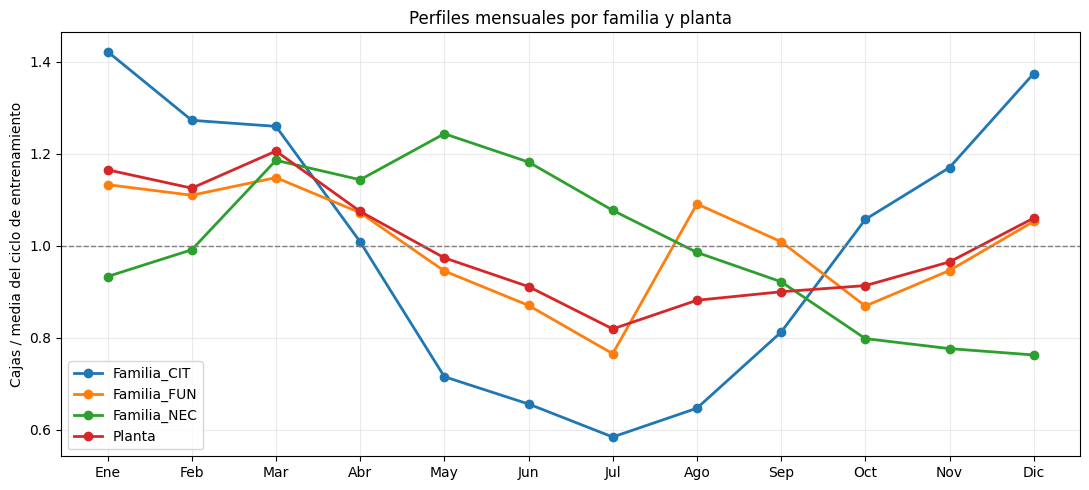


Compensación de errores al sumar hacia la planta:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Metodo,Observaciones_comunes_planta,Suma_error_abs_SKU,Suma_error_abs_planta,Compensacion_error_pct
0,Bottom-Up,67,255741.84,129915.52,49.20
1,Top-Down,67,314451.52,148191.14,52.87
2,Middle-Out,67,254286.72,134614.40,47.06



Análisis de estacionalidad y compensación completado.


In [53]:
import matplotlib.pyplot as plt

# Perfiles estacionales usando las primeras 104 semanas.
columnas_perfil = [
    "Familia_CIT", "Familia_FUN", "Familia_NEC", "Planta"
]

historia_perfil = train_nodos_ejemplo[columnas_perfil].copy()
ciclos = np.arange(len(historia_perfil)) // 52

medias_por_ciclo = historia_perfil.groupby(ciclos).transform("mean")
assert (medias_por_ciclo > 0).all().all()

historia_normalizada = historia_perfil / medias_por_ciclo
historia_normalizada["Mes"] = historia_normalizada.index.month

perfiles_mensuales = (
    historia_normalizada.groupby("Mes")[columnas_perfil]
    .mean()
    .reindex(range(1, 13))
)

print("Perfiles mensuales normalizados:")
display(perfiles_mensuales.round(3))

print("\nCorrelación entre los perfiles mensuales de las familias:")
display(
    perfiles_mensuales[
        ["Familia_CIT", "Familia_FUN", "Familia_NEC"]
    ].corr().round(3)
)

meses = [
    "Ene", "Feb", "Mar", "Abr", "May", "Jun",
    "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"
]

fig, ax = plt.subplots(figsize=(11, 5))

for columna in columnas_perfil:
    ax.plot(
        range(1, 13),
        perfiles_mensuales[columna],
        marker="o",
        label=columna,
        linewidth=2
    )

ax.axhline(1, color="gray", linestyle="--", linewidth=1)
ax.set_xticks(range(1, 13))
ax.set_xticklabels(meses)
ax.set_ylabel("Cajas / media del ciclo de entrenamiento")
ax.set_title("Perfiles mensuales por familia y planta")
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

# Compensación de errores sobre fechas comunes y observables.
filas_compensacion = []

for metodo in METODOS_JERARQUIA:
    resultados_metodo = resultados_jerarquia.loc[
        resultados_jerarquia["Metodo"] == metodo
    ]

    planta_observable = resultados_metodo.loc[
        (resultados_metodo["Nodo"] == "Planta")
        & resultados_metodo["Observable"]
    ].copy()

    claves_comunes = planta_observable[["Ventana", "Fecha"]]

    sku_comunes = resultados_metodo.loc[
        resultados_metodo["Nivel"] == "SKU"
    ].merge(
        claves_comunes,
        on=["Ventana", "Fecha"],
        how="inner",
        validate="many_to_one"
    )

    assert sku_comunes["Observable"].all()
    assert len(sku_comunes) == 9 * len(planta_observable)

    error_sku = sku_comunes["Pronostico"] - sku_comunes["Real"]
    error_planta = (
        planta_observable["Pronostico"] - planta_observable["Real"]
    )

    suma_error_abs_sku = error_sku.abs().sum()
    suma_error_abs_planta = error_planta.abs().sum()

    compensacion = (
        100 * (1 - suma_error_abs_planta / suma_error_abs_sku)
        if suma_error_abs_sku > 0 else np.nan
    )

    filas_compensacion.append({
        "Metodo": metodo,
        "Observaciones_comunes_planta": len(planta_observable),
        "Suma_error_abs_SKU": suma_error_abs_sku,
        "Suma_error_abs_planta": suma_error_abs_planta,
        "Compensacion_error_pct": compensacion
    })

compensacion_jerarquia = pd.DataFrame(filas_compensacion)

print("\nCompensación de errores al sumar hacia la planta:")
display(compensacion_jerarquia.round(2))

print("\nAnálisis de estacionalidad y compensación completado.")

### Conclusiones del punto 5

Se compararon Bottom-Up, Top-Down y Middle-Out en ocho ventanas temporales con un horizonte de 13 semanas, manteniendo coherencia entre planta, familias y SKU.

#### Comparación de métodos

Bottom-Up obtuvo el menor WAPE global en los tres niveles:

| Nivel | Bottom-Up | Middle-Out | Top-Down |
|---|---:|---:|---:|
| Planta | 12,94 % | 13,41 % | 14,76 % |
| Familias | 17,43 % | 19,18 % | 26,75 % |
| SKU | 22,44 % | 22,75 % | 29,64 % |

También obtuvo el menor MASE global: 1,130 en planta, 1,023 en familias y 0,966 en SKU. Por estos resultados, se selecciona Bottom-Up como método para continuar con el pronóstico final.

Middle-Out fue una alternativa cercana: mejoró el WAPE de CIT-L15, FUN-B05, FUN-B15, NEC-D05 y NEC-D15. Además, obtuvo el menor WAPE para la familia FUN: 15,69 %, frente a 15,86 % de Bottom-Up. Sin embargo, no superó su desempeño global.

Top-Down presentó el mayor WAPE global en los tres niveles. Su distribución mediante proporciones fijas obliga a todos los SKU a seguir la misma trayectoria relativa del pronóstico de planta, lo que limita la representación de patrones estacionales diferentes.

La selección corresponde a las implementaciones evaluadas: Bottom-Up utiliza los modelos seleccionados por SKU, mientras que Top-Down y Middle-Out utilizan HW aditivo en sus respectivos niveles de origen. Por tanto, el resultado no demuestra que Bottom-Up sea superior bajo cualquier configuración de modelos.

#### Estacionalidad y agregación

Los perfiles mensuales de las primeras 104 semanas de entrenamiento muestran diferencias entre familias. CIT presenta valores elevados en verano, especialmente en diciembre y enero, y menores valores en invierno. NEC presenta mayores valores entre marzo y junio, con su máximo en mayo.

La correlación entre los perfiles mensuales de CIT y NEC fue −0,467. Esto muestra una oposición parcial entre sus patrones, compatible con una compensación estacional al sumarlos. El patrón de NEC es compatible con el período escolar, pero este análisis descriptivo no demuestra que el calendario escolar cause ese comportamiento.

El perfil normalizado de planta varió aproximadamente entre 0,819 y 1,200, mientras que CIT varió entre 0,585 y 1,422. La agregación atenúa parte de las fluctuaciones visibles en CIT, aunque la planta mantiene estacionalidad.

FUN presentó una correlación de 0,618 con CIT y de −0,014 con NEC. Estas correlaciones describen doce valores mensuales de dos ciclos de entrenamiento; no constituyen una prueba causal.

#### Compensación de errores

Sobre las mismas 67 observaciones de ventana y fecha con los nueve SKU observables, la agregación redujo la suma de errores absolutos respecto de la suma de errores absolutos individuales:

| Método | Compensación de errores |
|---|---:|
| Bottom-Up | 49,20 % |
| Top-Down | 52,87 % |
| Middle-Out | 47,06 % |

Esta reducción ocurre porque las sobreestimaciones de algunos SKU compensan las subestimaciones de otros. La compensación de errores es distinta de la compensación estacional.

Top-Down obtuvo el mayor porcentaje de compensación, pero también mayores errores absolutos individuales y de planta que Bottom-Up. Por ello, una mayor compensación no implica un mejor pronóstico.

#### Sesgo y limitaciones

Los tres métodos subestimaron en promedio el total de planta. El sesgo medio fue de −1.061,08 cajas para Bottom-Up, −577,38 para Top-Down y −552,15 para Middle-Out. Así, Bottom-Up obtuvo menor error global, pero Middle-Out presentó menor sesgo absoluto en planta.

FUN-B30 continuó siendo el SKU más difícil, con un WAPE de 162,36 % en Bottom-Up. El buen resultado agregado no elimina esta dificultad individual.

Las métricas se calcularon únicamente sobre ventas observables. La planta tuvo 67 observaciones evaluables de las 104 previstas por método; las ventanas se superponen, por lo que estas observaciones no equivalen a 67 semanas independientes.

Los resultados corresponden a validación y están condicionados a la selección provisional del punto 4. No permiten verificar directamente la demanda no observada durante las faltas de stock ni constituyen una evaluación independiente posterior a la selección.

## Punto 6. Pronóstico final e intervalos de predicción

Se generan pronósticos para las próximas 13 semanas mediante Bottom-Up, seleccionado en el punto 5. Se mantienen los modelos y tratamientos por SKU definidos previamente y se utiliza toda la historia disponible para el entrenamiento final.

### Parte 1. Pronóstico final coherente

In [54]:
# Entrenar con toda la historia disponible.
n_semanas_final = len(fechas_jerarquia)

train_sku_final, train_nodos_final = (
    preparar_entrenamiento_jerarquico(n_semanas_final)
)

# Generar las próximas 13 semanas.
pronostico_final_nodos = pronosticar_bottom_up(
    train_sku_final,
    h=13
)

pronostico_final_sku = pronostico_final_nodos[
    skus_jerarquia
].copy()

# Comprobar que todas las fechas son posteriores a la historia.
ultima_fecha_historica = fechas_jerarquia.max()

assert pronostico_final_nodos.index.min() == (
    ultima_fecha_historica + pd.Timedelta(weeks=1)
)
assert (pronostico_final_nodos.index > ultima_fecha_historica).all()
assert pronostico_final_nodos.shape == (13, 13)

print("Semanas utilizadas para entrenar:", n_semanas_final)
print("Última fecha histórica:", ultima_fecha_historica.date())
print(
    "Inicio del pronóstico:",
    pronostico_final_nodos.index.min().date()
)
print(
    "Fin del pronóstico:",
    pronostico_final_nodos.index.max().date()
)

print("\nPronóstico final por SKU, en cajas:")
display(pronostico_final_sku.round(2))

print("\nPronóstico final por familia y planta, en cajas:")
display(
    pronostico_final_nodos[
        ["Planta", "Familia_CIT", "Familia_FUN", "Familia_NEC"]
    ].round(2)
)

print(
    "\nParte 1 completada: pronósticos de 13 semanas "
    "coherentes entre SKU, familias y planta."
)

Semanas utilizadas para entrenar: 156
Última fecha histórica: 2026-09-21
Inicio del pronóstico: 2026-09-28
Fin del pronóstico: 2026-12-21

Pronóstico final por SKU, en cajas:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,CIT-L05,CIT-L15,CIT-L30,FUN-B05,FUN-B15,FUN-B30,NEC-D05,NEC-D15,NEC-D30
Fecha,,,,,,,,,
2026-09-28,1392.0,1845.27,361.00,2068.49,1474.95,0.0,1235.68,1964.87,530.33
2026-10-05,1753.0,2216.69,427.00,2866.55,1519.54,0.0,1037.69,2115.76,495.33
2026-10-12,2080.0,2043.99,384.33,2317.19,1532.46,320.0,1222.00,2004.31,491.33
2026-10-19,1740.0,2458.63,445.33,2453.32,1874.46,301.0,1357.00,2178.58,549.00
2026-10-26,2042.0,2926.99,440.00,2334.97,1501.47,0.0,1089.02,1730.47,523.00
2026-11-02,2097.0,2446.65,499.33,2433.61,1658.60,0.0,1171.35,2432.36,406.33
2026-11-09,2126.0,2892.37,582.33,2375.77,1620.07,324.0,1178.00,1798.92,489.00
2026-11-16,3321.0,2567.35,511.67,2569.26,1724.40,0.0,1260.34,1975.18,419.66
2026-11-23,2326.0,3228.34,500.00,2919.81,1632.59,0.0,926.67,2057.85,567.66



Pronóstico final por familia y planta, en cajas:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Planta,Familia_CIT,Familia_FUN,Familia_NEC
Fecha,,,,
2026-09-28,10872.59,3598.27,3543.44,3730.88
2026-10-05,12431.57,4396.69,4386.10,3648.78
2026-10-12,12395.62,4508.33,4169.65,3717.64
2026-10-19,13357.33,4643.97,4628.78,4084.58
2026-10-26,12587.92,5408.99,3836.45,3342.49
2026-11-02,13145.23,5042.98,4092.21,4010.04
2026-11-09,13386.47,5600.70,4319.84,3465.92
2026-11-16,14348.86,6400.02,4293.66,3655.18
2026-11-23,14158.93,6054.34,4552.40,3552.19



Parte 1 completada: pronósticos de 13 semanas coherentes entre SKU, familias y planta.


### Parte 2. Intervalos de predicción del 80 % y 95 %

Se construyen intervalos empíricos alrededor del pronóstico puntual utilizando los errores absolutos de Bottom-Up sobre ventas observables de la validación temporal.

Para cada nodo, los márgenes corresponden a los cuantiles 0,80 y 0,95 de sus errores absolutos. Se utiliza el método de cuantil “higher”, que toma un valor observado igual o superior al cuantil solicitado. Los límites inferiores se restringen a cero.

Se agrupan los errores de los 13 horizontes para disponer de una mayor muestra. Por ello, el margen de cada nodo es constante entre horizontes. El método supone que la magnitud de los errores históricos es representativa del período futuro.

Los niveles del 80 % y 95 % son nominales: no garantizan esa cobertura futura. Las ventanas superpuestas producen errores dependientes y la selección de modelos utilizó esta misma validación.

Los pronósticos puntuales mantienen coherencia jerárquica. Los límites son marginales para cada nodo y no se suman entre niveles; tampoco representan cobertura simultánea de todos los SKU y semanas.

La calibración utiliza únicamente ventas observables y no incorpora de forma completa la incertidumbre de la demanda no observada durante faltas de stock.

In [55]:
# Errores de Bottom-Up sobre observaciones evaluables.
errores_intervalos = resultados_jerarquia.loc[
    (resultados_jerarquia["Metodo"] == "Bottom-Up")
    & resultados_jerarquia["Observable"]
].copy()

errores_intervalos["Error_abs"] = (
    errores_intervalos["Real"]
    - errores_intervalos["Pronostico"]
).abs()

assert np.isfinite(errores_intervalos["Error_abs"]).all()
assert errores_intervalos["Fecha"].max() < (
    pronostico_final_nodos.index.min()
)


def calcular_margenes_intervalos(errores):
    registros = []

    for nodo, grupo in errores.groupby("Nodo"):
        valores = grupo["Error_abs"].to_numpy(dtype=float)

        if len(valores) == 0:
            raise ValueError(f"No hay errores disponibles para {nodo}.")

        registros.append({
            "Nodo": nodo,
            "Margen_80": np.quantile(
                valores, 0.80, method="higher"
            ),
            "Margen_95": np.quantile(
                valores, 0.95, method="higher"
            ),
            "N_errores": len(valores),
            "N_fechas_distintas": grupo["Fecha"].nunique()
        })

    return pd.DataFrame(registros).set_index("Nodo")


margenes_intervalos = calcular_margenes_intervalos(
    errores_intervalos
).reindex(nodos_jerarquia)

assert margenes_intervalos.notna().all().all()
assert (
    margenes_intervalos["Margen_95"]
    >= margenes_intervalos["Margen_80"]
).all()

registros_intervalos_finales = []

for horizonte, fecha in enumerate(
    pronostico_final_nodos.index, start=1
):
    for nodo in nodos_jerarquia:
        puntual = float(pronostico_final_nodos.loc[fecha, nodo])
        margen_80 = float(margenes_intervalos.loc[nodo, "Margen_80"])
        margen_95 = float(margenes_intervalos.loc[nodo, "Margen_95"])

        nivel = (
            "Planta" if nodo == "Planta"
            else "Familia" if nodo.startswith("Familia_")
            else "SKU"
        )

        registros_intervalos_finales.append({
            "Fecha": fecha,
            "Horizonte": horizonte,
            "Nivel": nivel,
            "Nodo": nodo,
            "Pronostico": puntual,
            "LI_80": max(0.0, puntual - margen_80),
            "LS_80": puntual + margen_80,
            "LI_95": max(0.0, puntual - margen_95),
            "LS_95": puntual + margen_95
        })

intervalos_finales = pd.DataFrame(registros_intervalos_finales)

# Comprobar límites y anidamiento de los intervalos.
assert len(intervalos_finales) == 13 * 13

assert (
    intervalos_finales["LI_95"] <= intervalos_finales["LI_80"]
).all()
assert (
    intervalos_finales["LI_80"] <= intervalos_finales["Pronostico"]
).all()
assert (
    intervalos_finales["Pronostico"] <= intervalos_finales["LS_80"]
).all()
assert (
    intervalos_finales["LS_80"] <= intervalos_finales["LS_95"]
).all()

print("Márgenes y cantidad de errores utilizados por nodo:")
display(margenes_intervalos.round(2))

print("\nEjemplo: intervalos de la primera semana para los nueve SKU:")
display(
    intervalos_finales.loc[
        (intervalos_finales["Nivel"] == "SKU")
        & (intervalos_finales["Horizonte"] == 1)
    ].round(2)
)

print(
    "\nParte 2 completada: intervalos del 80 % y 95 % "
    "para 13 semanas y 13 nodos."
)

Márgenes y cantidad de errores utilizados por nodo:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Margen_80,Margen_95,N_errores,N_fechas_distintas
Nodo,,,,
Planta,1777.71,3477.95,67,32
Familia_CIT,1099.72,1962.02,104,48
Familia_FUN,1018.12,1578.75,67,32
Familia_NEC,966.54,1797.63,104,48
CIT-L05,446.00,1529.00,104,48
CIT-L15,872.43,1218.02,104,48
CIT-L30,117.50,173.50,104,48
FUN-B05,756.84,1365.96,104,48
FUN-B15,512.43,1166.08,98,46



Ejemplo: intervalos de la primera semana para los nueve SKU:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Fecha,Horizonte,Nivel,Nodo,Pronostico,LI_80,LS_80,LI_95,LS_95
4,2026-09-28,1,SKU,CIT-L05,1392.00,946.00,1838.00,0.00,2921.00
5,2026-09-28,1,SKU,CIT-L15,1845.27,972.85,2717.70,627.25,3063.30
6,2026-09-28,1,SKU,CIT-L30,361.00,243.51,478.50,187.50,534.50
7,2026-09-28,1,SKU,FUN-B05,2068.49,1311.64,2825.33,702.53,3434.44
8,2026-09-28,1,SKU,FUN-B15,1474.95,962.51,1987.38,308.87,2641.03
9,2026-09-28,1,SKU,FUN-B30,0.00,0.00,238.00,0.00,277.00
10,2026-09-28,1,SKU,NEC-D05,1235.68,678.68,1792.67,352.66,2118.69
11,2026-09-28,1,SKU,NEC-D15,1964.87,1031.74,2898.00,190.24,3739.50
12,2026-09-28,1,SKU,NEC-D30,530.33,371.83,688.83,252.33,808.34



Parte 2 completada: intervalos del 80 % y 95 % para 13 semanas y 13 nodos.


### Parte 3. Revisión temporal de la cobertura

Se evalúa la cobertura de los intervalos mediante una calibración temporal progresiva. Para cada nodo y ventana, se utilizan únicamente errores de ventanas anteriores con fechas de observación anteriores al corte actual.

Se exige un mínimo de 20 registros de error para calcular los márgenes. Las ventanas sin suficientes errores previos se excluyen de esta revisión y se informa cuántas observaciones pudieron evaluarse.

La cobertura corresponde al porcentaje de ventas observables que quedó dentro de cada intervalo. También se informa su ancho medio.

Esta revisión evita utilizar resultados futuros para calibrar los márgenes, pero continúa condicionada a los modelos y tratamientos seleccionados en el punto 4. Los errores se encuentran relacionados por la superposición de ventanas; 20 registros no equivalen a 20 observaciones independientes.

In [56]:
MIN_ERRORES_CALIBRACION = 20
registros_cobertura_intervalos = []

for _, ventana in ventanas_jerarquia.iterrows():
    numero_ventana = int(ventana["Ventana"])
    corte = pd.Timestamp(ventana["Corte"])

    # Solo errores anteriores y conocidos antes del corte.
    errores_previos = errores_intervalos.loc[
        (errores_intervalos["Ventana"] < numero_ventana)
        & (errores_intervalos["Fecha"] < corte)
    ].copy()

    evaluacion_actual = errores_intervalos.loc[
        errores_intervalos["Ventana"] == numero_ventana
    ].copy()

    for nodo, grupo_actual in evaluacion_actual.groupby("Nodo"):
        calibracion = errores_previos.loc[
            errores_previos["Nodo"] == nodo
        ]

        if len(calibracion) < MIN_ERRORES_CALIBRACION:
            continue

        assert calibracion["Fecha"].max() < corte

        errores = calibracion["Error_abs"].to_numpy()
        margen_80 = np.quantile(errores, 0.80, method="higher")
        margen_95 = np.quantile(errores, 0.95, method="higher")

        for _, fila in grupo_actual.iterrows():
            puntual = float(fila["Pronostico"])
            real = float(fila["Real"])

            li_80 = max(0.0, puntual - margen_80)
            ls_80 = puntual + margen_80
            li_95 = max(0.0, puntual - margen_95)
            ls_95 = puntual + margen_95

            registros_cobertura_intervalos.append({
                "Ventana": numero_ventana,
                "Fecha": fila["Fecha"],
                "Horizonte": fila["Horizonte"],
                "Nivel": fila["Nivel"],
                "Nodo": nodo,
                "N_errores_calibracion": len(calibracion),
                "Dentro_80": li_80 <= real <= ls_80,
                "Dentro_95": li_95 <= real <= ls_95,
                "Ancho_80": ls_80 - li_80,
                "Ancho_95": ls_95 - li_95
            })

evaluacion_intervalos = pd.DataFrame(
    registros_cobertura_intervalos
)

if evaluacion_intervalos.empty:
    raise ValueError(
        "No hay suficientes errores previos para revisar la cobertura."
    )

assert (
    ~evaluacion_intervalos["Dentro_80"]
    | evaluacion_intervalos["Dentro_95"]
).all()

cobertura_intervalos_nodo = (
    evaluacion_intervalos.groupby(["Nivel", "Nodo"])
    .agg(
        Ventanas_evaluadas=("Ventana", "nunique"),
        N_evaluados=("Dentro_80", "size"),
        Fechas_distintas=("Fecha", "nunique"),
        Cobertura_80_pct=("Dentro_80", "mean"),
        Cobertura_95_pct=("Dentro_95", "mean"),
        Ancho_medio_80=("Ancho_80", "mean"),
        Ancho_medio_95=("Ancho_95", "mean")
    )
    .reset_index()
)

for columna in ["Cobertura_80_pct", "Cobertura_95_pct"]:
    cobertura_intervalos_nodo[columna] *= 100

# Informar las observaciones que no pudieron evaluarse
# por insuficiencia de errores previos.
disponibles_por_nodo = errores_intervalos.groupby("Nodo").size()

cobertura_intervalos_nodo["N_observables_disponibles"] = (
    cobertura_intervalos_nodo["Nodo"].map(disponibles_por_nodo)
)

cobertura_intervalos_nodo["N_sin_calibracion_suficiente"] = (
    cobertura_intervalos_nodo["N_observables_disponibles"]
    - cobertura_intervalos_nodo["N_evaluados"]
)

# Conservar el detalle de cobertura por horizonte.
cobertura_intervalos_horizonte = (
    evaluacion_intervalos.groupby(["Nivel", "Nodo", "Horizonte"])
    .agg(
        N_evaluados=("Dentro_80", "size"),
        Cobertura_80_pct=("Dentro_80", "mean"),
        Cobertura_95_pct=("Dentro_95", "mean")
    )
    .reset_index()
)

for columna in ["Cobertura_80_pct", "Cobertura_95_pct"]:
    cobertura_intervalos_horizonte[columna] *= 100

# Revisar nuevamente la coherencia de los pronósticos finales.
columnas_familias = [
    f"Familia_{familia}" for familia in familias_jerarquia
]

assert np.allclose(
    pronostico_final_nodos["Planta"],
    pronostico_final_nodos[columnas_familias].sum(axis=1)
)

assert np.allclose(
    pronostico_final_nodos["Planta"],
    pronostico_final_nodos[skus_jerarquia].sum(axis=1)
)

columnas_numericas = [
    "Pronostico", "LI_80", "LS_80", "LI_95", "LS_95"
]

assert np.isfinite(
    intervalos_finales[columnas_numericas].to_numpy()
).all()

print("Cobertura histórica por nodo:")
display(cobertura_intervalos_nodo.round(2))

print(
    "\nParte 3 completada: cobertura histórica calculada "
    "y coherencia de los pronósticos finales verificada."
)

Cobertura histórica por nodo:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Nivel,Nodo,Ventanas_evaluadas,N_evaluados,Fechas_distintas,Cobertura_80_pct,Cobertura_95_pct,Ancho_medio_80,Ancho_medio_95,N_observables_disponibles,N_sin_calibracion_suficiente
0,Familia,Familia_CIT,5,65,33,93.85,100.00,2903.56,10498.49,104,39
1,Familia,Familia_FUN,4,36,21,83.33,100.00,2334.05,3341.75,67,31
2,Familia,Familia_NEC,5,65,33,69.23,89.23,1612.54,3162.99,104,39
3,Planta,Planta,4,36,21,83.33,94.44,3844.81,25551.48,67,31
4,SKU,CIT-L05,5,65,33,86.15,100.00,1071.20,9800.25,104,39
5,SKU,CIT-L15,5,65,33,92.31,98.46,1895.66,2903.71,104,39
6,SKU,CIT-L30,5,65,33,90.77,96.92,274.60,441.08,104,39
7,SKU,FUN-B05,5,65,33,84.62,100.00,1583.00,3089.85,104,39
8,SKU,FUN-B15,5,64,32,78.12,87.50,1014.92,1780.87,98,34
9,SKU,FUN-B30,4,36,21,63.89,83.33,271.42,396.33,70,34



Parte 3 completada: cobertura histórica calculada y coherencia de los pronósticos finales verificada.


In [57]:
from pathlib import Path
import shutil
from google.colab import files

carpeta_resultados = Path("/content/resultados_Entrega1_ParteB")
carpeta_resultados.mkdir(parents=True, exist_ok=True)

tabla_final_sku = (
    intervalos_finales.loc[intervalos_finales["Nivel"] == "SKU"]
    .rename(columns={"Nodo": "SKU"})
    .sort_values(["SKU", "Horizonte"])
    .reset_index(drop=True)
)

tabla_final_agregados = (
    intervalos_finales.loc[intervalos_finales["Nivel"] != "SKU"]
    .sort_values(["Nivel", "Nodo", "Horizonte"])
    .reset_index(drop=True)
)

assert len(tabla_final_sku) == 117
assert len(tabla_final_agregados) == 52
assert (tabla_final_sku.groupby("SKU").size() == 13).all()

tablas_exportar = {
    "pronosticos_SKU_intervalos": tabla_final_sku,
    "pronosticos_familias_planta_intervalos": tabla_final_agregados,
    "cobertura_intervalos_por_nodo": cobertura_intervalos_nodo,
    "cobertura_intervalos_por_horizonte": cobertura_intervalos_horizonte,
    "comparacion_jerarquica_por_nodo": metricas_jerarquia_nodo,
    "comparacion_jerarquica_por_nivel": metricas_jerarquia_nivel,
    "modelos_y_tratamientos_seleccionados": seleccion_provisional
}

for nombre, tabla in tablas_exportar.items():
    tabla.to_csv(
        carpeta_resultados / f"{nombre}.csv",
        index=False,
        encoding="utf-8-sig",
        date_format="%Y-%m-%d"
    )

print("Resumen de pronósticos por SKU:")
display(
    tabla_final_sku.groupby("SKU").agg(
        Semanas=("Horizonte", "size"),
        Total_cajas_13_semanas=("Pronostico", "sum"),
        Promedio_semanal_cajas=("Pronostico", "mean")
    ).round(2)
)

ruta_zip = shutil.make_archive(
    "/content/resultados_Entrega1_ParteB",
    "zip",
    root_dir=carpeta_resultados
)

print("\nTablas finales preparadas:")
print("- 117 pronósticos por SKU con intervalos.")
print("- 52 pronósticos por familia y planta con intervalos.")
print("- Cobertura histórica, comparación y selección de modelos.")
print("\nDescargando resultados...")

files.download(ruta_zip)

Resumen de pronósticos por SKU:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Semanas,Total_cajas_13_semanas,Promedio_semanal_cajas
SKU,,,
CIT-L05,13,29055.00,2235.00
CIT-L15,13,34665.88,2666.61
CIT-L30,13,6472.00,497.85
FUN-B05,13,33081.88,2544.76
FUN-B15,13,21772.63,1674.82
FUN-B30,13,1269.00,97.62
NEC-D05,13,15309.81,1177.68
NEC-D15,13,26533.63,2041.05
NEC-D30,13,6415.32,493.49



Tablas finales preparadas:
- 117 pronósticos por SKU con intervalos.
- 52 pronósticos por familia y planta con intervalos.
- Cobertura histórica, comparación y selección de modelos.

Descargando resultados...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Conclusiones del punto 6

Se generaron pronósticos para los nueve SKU durante las 13 semanas comprendidas entre el 28 de septiembre y el 21 de diciembre de 2026. El entrenamiento final utilizó las 156 semanas disponibles, conservando los modelos y tratamientos seleccionados previamente.

Se aplicó Bottom-Up, seleccionado por su menor WAPE global en el punto 5. Los pronósticos de las familias y la planta corresponden a la suma de sus SKU, y se verificó su coherencia antes del redondeo de presentación.

#### Intervalos de predicción

Se construyeron intervalos empíricos con niveles nominales del 80 % y 95 %, utilizando cuantiles de los errores absolutos de validación de Bottom-Up. Los límites inferiores se restringieron a cero.

Los intervalos son marginales para cada nodo. Sus límites no se suman entre niveles y no ofrecen cobertura simultánea de los nueve SKU y las 13 semanas.

#### Cobertura histórica

La cobertura se revisó de forma temporal progresiva, calibrando cada ventana únicamente con errores anteriores ya observados. Se exigieron al menos 20 registros de error previos.

| Nodo | Observaciones evaluadas | Cobertura del intervalo 80 % | Cobertura del intervalo 95 % |
|---|---:|---:|---:|
| Planta | 36 | 83,33 % | 94,44 % |
| Familia CIT | 65 | 93,85 % | 100,00 % |
| Familia FUN | 36 | 83,33 % | 100,00 % |
| Familia NEC | 65 | 69,23 % | 89,23 % |
| CIT-L05 | 65 | 86,15 % | 100,00 % |
| CIT-L15 | 65 | 92,31 % | 98,46 % |
| CIT-L30 | 65 | 90,77 % | 96,92 % |
| FUN-B05 | 65 | 84,62 % | 100,00 % |
| FUN-B15 | 64 | 78,12 % | 87,50 % |
| FUN-B30 | 36 | 63,89 % | 83,33 % |
| NEC-D05 | 65 | 66,15 % | 93,85 % |
| NEC-D15 | 65 | 53,85 % | 89,23 % |
| NEC-D30 | 65 | 64,62 % | 83,08 % |

La cobertura de planta se aproximó a los niveles nominales. Sin embargo, FUN-B30 y los SKU de NEC mostraron coberturas inferiores, especialmente para el intervalo del 80 %. Por lo tanto, el método no quedó adecuadamente calibrado para todos los productos.

Una cobertura elevada tampoco implica por sí sola un intervalo útil: CIT-L05 presentó un ancho medio histórico de 9.800,25 cajas para el intervalo del 95 %. Los errores extremos presentes en la calibración pueden producir intervalos muy amplios.

#### Limitaciones e interpretación

Los márgenes finales se estimaron con todos los errores de validación disponibles, mientras que la revisión histórica utilizó muestras progresivas más pequeñas. Su cobertura histórica no garantiza la cobertura de los intervalos finales.

Se agruparon errores de distintos horizontes y se mantuvo un margen constante por nodo. Esto simplifica la estimación, pero no representa diferencias de incertidumbre entre semanas cercanas y lejanas.

Las ventanas se superponen, por lo que las observaciones evaluadas no son independientes. Además, los modelos y tratamientos se seleccionaron utilizando la misma validación; la cobertura reportada no constituye una prueba independiente posterior a la selección.

La evaluación se limitó a ventas observables. Los intervalos no incorporan completamente la incertidumbre de la reconstrucción de demanda durante faltas de stock, ni posibles promociones futuras o cambios de comportamiento.

En FUN-B30, un pronóstico puntual de cero reproduce el patrón del ingenuo estacional y no implica certeza de demanda nula. Sus intervalos positivos reflejan parte de la incertidumbre histórica.

Se entregan los pronósticos puntuales coherentes, los intervalos nominales y su cobertura histórica, manteniendo explícitas las dificultades de calibración identificadas.